<a href="https://colab.research.google.com/github/joserafaelfranco/-rainfall_characterization/blob/main/Codigo_chuva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================================
# 2.1. DAILY PRECIPITATION DATASET AND QUALITY CONTROL
# Study area: Botucatu, São Paulo, Brazil
# Study period: January 1, 1971 – December 31, 2024
#
# Purpose:
# Import the previously cleaned daily precipitation dataset
# and verify its temporal coverage and data integrity.
#
# No missing observations are imputed.
# No precipitation values are modified.
# ============================================================

import pandas as pd
import numpy as np
from google.colab import files

# ------------------------------------------------------------
# Step 1. Upload the cleaned dataset
# ------------------------------------------------------------

print("Upload the cleaned Excel precipitation dataset.")

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one Excel file.")

file_name = next(iter(uploaded))

# Read the first worksheet
data = pd.read_excel(file_name, sheet_name=0)

# ------------------------------------------------------------
# Step 2. Verify required columns
# ------------------------------------------------------------

required_columns = ["Data", "Precipitacao_mm"]

if not all(col in data.columns for col in required_columns):
    raise ValueError(
        f"The dataset must contain: {required_columns}"
    )

data = data[required_columns].copy()

# ------------------------------------------------------------
# Step 3. Standardize data types
# ------------------------------------------------------------

data["Data"] = pd.to_datetime(
    data["Data"],
    errors="coerce",
    dayfirst=True
).dt.normalize()

data["Precipitacao_mm"] = pd.to_numeric(
    data["Precipitacao_mm"],
    errors="coerce"
)

if data["Data"].isna().any():
    raise ValueError(
        "The dataset contains invalid or missing dates."
    )

# ------------------------------------------------------------
# Step 4. Verify the study period
# ------------------------------------------------------------

start_date = pd.Timestamp("1971-01-01")
end_date = pd.Timestamp("2024-12-31")

if not data["Data"].between(start_date, end_date).all():
    raise ValueError(
        "Dates outside the study period were detected."
    )

# ------------------------------------------------------------
# Step 5. Verify duplicated dates
# ------------------------------------------------------------

duplicated_dates = data["Data"].duplicated().sum()

if duplicated_dates > 0:
    raise ValueError(
        f"{duplicated_dates} duplicated dates were detected. "
        "The input dataset must already be cleaned."
    )

# ------------------------------------------------------------
# Step 6. Verify physically inconsistent values
# ------------------------------------------------------------

negative_values = (
    data["Precipitacao_mm"] < 0
).sum()

if negative_values > 0:
    raise ValueError(
        f"{negative_values} negative precipitation values "
        "were detected."
    )

# ------------------------------------------------------------
# Step 7. Verify calendar coverage
# ------------------------------------------------------------

complete_calendar = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

# Align observations with the complete daily calendar.
# Unavailable observations remain NaN.
# This operation does not impute rainfall values.

dados_limpos = (
    data.set_index("Data")
        .reindex(complete_calendar)
        .rename_axis("Data")
        .reset_index()
)

# ------------------------------------------------------------
# Step 8. Identify missing observations
# ------------------------------------------------------------

missing_dates = dados_limpos.loc[
    dados_limpos["Precipitacao_mm"].isna(),
    ["Data"]
].copy()

# ------------------------------------------------------------
# Step 9. Identify complete calendar years
# ------------------------------------------------------------

dados_limpos["Ano"] = dados_limpos["Data"].dt.year

yearly_coverage = (
    dados_limpos.groupby("Ano")
    .agg(
        Expected_days=("Data", "size"),
        Valid_days=("Precipitacao_mm", "count")
    )
    .reset_index()
)

yearly_coverage["Complete"] = (
    yearly_coverage["Expected_days"]
    == yearly_coverage["Valid_days"]
)

complete_years = yearly_coverage.loc[
    yearly_coverage["Complete"], "Ano"
].tolist()

incomplete_years = yearly_coverage.loc[
    ~yearly_coverage["Complete"], "Ano"
].tolist()

# ------------------------------------------------------------
# Step 10. Display data quality-control results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DAILY PRECIPITATION DATA QUALITY CONTROL")
print("=" * 65)

print(f"Study period: {start_date.date()} to {end_date.date()}")
print(f"Expected calendar days: {len(complete_calendar)}")
print(f"Original input rows: {len(data)}")

print(
    "Valid precipitation observations:",
    dados_limpos["Precipitacao_mm"].notna().sum()
)

print("Missing observations:", len(missing_dates))
print("Duplicated dates:", duplicated_dates)
print("Negative precipitation values:", negative_values)

print("\nComplete calendar years:", len(complete_years))
print("Incomplete calendar years:", incomplete_years)

print("\nMISSING OBSERVATIONS:")
display(missing_dates)

print("\nYEARLY DATA COVERAGE:")
display(yearly_coverage)

print("\nDATASET READY FOR SUBSEQUENT ANALYSES.")

# The DataFrame 'dados_limpos' will be used
# throughout the following methodological steps.


Upload the cleaned Excel precipitation dataset.


Saving Dados_Chuva_Botucatu_1971_2024.xlsx to Dados_Chuva_Botucatu_1971_2024.xlsx

DAILY PRECIPITATION DATA QUALITY CONTROL
Study period: 1971-01-01 to 2024-12-31
Expected calendar days: 19724
Original input rows: 19712
Valid precipitation observations: 19712
Missing observations: 12
Duplicated dates: 0
Negative precipitation values: 0

Complete calendar years: 50
Incomplete calendar years: [1972, 2014, 2016, 2022]

MISSING OBSERVATIONS:


,Data
578,1972-08-01
579,1972-08-02
15736,2014-01-31
16724,2016-10-15
18708,2022-03-22
18828,2022-07-20
18849,2022-08-10
18867,2022-08-28
18873,2022-09-03
18878,2022-09-08



YEARLY DATA COVERAGE:


,Ano,Expected_days,Valid_days,Complete
0,1971,365,365,True
1,1972,366,364,False
2,1973,365,365,True
3,1974,365,365,True
4,1975,365,365,True
5,1976,366,366,True
6,1977,365,365,True
7,1978,365,365,True
8,1979,365,365,True
9,1980,366,366,True



DATASET READY FOR SUBSEQUENT ANALYSES.


In [ ]:

# ============================================================
# STEP 02 - ANNUAL PRECIPITATION AND RAINY-DAY FREQUENCY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024 (54 calendar years)
#
# Objectives:
# 1. Calculate annual accumulated precipitation (AAP).
# 2. Calculate the annual number of rainy days (ANRD).
# 3. Calculate annual relative rainy-day frequency.
# 4. Calculate descriptive statistics for AAP and ANRD.
#
# All calendar years are included, even when daily
# precipitation observations are incomplete.
#
# Missing precipitation values are not estimated,
# replaced, or treated as zero.
#
# Annual totals for incomplete years represent
# observed totals rather than complete-year totals.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. DEFINE THE RAINY-DAY THRESHOLD
# ------------------------------------------------------------

RAIN_THRESHOLD = 1.0

# Use the quality-controlled dataset from Step 01.
annual_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

annual_data["Data"] = pd.to_datetime(
    annual_data["Data"]
)

annual_data["Ano"] = annual_data["Data"].dt.year

# Classify rainy days while preserving missing values.
annual_data["Rainy_day"] = np.where(
    annual_data["Precipitacao_mm"].notna(),
    (
        annual_data["Precipitacao_mm"]
        >= RAIN_THRESHOLD
    ).astype(int),
    np.nan
)

# ------------------------------------------------------------
# 2. CALCULATE ANNUAL INDICATORS
# ------------------------------------------------------------

annual_indicators = (
    annual_data
    .groupby("Ano")
    .agg(
        Expected_days=("Data", "size"),
        Valid_days=("Precipitacao_mm", "count"),
        AAP_mm=(
            "Precipitacao_mm",
            lambda x: x.sum(min_count=1)
        ),
        ANRD_days=("Rainy_day", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. IDENTIFY COMPLETE AND INCOMPLETE YEARS
# ------------------------------------------------------------

annual_indicators["Complete"] = (
    annual_indicators["Expected_days"]
    == annual_indicators["Valid_days"]
)

annual_indicators["Missing_days"] = (
    annual_indicators["Expected_days"]
    - annual_indicators["Valid_days"]
)

# All 54 years are retained.
anuais_validos = annual_indicators.copy()

# ------------------------------------------------------------
# 4. CALCULATE ANNUAL RAINY-DAY FREQUENCY
# ------------------------------------------------------------

# Relative frequency uses observed days as the
# denominator to avoid classifying missing days
# as dry days.
#
# RF (%) = (ANRD / Valid_days) * 100

anuais_validos["Rainy_day_frequency_percent"] = (
    anuais_validos["ANRD_days"]
    / anuais_validos["Valid_days"]
    * 100
)

# ------------------------------------------------------------
# 5. VERIFY ANNUAL RESULTS
# ------------------------------------------------------------

assert len(anuais_validos) == 54

assert anuais_validos["Ano"].min() == 1971
assert anuais_validos["Ano"].max() == 2024

assert (
    anuais_validos["Valid_days"] > 0
).all()

assert (
    anuais_validos["Rainy_day_frequency_percent"]
    .between(0, 100)
).all()

assert (
    anuais_validos["Missing_days"].sum()
    == 12
)

assert (
    anuais_validos["Complete"].sum()
    == 50
)

# ------------------------------------------------------------
# 6. CALCULATE DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

def descriptive_statistics(values):

    """
    Calculate the descriptive statistics specified
    in the methodology.

    SD is the sample standard deviation (ddof=1).
    CV = (SD / Mean) * 100.
    """

    values = pd.Series(
        values,
        dtype=float
    ).dropna()

    mean = values.mean()
    sd = values.std(ddof=1)

    return {
        "Mean": mean,
        "Median": values.median(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "SD": sd,
        "CV_percent": (
            sd / mean * 100
            if mean != 0 else np.nan
        )
    }

stats_aap = descriptive_statistics(
    anuais_validos["AAP_mm"]
)

stats_anrd = descriptive_statistics(
    anuais_validos["ANRD_days"]
)

# ------------------------------------------------------------
# 7. PREPARE TABLE 1
# ------------------------------------------------------------

tabela1 = pd.DataFrame([
    {
        "Variable": "AAP",
        "Unit": "mm",
        "n": len(anuais_validos),
        **stats_aap
    },
    {
        "Variable": "ANRD",
        "Unit": "days",
        "n": len(anuais_validos),
        **stats_anrd
    }
])

# ------------------------------------------------------------
# 8. IDENTIFY ANNUAL MINIMUM AND MAXIMUM VALUES
# ------------------------------------------------------------

extreme_years = pd.DataFrame([
    {
        "Variable": "AAP",
        "Minimum_year": int(
            anuais_validos.loc[
                anuais_validos["AAP_mm"].idxmin(),
                "Ano"
            ]
        ),
        "Maximum_year": int(
            anuais_validos.loc[
                anuais_validos["AAP_mm"].idxmax(),
                "Ano"
            ]
        )
    },
    {
        "Variable": "ANRD",
        "Minimum_year": int(
            anuais_validos.loc[
                anuais_validos["ANRD_days"].idxmin(),
                "Ano"
            ]
        ),
        "Maximum_year": int(
            anuais_validos.loc[
                anuais_validos["ANRD_days"].idxmax(),
                "Ano"
            ]
        )
    }
])

# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("ANNUAL PRECIPITATION AND RAINY-DAY FREQUENCY")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Calendar years:", len(anuais_validos))

print(
    "Complete years:",
    int(anuais_validos["Complete"].sum())
)

print(
    "Incomplete years:",
    int((~anuais_validos["Complete"]).sum())
)

print("\nANNUAL INDICATORS:")

display(
    anuais_validos[
        [
            "Ano",
            "Expected_days",
            "Valid_days",
            "Missing_days",
            "Complete",
            "AAP_mm",
            "ANRD_days",
            "Rainy_day_frequency_percent"
        ]
    ].round(2)
)

print("\nTABLE 1 - DESCRIPTIVE STATISTICS:")

display(tabela1.round(2))

print("\nYEARS WITH EXTREME VALUES:")

display(extreme_years)

mean_frequency = (
    anuais_validos[
        "Rainy_day_frequency_percent"
    ].mean()
)

print(
    "\nMean annual rainy-day frequency:",
    f"{mean_frequency:.2f}%"
)

# ------------------------------------------------------------
# 10. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_02_Annual_Precipitation_"
    "Rainy_Days_1971_2024_54Years.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    anuais_validos.to_excel(
        writer,
        sheet_name="Annual_Indicators",
        index=False
    )

    tabela1.to_excel(
        writer,
        sheet_name="Table_1",
        index=False
    )

    extreme_years.to_excel(
        writer,
        sheet_name="Extreme_Years",
        index=False
    )

print("\nOutput file:", output_file)

files.download(output_file)


ANNUAL PRECIPITATION AND RAINY-DAY FREQUENCY
BOTUCATU, BRAZIL | 1971-2024
Calendar years: 54
Complete years: 50
Incomplete years: 4

ANNUAL INDICATORS:


,Ano,Expected_days,Valid_days,Missing_days,Complete,AAP_mm,ANRD_days,Rainy_day_frequency_percent
0,1971,365,365,0,True,1116.40,98.0,26.85
1,1972,366,364,2,False,1892.14,123.0,33.79
2,1973,365,365,0,True,1157.84,107.0,29.32
3,1974,365,365,0,True,1449.02,104.0,28.49
4,1975,365,365,0,True,1337.28,90.0,24.66
5,1976,366,366,0,True,1992.19,131.0,35.79
6,1977,365,365,0,True,1462.16,108.0,29.59
7,1978,365,365,0,True,1503.23,95.0,26.03
8,1979,365,365,0,True,1357.48,106.0,29.04
9,1980,366,366,0,True,1610.47,110.0,30.05



TABLE 1 - DESCRIPTIVE STATISTICS:


,Variable,Unit,n,Mean,Median,Minimum,Maximum,SD,CV_percent
0,AAP,mm,54,1524.49,1471.3,964.84,2278.32,279.51,18.33
1,ANRD,days,54,107.04,105.5,80.00,147.00,13.83,12.92



YEARS WITH EXTREME VALUES:


,Variable,Minimum_year,Maximum_year
0,AAP,1984,1983
1,ANRD,2021,1983



Mean annual rainy-day frequency: 29.32%

Output file: Step_02_Annual_Precipitation_Rainy_Days_1971_2024_54Years.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

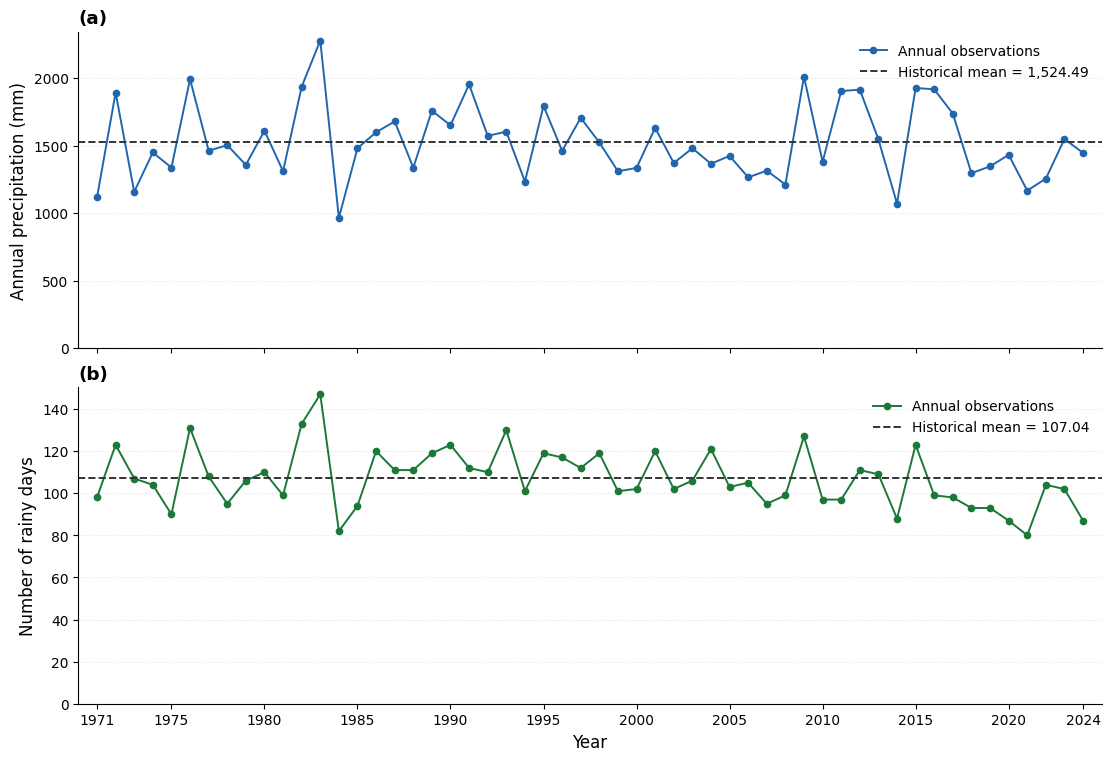

Figure 1 generated successfully.
Years included: 54
Annual mean AAP: 1524.49
Annual mean ANRD: 107.04

Output files:
Figure_1_Annual_Precipitation_Rainy_Days_1971_2024.png
Figure_1_Annual_Precipitation_Rainy_Days_1971_2024.pdf
Figure_1_Annual_Precipitation_Rainy_Days_1971_2024.svg


In [ ]:

# ============================================================
# STEP 03 - ANNUAL PRECIPITATION AND RAINY-DAY VARIABILITY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize annual accumulated precipitation (AAP)
# and annual number of rainy days (ANRD).
#
# All 54 years are represented using the same graphical
# convention and the same calculation procedures.
#
# Missing precipitation observations are not imputed.
# Annual totals for incomplete years represent observed
# precipitation and rainy-day counts only.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. USE ANNUAL RESULTS FROM STEP 02
# ------------------------------------------------------------

annual = (
    anuais_validos
    .sort_values("Ano")
    .reset_index(drop=True)
    .copy()
)

assert len(annual) == 54
assert annual["Ano"].is_unique

mean_aap = float(
    tabela1.loc[
        tabela1["Variable"] == "AAP",
        "Mean"
    ].iloc[0]
)

mean_anrd = float(
    tabela1.loc[
        tabela1["Variable"] == "ANRD",
        "Mean"
    ].iloc[0]
)

# ------------------------------------------------------------
# 2. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7.5),
    sharex=True,
    constrained_layout=True
)

configurations = [
    {
        "column": "AAP_mm",
        "mean": mean_aap,
        "ylabel": "Annual precipitation (mm)",
        "color": "#2166AC",
        "panel": "(a)"
    },
    {
        "column": "ANRD_days",
        "mean": mean_anrd,
        "ylabel": "Number of rainy days",
        "color": "#1B7837",
        "panel": "(b)"
    }
]

# ------------------------------------------------------------
# 3. PLOT ANNUAL VALUES
# ------------------------------------------------------------

for ax, config in zip(axes, configurations):

    ax.plot(
        annual["Ano"],
        annual[config["column"]],
        color=config["color"],
        linewidth=1.4,
        marker="o",
        markersize=4.5,
        label="Annual observations"
    )

    ax.axhline(
        config["mean"],
        color="#333333",
        linestyle="--",
        linewidth=1.4,
        label=f"Historical mean = {config['mean']:,.2f}"
    )

    ax.set_ylabel(config["ylabel"])

    ax.set_title(
        config["panel"],
        loc="left",
        fontweight="bold"
    )

    ax.set_ylim(bottom=0)

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.35
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper right",
        frameon=False
    )

# ------------------------------------------------------------
# 4. FORMAT THE TIME AXIS
# ------------------------------------------------------------

axes[-1].set_xlabel("Year")

axes[-1].set_xlim(1970, 2025)

axes[-1].set_xticks(
    [1971] + list(range(1975, 2025, 5)) + [2024]
)

# ------------------------------------------------------------
# 5. EXPORT FIGURE
# ------------------------------------------------------------

figure_name = (
    "Figure_1_Annual_Precipitation_"
    "Rainy_Days_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight"
)

plt.show()

print("Figure 1 generated successfully.")
print("Years included:", len(annual))
print("Annual mean AAP:", round(mean_aap, 2))
print("Annual mean ANRD:", round(mean_anrd, 2))

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


ANNUAL RELATIVE DEVIATIONS
BOTUCATU, BRAZIL | 1971-2024
Historical mean AAP: 1524.49 mm
Historical mean ANRD: 107.04 days
Calendar years: 54


,Ano,AAP_mm,ANRD_days,AAP_deviation_percent,ANRD_deviation_percent
0,1971,1116.40,98.0,-26.77,-8.44
1,1972,1892.14,123.0,24.12,14.91
2,1973,1157.84,107.0,-24.05,-0.03
3,1974,1449.02,104.0,-4.95,-2.84
4,1975,1337.28,90.0,-12.28,-15.92
5,1976,1992.19,131.0,30.68,22.39
6,1977,1462.16,108.0,-4.09,0.90
7,1978,1503.23,95.0,-1.40,-11.25
8,1979,1357.48,106.0,-10.96,-0.97
9,1980,1610.47,110.0,5.64,2.77


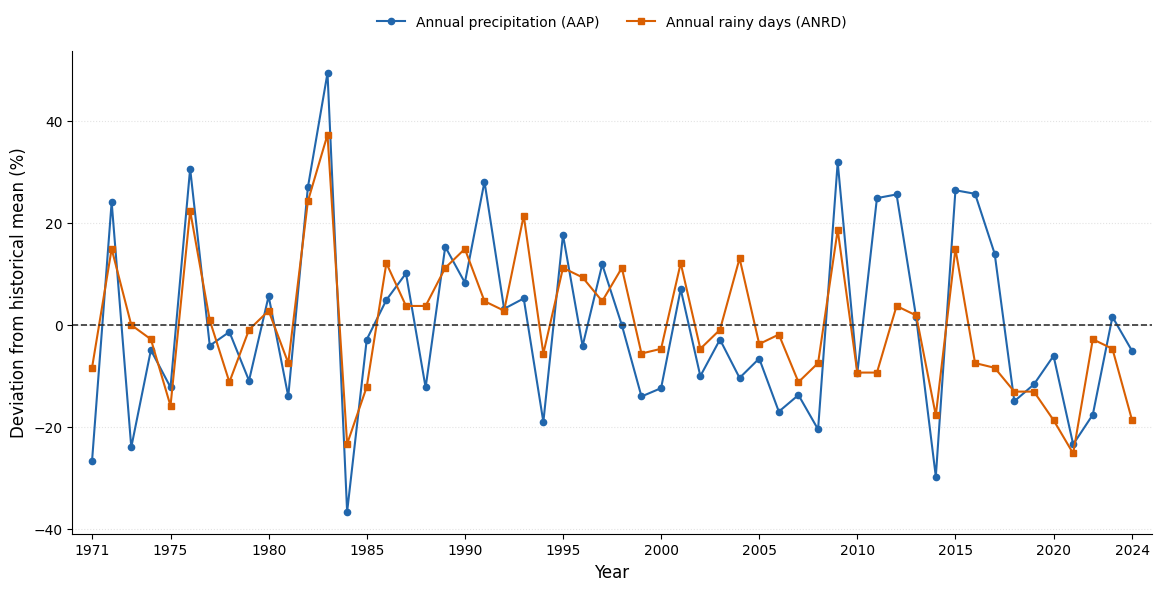


Figure 2 generated successfully.
Study period: 1971-2024
Calendar years included: 54

Output files:
Figure_2_Annual_Relative_Deviations_1971_2024.png
Figure_2_Annual_Relative_Deviations_1971_2024.pdf
Figure_2_Annual_Relative_Deviations_1971_2024.svg
Step_04_Annual_Relative_Deviations_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 04 - ANNUAL RELATIVE DEVIATIONS
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objective:
# Calculate and visualize the relative annual deviations
# of accumulated precipitation (AAP) and the annual
# number of rainy days (ANRD) from their historical means.
#
# Equation:
# Relative deviation (%) = ((X - X_mean) / X_mean) * 100
#
# All 54 calendar years are included.
# Missing daily precipitation values are not imputed.
# No additional statistical tests are performed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. RETRIEVE ANNUAL INDICATORS FROM STEP 02
# ------------------------------------------------------------

annual = (
    anuais_validos[
        ["Ano", "AAP_mm", "ANRD_days"]
    ]
    .copy()
    .sort_values("Ano")
    .reset_index(drop=True)
)

assert len(annual) == 54
assert annual["Ano"].is_unique
assert annual["Ano"].min() == 1971
assert annual["Ano"].max() == 2024

assert annual[
    ["AAP_mm", "ANRD_days"]
].notna().all().all()

# ------------------------------------------------------------
# 2. RETRIEVE HISTORICAL MEANS FROM TABLE 1
# ------------------------------------------------------------

mean_aap = float(
    tabela1.loc[
        tabela1["Variable"] == "AAP",
        "Mean"
    ].iloc[0]
)

mean_anrd = float(
    tabela1.loc[
        tabela1["Variable"] == "ANRD",
        "Mean"
    ].iloc[0]
)

assert mean_aap > 0
assert mean_anrd > 0

# ------------------------------------------------------------
# 3. CALCULATE ANNUAL RELATIVE DEVIATIONS
# ------------------------------------------------------------

annual["AAP_deviation_percent"] = (
    (annual["AAP_mm"] - mean_aap)
    / mean_aap
    * 100
)

annual["ANRD_deviation_percent"] = (
    (annual["ANRD_days"] - mean_anrd)
    / mean_anrd
    * 100
)

# Verify that the mean deviations are approximately zero.
assert np.isclose(
    annual["AAP_deviation_percent"].mean(),
    0,
    atol=1e-10
)

assert np.isclose(
    annual["ANRD_deviation_percent"].mean(),
    0,
    atol=1e-10
)

# Store the results for subsequent use.
anomalias_anuais = annual.copy()

# ------------------------------------------------------------
# 4. DISPLAY ANNUAL DEVIATIONS
# ------------------------------------------------------------

print("=" * 70)
print("ANNUAL RELATIVE DEVIATIONS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print(f"Historical mean AAP: {mean_aap:.2f} mm")
print(f"Historical mean ANRD: {mean_anrd:.2f} days")
print(f"Calendar years: {len(annual)}")

display(
    anomalias_anuais.round(2)
)

# ------------------------------------------------------------
# 5. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(
    figsize=(11.5, 5.8),
    constrained_layout=True
)

# ------------------------------------------------------------
# 6. PLOT ANNUAL RELATIVE DEVIATIONS
# ------------------------------------------------------------

ax.plot(
    annual["Ano"],
    annual["AAP_deviation_percent"],
    color="#2166AC",
    marker="o",
    markersize=4.5,
    linewidth=1.5,
    label="Annual precipitation (AAP)"
)

ax.plot(
    annual["Ano"],
    annual["ANRD_deviation_percent"],
    color="#D95F02",
    marker="s",
    markersize=4.2,
    linewidth=1.5,
    label="Annual rainy days (ANRD)"
)

# Zero represents the historical mean.
ax.axhline(
    y=0,
    color="#333333",
    linestyle="--",
    linewidth=1.2
)

# ------------------------------------------------------------
# 7. FORMAT THE FIGURE
# ------------------------------------------------------------

ax.set_xlabel("Year")

ax.set_ylabel(
    "Deviation from historical mean (%)"
)

ax.set_xlim(1970, 2025)

ax.set_xticks(
    [1971] + list(range(1975, 2025, 5)) + [2024]
)

ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.8,
    alpha=0.35
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

# ------------------------------------------------------------
# 8. EXPORT FIGURE 2
# ------------------------------------------------------------

figure_name = (
    "Figure_2_Annual_Relative_"
    "Deviations_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 9. EXPORT THE DATA USED IN FIGURE 2
# ------------------------------------------------------------

output_file = (
    "Step_04_Annual_Relative_"
    "Deviations_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    anomalias_anuais.to_excel(
        writer,
        sheet_name="Annual_Deviations",
        index=False
    )

# ------------------------------------------------------------
# 10. REPORT OUTPUT FILES
# ------------------------------------------------------------

print("\nFigure 2 generated successfully.")

print("Study period: 1971-2024")
print("Calendar years included:", len(annual))

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")
print(output_file)

files.download(output_file)


In [ ]:

# ============================================================
# STEP 05 - MONTHLY PRECIPITATION AND RAINY-DAY FREQUENCY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Calculate monthly accumulated precipitation (MAP).
# 2. Calculate the monthly number of rainy days (MNRD).
# 3. Calculate relative monthly rainy-day frequency.
# 4. Calculate descriptive statistics by calendar month.
#
# All 54 calendar years are considered.
# Only complete months are used for monthly statistics.
# Missing precipitation observations are not imputed.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. PREPARE DAILY PRECIPITATION DATA
# ------------------------------------------------------------

RAIN_THRESHOLD = 1.0

monthly_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

monthly_data["Data"] = pd.to_datetime(
    monthly_data["Data"]
)

monthly_data["Year"] = monthly_data["Data"].dt.year
monthly_data["Month"] = monthly_data["Data"].dt.month

# Identify rainy days while preserving missing observations.
monthly_data["Rainy_day"] = np.where(
    monthly_data["Precipitacao_mm"].notna(),
    (
        monthly_data["Precipitacao_mm"]
        >= RAIN_THRESHOLD
    ).astype(int),
    np.nan
)

# ------------------------------------------------------------
# 2. CALCULATE MONTHLY INDICATORS
# ------------------------------------------------------------

monthly_indicators = (
    monthly_data
    .groupby(["Year", "Month"])
    .agg(
        Expected_days=("Data", "size"),
        Valid_days=("Precipitacao_mm", "count"),
        MAP_mm=(
            "Precipitacao_mm",
            lambda x: x.sum(min_count=1)
        ),
        MNRD_days=("Rainy_day", "sum")
    )
    .reset_index()
)

# Identify complete and incomplete months.
monthly_indicators["Complete"] = (
    monthly_indicators["Expected_days"]
    == monthly_indicators["Valid_days"]
)

monthly_indicators["Missing_days"] = (
    monthly_indicators["Expected_days"]
    - monthly_indicators["Valid_days"]
)

# Relative frequency is based on observed days.
monthly_indicators["Rainy_frequency_percent"] = (
    monthly_indicators["MNRD_days"]
    / monthly_indicators["Valid_days"]
    * 100
)

# ------------------------------------------------------------
# 3. SELECT COMPLETE MONTHS FOR CLIMATOLOGY
# ------------------------------------------------------------

mensais_validos = (
    monthly_indicators[
        monthly_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

mensais_validos["MNRD_days"] = (
    mensais_validos["MNRD_days"].astype(int)
)

meses_incompletos = (
    monthly_indicators[
        ~monthly_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. VERIFY MONTHLY COVERAGE
# ------------------------------------------------------------

assert len(monthly_indicators) == 648
assert len(mensais_validos) == 641
assert len(meses_incompletos) == 7

assert monthly_indicators["Missing_days"].sum() == 12

# Verify that all 54 calendar years are represented.
assert mensais_validos["Year"].nunique() == 54

assert not monthly_indicators.duplicated(
    ["Year", "Month"]
).any()

assert mensais_validos[
    ["MAP_mm", "MNRD_days", "Rainy_frequency_percent"]
].notna().all().all()

# ------------------------------------------------------------
# 5. CALCULATE MONTHLY DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

def monthly_descriptive_statistics(values):

    """
    Calculate the mean, median, minimum, maximum,
    sample standard deviation, and coefficient
    of variation for a monthly indicator.
    """

    x = pd.Series(values, dtype=float)

    mean = x.mean()
    sd = x.std(ddof=1)

    return pd.Series({
        "Mean": mean,
        "Median": x.median(),
        "Minimum": x.min(),
        "Maximum": x.max(),
        "SD": sd,
        "CV_percent": (
            sd / mean * 100
            if mean != 0 else np.nan
        )
    })

map_statistics = (
    mensais_validos
    .groupby("Month")["MAP_mm"]
    .apply(monthly_descriptive_statistics)
    .unstack()
    .reset_index()
)

mnrd_statistics = (
    mensais_validos
    .groupby("Month")["MNRD_days"]
    .apply(monthly_descriptive_statistics)
    .unstack()
    .reset_index()
)

# Monthly frequency and number of complete observations.
frequency_statistics = (
    mensais_validos
    .groupby("Month")
    .agg(
        n=("Year", "size"),
        Rainy_frequency_percent=(
            "Rainy_frequency_percent", "mean"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 6. COMBINE THE MONTHLY STATISTICS
# ------------------------------------------------------------

map_statistics = map_statistics.rename(
    columns={
        col: f"MAP_{col}"
        for col in map_statistics.columns
        if col != "Month"
    }
)

mnrd_statistics = mnrd_statistics.rename(
    columns={
        col: f"MNRD_{col}"
        for col in mnrd_statistics.columns
        if col != "Month"
    }
)

estatisticas_mensais = (
    frequency_statistics
    .merge(
        map_statistics,
        on="Month",
        validate="one_to_one"
    )
    .merge(
        mnrd_statistics,
        on="Month",
        validate="one_to_one"
    )
    .sort_values("Month")
    .reset_index(drop=True)
)

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

estatisticas_mensais.insert(
    1,
    "Month_name",
    estatisticas_mensais["Month"].map(month_names)
)

# ------------------------------------------------------------
# 7. PREPARE TABLE 2
# ------------------------------------------------------------

tabela2 = estatisticas_mensais[
    [
        "Month_name",
        "n",
        "MAP_Mean",
        "MAP_Median",
        "MAP_Minimum",
        "MAP_Maximum",
        "MAP_SD",
        "MAP_CV_percent",
        "MNRD_Mean",
        "MNRD_Median",
        "MNRD_Minimum",
        "MNRD_Maximum",
        "MNRD_SD",
        "MNRD_CV_percent",
        "Rainy_frequency_percent"
    ]
].copy()

tabela2 = tabela2.rename(columns={
    "Month_name": "Month",
    "Rainy_frequency_percent": "Rainy_days_percent"
})

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("MONTHLY PRECIPITATION AND RAINY-DAY FREQUENCY")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Calendar years:", monthly_indicators["Year"].nunique())
print("Total months:", len(monthly_indicators))
print("Complete months:", len(mensais_validos))
print("Incomplete months:", len(meses_incompletos))

print("\nINCOMPLETE MONTHS:")
display(meses_incompletos)

print("\nTABLE 2 - MONTHLY DESCRIPTIVE STATISTICS:")
display(tabela2.round(2))

# ------------------------------------------------------------
# 9. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_05_Monthly_Precipitation_"
    "Rainy_Days_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    monthly_indicators.to_excel(
        writer,
        sheet_name="All_648_Months",
        index=False
    )

    mensais_validos.to_excel(
        writer,
        sheet_name="Complete_Months",
        index=False
    )

    tabela2.to_excel(
        writer,
        sheet_name="Table_2",
        index=False
    )

    meses_incompletos.to_excel(
        writer,
        sheet_name="Incomplete_Months",
        index=False
    )

print("\nOutput file:", output_file)

files.download(output_file)


MONTHLY PRECIPITATION AND RAINY-DAY FREQUENCY
BOTUCATU, BRAZIL | 1971-2024
Calendar years: 54
Total months: 648
Complete months: 641
Incomplete months: 7

INCOMPLETE MONTHS:


,Year,Month,Expected_days,Valid_days,MAP_mm,MNRD_days,Complete,Missing_days,Rainy_frequency_percent
0,1972,8,31,29,72.6043,8.0,False,2,27.586207
1,2014,1,31,30,77.6375,9.0,False,1,30.000000
2,2016,10,31,30,162.8140,9.0,False,1,30.000000
3,2022,3,31,30,183.1240,14.0,False,1,46.666667
4,2022,7,31,30,3.5560,1.0,False,1,3.333333
5,2022,8,31,29,10.4140,3.0,False,2,10.344828
6,2022,9,30,26,97.0180,12.0,False,4,46.153846



TABLE 2 - MONTHLY DESCRIPTIVE STATISTICS:


,Month,n,MAP_Mean,MAP_Median,MAP_Minimum,MAP_Maximum,MAP_SD,MAP_CV_percent,MNRD_Mean,MNRD_Median,MNRD_Minimum,MNRD_Maximum,MNRD_SD,MNRD_CV_percent,Rainy_days_percent
0,January,53,288.14,282.58,71.44,706.99,119.31,41.41,16.62,17.0,10.0,24.0,3.92,23.57,53.62
1,February,54,202.73,205.39,64.01,559.36,94.39,46.56,13.46,13.5,6.0,23.0,4.26,31.67,47.61
2,March,53,169.63,151.94,44.96,466.25,88.95,52.44,11.70,12.0,5.0,20.0,3.46,29.55,37.74
3,April,54,77.73,72.06,3.08,249.84,47.28,60.83,5.91,6.0,1.0,12.0,2.69,45.60,19.69
4,May,54,79.05,62.91,0.51,287.21,62.26,78.76,5.91,6.0,0.0,16.0,3.31,56.02,19.06
5,June,54,58.03,44.80,0.00,229.17,58.34,100.53,4.81,4.5,0.0,14.0,3.51,72.97,16.05
6,July,53,43.26,24.23,0.00,171.86,42.91,99.19,3.60,3.0,0.0,15.0,2.78,77.22,11.63
7,August,52,39.87,24.87,0.00,167.28,40.48,101.55,3.75,4.0,0.0,10.0,2.79,74.28,12.10
8,September,53,82.52,73.73,0.00,243.69,60.46,73.27,6.98,7.0,0.0,16.0,3.72,53.26,23.27
9,October,53,123.43,113.50,11.19,359.51,64.64,52.37,9.32,9.0,3.0,16.0,3.31,35.51,30.07



Output file: Step_05_Monthly_Precipitation_Rainy_Days_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

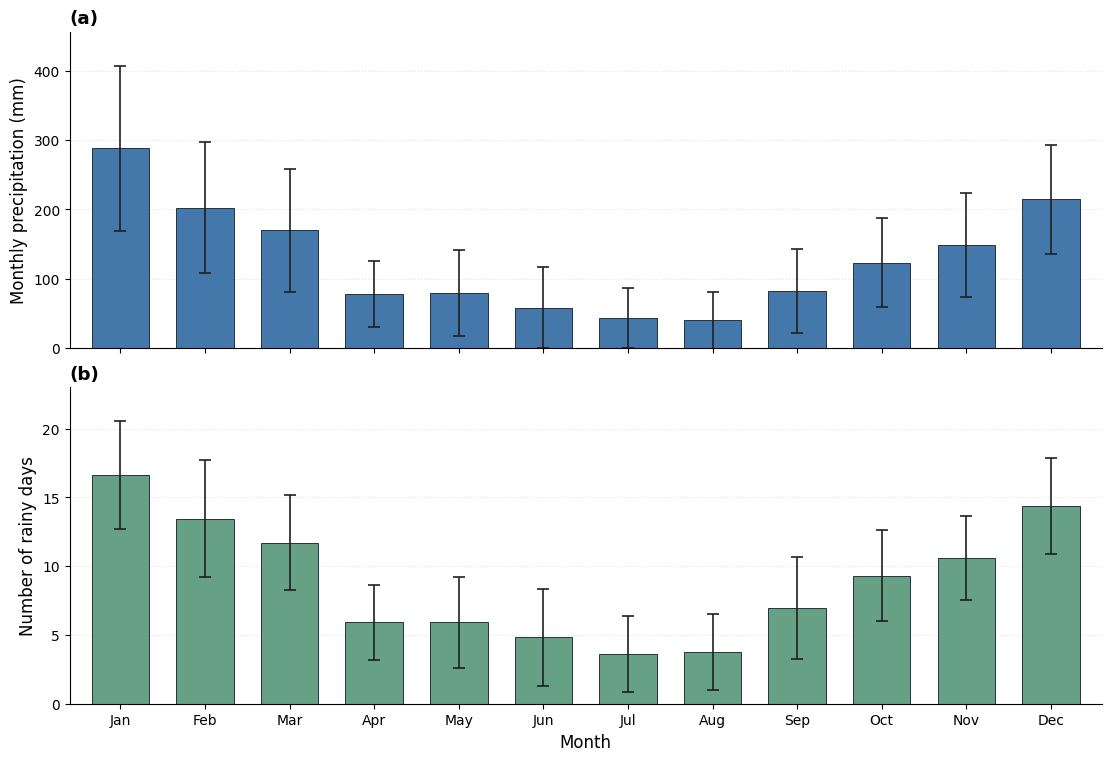

FIGURE 3 GENERATED SUCCESSFULLY
Study period: 1971-2024
Complete months: 641

Output files:
Figure_3_Monthly_Precipitation_Rainy_Days_1971_2024.png
Figure_3_Monthly_Precipitation_Rainy_Days_1971_2024.pdf
Figure_3_Monthly_Precipitation_Rainy_Days_1971_2024.svg


In [ ]:

# ============================================================
# STEP 06 - MONTHLY PRECIPITATION AND RAINY-DAY VARIABILITY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize mean monthly accumulated precipitation (MAP)
# and mean monthly number of rainy days (MNRD).
#
# Error bars represent one sample standard deviation.
#
# All 54 calendar years are represented through their
# complete monthly records (641 complete months).
#
# No additional statistical indicators are calculated.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RETRIEVE MONTHLY RESULTS FROM STEP 05
# ------------------------------------------------------------

monthly = tabela2.copy()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly["Month"] = pd.Categorical(
    monthly["Month"],
    categories=month_order,
    ordered=True
)

monthly = (
    monthly.sort_values("Month")
    .reset_index(drop=True)
)

required_columns = [
    "MAP_Mean", "MAP_SD",
    "MNRD_Mean", "MNRD_SD"
]

assert len(monthly) == 12
assert monthly["n"].sum() == 641
assert monthly[required_columns].notna().all().all()

# ------------------------------------------------------------
# 2. PREPARE VALUES FOR VISUALIZATION
# ------------------------------------------------------------

x = np.arange(12)

map_mean = monthly["MAP_Mean"].to_numpy(
    dtype=float
)

map_sd = monthly["MAP_SD"].to_numpy(
    dtype=float
)

mnrd_mean = monthly["MNRD_Mean"].to_numpy(
    dtype=float
)

mnrd_sd = monthly["MNRD_SD"].to_numpy(
    dtype=float
)

# ------------------------------------------------------------
# 3. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7.5),
    sharex=True,
    constrained_layout=True
)

# ------------------------------------------------------------
# 4. PANEL A - MONTHLY ACCUMULATED PRECIPITATION
# ------------------------------------------------------------

axes[0].bar(
    x,
    map_mean,
    yerr=map_sd,
    width=0.68,
    color="#4477AA",
    edgecolor="#263238",
    linewidth=0.7,
    error_kw={
        "ecolor": "#202020",
        "elinewidth": 1.2,
        "capsize": 4,
        "capthick": 1.2
    }
)

axes[0].set_ylabel(
    "Monthly precipitation (mm)"
)

axes[0].set_title(
    "(a)",
    loc="left",
    fontweight="bold"
)

axes[0].set_ylim(
    0,
    np.max(map_mean + map_sd) * 1.12
)

# ------------------------------------------------------------
# 5. PANEL B - MONTHLY NUMBER OF RAINY DAYS
# ------------------------------------------------------------

axes[1].bar(
    x,
    mnrd_mean,
    yerr=mnrd_sd,
    width=0.68,
    color="#66A085",
    edgecolor="#263238",
    linewidth=0.7,
    error_kw={
        "ecolor": "#202020",
        "elinewidth": 1.2,
        "capsize": 4,
        "capthick": 1.2
    }
)

axes[1].set_ylabel(
    "Number of rainy days"
)

axes[1].set_title(
    "(b)",
    loc="left",
    fontweight="bold"
)

axes[1].set_ylim(
    0,
    np.max(mnrd_mean + mnrd_sd) * 1.12
)

# ------------------------------------------------------------
# 6. FORMAT BOTH PANELS
# ------------------------------------------------------------

for ax in axes:

    ax.set_xlim(-0.6, 11.6)

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.8,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        direction="out"
    )

axes[1].set_xticks(x)
axes[1].set_xticklabels(month_labels)
axes[1].set_xlabel("Month")

# ------------------------------------------------------------
# 7. EXPORT FIGURE 3
# ------------------------------------------------------------

figure_name = (
    "Figure_3_Monthly_Precipitation_"
    "Rainy_Days_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 8. REPORT OUTPUT
# ------------------------------------------------------------

print("=" * 60)
print("FIGURE 3 GENERATED SUCCESSFULLY")
print("=" * 60)

print("Study period: 1971-2024")
print("Complete months:", int(monthly["n"].sum()))

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


In [ ]:

# ============================================================
# STEP 07 - TEN-DAY PRECIPITATION AND RAINY-DAY FREQUENCY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Calculate precipitation accumulated in each
#    ten-day period (TDP).
# 2. Calculate the number of rainy days (TNRD).
# 3. Calculate relative rainy-day frequency.
# 4. Characterize the historical distribution
#    using the descriptive statistics specified
#    in the methodology.
#
# Ten-day period definitions:
# D1: days 1-10
# D2: days 11-20
# D3: day 21 through the end of the month
#
# Rainy day: daily precipitation >= 1.0 mm.
#
# All 54 calendar years are considered.
# Only complete ten-day periods are included
# in the climatological statistics.
#
# Missing observations are not imputed.
# ============================================================

import numpy as np
import pandas as pd
import calendar
from google.colab import files

# ------------------------------------------------------------
# 1. PREPARE THE DAILY DATASET
# ------------------------------------------------------------

RAIN_THRESHOLD = 1.0

ten_day_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

ten_day_data["Data"] = pd.to_datetime(
    ten_day_data["Data"]
)

ten_day_data["Year"] = (
    ten_day_data["Data"].dt.year
)

ten_day_data["Month"] = (
    ten_day_data["Data"].dt.month
)

ten_day_data["Day"] = (
    ten_day_data["Data"].dt.day
)

# Classify rainy days without changing missing values.
ten_day_data["Rainy_day"] = np.where(
    ten_day_data["Precipitacao_mm"].notna(),
    (
        ten_day_data["Precipitacao_mm"]
        >= RAIN_THRESHOLD
    ).astype(int),
    np.nan
)

# ------------------------------------------------------------
# 2. IDENTIFY TEN-DAY PERIODS
# ------------------------------------------------------------

ten_day_data["Ten_day"] = np.select(
    [
        ten_day_data["Day"] <= 10,
        ten_day_data["Day"].between(11, 20),
        ten_day_data["Day"] >= 21
    ],
    ["D1", "D2", "D3"],
    default="Invalid"
)

assert not (
    ten_day_data["Ten_day"] == "Invalid"
).any()

# ------------------------------------------------------------
# 3. CALCULATE TEN-DAY INDICATORS
# ------------------------------------------------------------

ten_day_indicators = (
    ten_day_data
    .groupby(["Year", "Month", "Ten_day"])
    .agg(
        Period_days=("Data", "size"),
        Valid_days=("Precipitacao_mm", "count"),
        TDP_mm=(
            "Precipitacao_mm",
            lambda x: x.sum(min_count=1)
        ),
        TNRD_days=("Rainy_day", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. VERIFY EXPECTED PERIOD LENGTHS
# ------------------------------------------------------------

def expected_ten_day_length(year, month, period):

    if period in ["D1", "D2"]:
        return 10

    last_day = calendar.monthrange(
        int(year), int(month)
    )[1]

    return last_day - 20

ten_day_indicators["Expected_days"] = (
    ten_day_indicators.apply(
        lambda row: expected_ten_day_length(
            row["Year"],
            row["Month"],
            row["Ten_day"]
        ),
        axis=1
    )
)

assert (
    ten_day_indicators["Period_days"]
    == ten_day_indicators["Expected_days"]
).all()

# ------------------------------------------------------------
# 5. IDENTIFY COMPLETE AND INCOMPLETE PERIODS
# ------------------------------------------------------------

ten_day_indicators["Complete"] = (
    ten_day_indicators["Valid_days"]
    == ten_day_indicators["Expected_days"]
)

ten_day_indicators["Missing_days"] = (
    ten_day_indicators["Expected_days"]
    - ten_day_indicators["Valid_days"]
)

# Retain all complete ten-day periods.
decendiais_validos = (
    ten_day_indicators[
        ten_day_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

# Keep incomplete periods documented separately.
decendios_incompletos = (
    ten_day_indicators[
        ~ten_day_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. CALCULATE RELATIVE RAINY-DAY FREQUENCY
# ------------------------------------------------------------

decendiais_validos["TNRD_days"] = (
    decendiais_validos["TNRD_days"].astype(int)
)

# Relative rainy-day frequency (%).
# Each complete period uses its actual number of days.
#
# RF = (TNRD / period length) * 100

decendiais_validos["Rainy_frequency_percent"] = (
    decendiais_validos["TNRD_days"]
    / decendiais_validos["Expected_days"]
    * 100
)

# ------------------------------------------------------------
# 7. VERIFY PERIOD COVERAGE
# ------------------------------------------------------------

assert len(ten_day_indicators) == 1944

assert len(decendiais_validos) == 1935

assert len(decendios_incompletos) == 9

assert (
    ten_day_indicators["Missing_days"].sum()
    == 12
)

assert decendiais_validos["Year"].nunique() == 54

assert not ten_day_indicators.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

assert decendiais_validos[
    ["TDP_mm", "TNRD_days", "Rainy_frequency_percent"]
].notna().all().all()

assert decendiais_validos[
    "Rainy_frequency_percent"
].between(0, 100).all()

# ------------------------------------------------------------
# 8. CALCULATE DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

def calculate_descriptive_statistics(values):

    """
    Calculate mean, median, minimum, maximum,
    sample standard deviation (SD), and
    coefficient of variation (CV).

    CV (%) = (SD / Mean) * 100.
    """

    values = pd.Series(
        values,
        dtype=float
    )

    mean = values.mean()
    sd = values.std(ddof=1)

    return {
        "Mean": mean,
        "Median": values.median(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "SD": sd,
        "CV_percent": (
            sd / mean * 100
            if mean != 0 else np.nan
        )
    }

# ------------------------------------------------------------
# 9. SUMMARIZE EACH MONTH AND TEN-DAY PERIOD
# ------------------------------------------------------------

results = []

for (month, period), group in (
    decendiais_validos.groupby(
        ["Month", "Ten_day"],
        sort=True
    )
):

    precipitation_stats = (
        calculate_descriptive_statistics(
            group["TDP_mm"]
        )
    )

    rainy_day_stats = (
        calculate_descriptive_statistics(
            group["TNRD_days"]
        )
    )

    result = {
        "Month": int(month),
        "Ten_day": period,
        "n": len(group),
        "Rainy_frequency_percent": (
            group["Rainy_frequency_percent"].mean()
        )
    }

    for statistic, value in precipitation_stats.items():
        result[f"TDP_{statistic}"] = value

    for statistic, value in rainy_day_stats.items():
        result[f"TNRD_{statistic}"] = value

    results.append(result)

estatisticas_decendiais = pd.DataFrame(results)

# ------------------------------------------------------------
# 10. PREPARE THE TEN-DAY SUMMARY TABLE
# ------------------------------------------------------------

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

estatisticas_decendiais.insert(
    1,
    "Month_name",
    estatisticas_decendiais["Month"].map(month_names)
)

tabela_decendial = (
    estatisticas_decendiais[
        [
            "Month_name",
            "Ten_day",
            "n",
            "TDP_Mean",
            "TDP_Median",
            "TDP_Minimum",
            "TDP_Maximum",
            "TDP_SD",
            "TDP_CV_percent",
            "TNRD_Mean",
            "TNRD_Median",
            "TNRD_Minimum",
            "TNRD_Maximum",
            "TNRD_SD",
            "TNRD_CV_percent",
            "Rainy_frequency_percent"
        ]
    ]
    .copy()
)

tabela_decendial = tabela_decendial.rename(
    columns={
        "Month_name": "Month",
        "Rainy_frequency_percent": (
            "Rainy_days_percent"
        )
    }
)

assert len(tabela_decendial) == 36

assert tabela_decendial["n"].sum() == 1935

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("TEN-DAY PRECIPITATION AND RAINY-DAY FREQUENCY")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Calendar years:", ten_day_data["Year"].nunique())

print(
    "Total ten-day periods:",
    len(ten_day_indicators)
)

print(
    "Complete ten-day periods:",
    len(decendiais_validos)
)

print(
    "Incomplete ten-day periods:",
    len(decendios_incompletos)
)

print("\nINCOMPLETE TEN-DAY PERIODS:")
display(
    decendios_incompletos[
        [
            "Year",
            "Month",
            "Ten_day",
            "Expected_days",
            "Valid_days",
            "Missing_days"
        ]
    ]
)

print("\nTEN-DAY DESCRIPTIVE STATISTICS:")
display(
    tabela_decendial.round(2)
)

# ------------------------------------------------------------
# 12. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_07_Ten_Day_Precipitation_"
    "Rainy_Days_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    ten_day_indicators.to_excel(
        writer,
        sheet_name="All_1944_Periods",
        index=False
    )

    decendiais_validos.to_excel(
        writer,
        sheet_name="Complete_TenDay_Periods",
        index=False
    )

    tabela_decendial.to_excel(
        writer,
        sheet_name="TenDay_Statistics",
        index=False
    )

    decendios_incompletos.to_excel(
        writer,
        sheet_name="Incomplete_Periods",
        index=False
    )

print("\nOutput file:", output_file)

files.download(output_file)


TEN-DAY PRECIPITATION AND RAINY-DAY FREQUENCY
BOTUCATU, BRAZIL | 1971-2024
Calendar years: 54
Total ten-day periods: 1944
Complete ten-day periods: 1935
Incomplete ten-day periods: 9

INCOMPLETE TEN-DAY PERIODS:


,Year,Month,Ten_day,Expected_days,Valid_days,Missing_days
0,1972,8,D1,10,8,2
1,2014,1,D3,11,10,1
2,2016,10,D2,10,9,1
3,2022,3,D3,11,10,1
4,2022,7,D2,10,9,1
5,2022,8,D1,10,9,1
6,2022,8,D3,11,10,1
7,2022,9,D1,10,7,3
8,2022,9,D2,10,9,1



TEN-DAY DESCRIPTIVE STATISTICS:


,Month,Ten_day,n,TDP_Mean,TDP_Median,TDP_Minimum,TDP_Maximum,TDP_SD,TDP_CV_percent,TNRD_Mean,TNRD_Median,TNRD_Minimum,TNRD_Maximum,TNRD_SD,TNRD_CV_percent,Rainy_days_percent
0,January,D1,54,91.85,67.40,10.02,461.25,74.84,81.48,5.67,5.5,1.0,10.0,2.15,37.86,56.67
1,January,D2,54,92.71,86.60,7.53,289.94,61.56,66.40,5.30,5.0,1.0,10.0,2.11,39.78,52.96
2,January,D3,53,101.40,85.59,4.06,275.58,67.75,66.81,5.58,6.0,1.0,11.0,2.45,43.92,50.77
3,February,D1,54,78.49,67.66,0.00,475.54,80.78,102.92,4.81,5.0,0.0,10.0,2.67,55.48,48.15
4,February,D2,54,71.77,64.66,1.52,211.00,52.01,72.47,5.02,5.0,1.0,9.0,2.34,46.69,50.19
5,February,D3,54,52.47,41.94,0.00,192.00,43.60,83.10,3.63,3.5,0.0,8.0,1.96,53.87,43.62
6,March,D1,54,62.98,48.25,0.00,213.49,51.42,81.65,4.26,4.0,0.0,8.0,1.90,44.50,42.59
7,March,D2,54,57.49,46.44,4.99,352.08,54.16,94.22,3.94,4.0,1.0,9.0,1.94,49.10,39.44
8,March,D3,53,49.83,33.13,0.00,243.09,48.06,96.45,3.57,3.0,0.0,8.0,2.00,55.95,32.42
9,April,D1,54,29.75,21.20,0.00,141.48,27.48,92.37,2.06,2.0,0.0,5.0,1.38,67.10,20.56



Output file: Step_07_Ten_Day_Precipitation_Rainy_Days_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

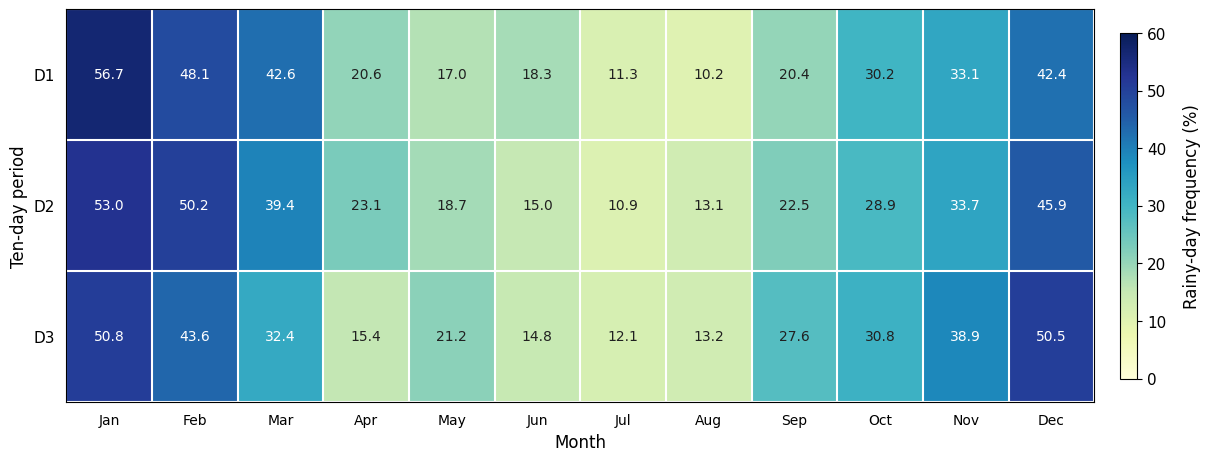

FIGURE 4 GENERATED SUCCESSFULLY
Study period: 1971-2024
Complete ten-day periods: 1935
Calendar-month groups: 36

Output files:
Figure_4_Ten_Day_Rainy_Day_Frequency_1971_2024.png
Figure_4_Ten_Day_Rainy_Day_Frequency_1971_2024.pdf
Figure_4_Ten_Day_Rainy_Day_Frequency_1971_2024.svg


In [ ]:

# ============================================================
# STEP 08 - TEN-DAY RAINY-DAY FREQUENCY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize the historical relative frequency of rainy
# days for each ten-day period of the calendar year.
#
# Ten-day periods:
# D1 = days 1-10
# D2 = days 11-20
# D3 = days 21 through the end of the month
#
# Rainy day: daily precipitation >= 1.0 mm.
#
# The figure uses the results calculated in Step 07.
# No additional statistical calculations are performed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RETRIEVE TEN-DAY RESULTS FROM STEP 07
# ------------------------------------------------------------

ten_day = tabela_decendial.copy()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

period_order = ["D1", "D2", "D3"]

# ------------------------------------------------------------
# 2. VERIFY THE RESULTS
# ------------------------------------------------------------

assert len(ten_day) == 36

assert ten_day["n"].sum() == 1935

assert not ten_day.duplicated(
    ["Month", "Ten_day"]
).any()

assert ten_day[
    "Rainy_days_percent"
].notna().all()

assert ten_day[
    "Rainy_days_percent"
].between(0, 100).all()

# ------------------------------------------------------------
# 3. ORGANIZE THE FREQUENCY MATRIX
# ------------------------------------------------------------

# Rows: ten-day periods (D1, D2, D3).
# Columns: calendar months (January-December).

frequency_table = (
    ten_day
    .pivot(
        index="Ten_day",
        columns="Month",
        values="Rainy_days_percent"
    )
    .reindex(
        index=period_order,
        columns=month_order
    )
)

frequency_matrix = frequency_table.to_numpy(
    dtype=float
)

assert frequency_matrix.shape == (3, 12)

assert np.isfinite(
    frequency_matrix
).all()

# ------------------------------------------------------------
# 4. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(
    figsize=(12, 4.5),
    constrained_layout=True
)

# ------------------------------------------------------------
# 5. CREATE THE HEATMAP
# ------------------------------------------------------------

image = ax.imshow(
    frequency_matrix,
    cmap="YlGnBu",
    vmin=0,
    vmax=60,
    aspect="auto",
    interpolation="nearest"
)

# ------------------------------------------------------------
# 6. FORMAT AXES
# ------------------------------------------------------------

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(np.arange(3))
ax.set_yticklabels(period_order)

ax.set_xlabel("Month")
ax.set_ylabel("Ten-day period")

# ------------------------------------------------------------
# 7. DISPLAY FREQUENCY VALUES
# ------------------------------------------------------------

for i in range(3):
    for j in range(12):

        value = frequency_matrix[i, j]

        text_color = (
            "white" if value >= 32
            else "#202020"
        )

        ax.text(
            j,
            i,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=10,
            color=text_color
        )

# ------------------------------------------------------------
# 8. ADD CELL BOUNDARIES
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, 12, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, 3, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.5
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

ax.tick_params(
    axis="both",
    length=0,
    pad=8
)

# ------------------------------------------------------------
# 9. ADD THE COLOR BAR
# ------------------------------------------------------------

colorbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.88,
    pad=0.025,
    ticks=np.arange(0, 61, 10)
)

colorbar.set_label(
    "Rainy-day frequency (%)",
    rotation=90,
    labelpad=12
)

# ------------------------------------------------------------
# 10. EXPORT FIGURE 4
# ------------------------------------------------------------

figure_name = (
    "Figure_4_Ten_Day_Rainy_Day_"
    "Frequency_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 11. REPORT OUTPUT
# ------------------------------------------------------------

print("=" * 60)
print("FIGURE 4 GENERATED SUCCESSFULLY")
print("=" * 60)

print("Study period: 1971-2024")
print("Complete ten-day periods:", 1935)
print("Calendar-month groups:", 36)

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


In [ ]:

# ============================================================
# STEP 09 - SEASONAL PRECIPITATION AND RAINY-DAY FREQUENCY
# Methodology section 2.3
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: January 1, 1971 - December 31, 2024
#
# Objectives:
# 1. Calculate seasonal accumulated precipitation.
# 2. Calculate the seasonal number of rainy days.
# 3. Calculate seasonal relative rainy-day frequency.
# 4. Calculate the descriptive statistics defined
#    in the study methodology.
#
# Meteorological seasons:
# DJF = December, January, February (summer)
# MAM = March, April, May (autumn)
# JJA = June, July, August (winter)
# SON = September, October, November (spring)
#
# December belongs to the following seasonal year.
#
# Only complete seasons are included in the
# climatological statistics.
#
# Missing observations are not imputed.
# ============================================================

import numpy as np
import pandas as pd
import calendar
from google.colab import files

# ------------------------------------------------------------
# 1. PREPARE AND VERIFY THE DAILY DATASET
# ------------------------------------------------------------

RAIN_THRESHOLD = 1.0

seasonal_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

seasonal_data["Data"] = pd.to_datetime(
    seasonal_data["Data"],
    errors="coerce"
).dt.normalize()

seasonal_data["Precipitacao_mm"] = pd.to_numeric(
    seasonal_data["Precipitacao_mm"],
    errors="coerce"
)

seasonal_data = (
    seasonal_data
    .sort_values("Data")
    .reset_index(drop=True)
)

expected_calendar = pd.date_range(
    start="1971-01-01",
    end="2024-12-31",
    freq="D"
)

assert len(seasonal_data) == len(expected_calendar)

assert seasonal_data["Data"].is_unique

assert np.array_equal(
    seasonal_data["Data"].to_numpy(),
    expected_calendar.to_numpy()
)

assert not (
    seasonal_data["Precipitacao_mm"] < 0
).any()

# ------------------------------------------------------------
# 2. IDENTIFY RAINY DAYS
# ------------------------------------------------------------

seasonal_data["Year"] = (
    seasonal_data["Data"].dt.year
)

seasonal_data["Month"] = (
    seasonal_data["Data"].dt.month
)

# Rainy day: precipitation >= 1.0 mm.
# Missing observations remain NaN.

seasonal_data["Rainy_day"] = np.where(
    seasonal_data["Precipitacao_mm"].notna(),
    (
        seasonal_data["Precipitacao_mm"]
        >= RAIN_THRESHOLD
    ).astype(int),
    np.nan
)

# ------------------------------------------------------------
# 3. CLASSIFY METEOROLOGICAL SEASONS
# ------------------------------------------------------------

seasonal_data["Season"] = np.select(
    [
        seasonal_data["Month"].isin([12, 1, 2]),
        seasonal_data["Month"].isin([3, 4, 5]),
        seasonal_data["Month"].isin([6, 7, 8]),
        seasonal_data["Month"].isin([9, 10, 11])
    ],
    ["DJF", "MAM", "JJA", "SON"],
    default="Invalid"
)

assert not (
    seasonal_data["Season"] == "Invalid"
).any()

# December is assigned to the next seasonal year.
# Example: DJF 2020 includes December 2019,
# January 2020, and February 2020.

seasonal_data["Season_year"] = np.where(
    seasonal_data["Month"] == 12,
    seasonal_data["Year"] + 1,
    seasonal_data["Year"]
)

# ------------------------------------------------------------
# 4. DEFINE EXPECTED SEASON LENGTHS
# ------------------------------------------------------------

def expected_season_days(year, season):

    """
    Return the expected number of calendar days
    in a meteorological season.

    DJF includes December of the preceding year
    and January-February of the seasonal year.
    """

    year = int(year)

    if season == "DJF":

        february_days = calendar.monthrange(
            year, 2
        )[1]

        return 31 + 31 + february_days

    elif season == "MAM":
        return 31 + 30 + 31

    elif season == "JJA":
        return 30 + 31 + 31

    elif season == "SON":
        return 30 + 31 + 30

    else:
        raise ValueError(
            "Invalid meteorological season."
        )

# ------------------------------------------------------------
# 5. CALCULATE SEASONAL INDICATORS
# ------------------------------------------------------------

seasonal_indicators = (
    seasonal_data
    .groupby(["Season_year", "Season"])
    .agg(
        Observed_days=("Data", "size"),

        Valid_days=(
            "Precipitacao_mm", "count"
        ),

        Seasonal_precipitation_mm=(
            "Precipitacao_mm",
            lambda x: x.sum(min_count=1)
        ),

        Seasonal_rainy_days=(
            "Rainy_day",
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
)

# Determine the expected number of days.
seasonal_indicators["Expected_days"] = (
    seasonal_indicators.apply(
        lambda row: expected_season_days(
            row["Season_year"],
            row["Season"]
        ),
        axis=1
    )
)

# ------------------------------------------------------------
# 6. IDENTIFY COMPLETE AND INCOMPLETE SEASONS
# ------------------------------------------------------------

# A complete season must contain every expected
# calendar day and every precipitation observation.

seasonal_indicators["Complete"] = (
    (
        seasonal_indicators["Observed_days"]
        == seasonal_indicators["Expected_days"]
    )
    &
    (
        seasonal_indicators["Valid_days"]
        == seasonal_indicators["Expected_days"]
    )
)

# Count missing observations within the available record.
seasonal_indicators["Missing_observations"] = (
    seasonal_indicators["Observed_days"]
    - seasonal_indicators["Valid_days"]
)

# Count days outside the boundaries of the study record.
seasonal_indicators["Outside_record_days"] = (
    seasonal_indicators["Expected_days"]
    - seasonal_indicators["Observed_days"]
)

# Retain complete seasons for climatological analysis.
sazonais_validos = (
    seasonal_indicators.loc[
        seasonal_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

# Document excluded seasons.
sazonais_incompletas = (
    seasonal_indicators.loc[
        ~seasonal_indicators["Complete"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. CALCULATE SEASONAL RAINY-DAY FREQUENCY
# ------------------------------------------------------------

sazonais_validos["Seasonal_rainy_days"] = (
    sazonais_validos[
        "Seasonal_rainy_days"
    ].astype(int)
)

# Relative rainy-day frequency (%).
#
# RF = (Number of rainy days / Season length) * 100

sazonais_validos["Rainy_frequency_percent"] = (
    sazonais_validos["Seasonal_rainy_days"]
    / sazonais_validos["Expected_days"]
    * 100
)

# ------------------------------------------------------------
# 8. VERIFY SEASONAL DATA COVERAGE
# ------------------------------------------------------------

season_order = ["DJF", "MAM", "JJA", "SON"]

expected_counts = {
    "DJF": 52,
    "MAM": 53,
    "JJA": 52,
    "SON": 52
}

assert len(seasonal_indicators) == 217

assert len(sazonais_validos) == 209

assert len(sazonais_incompletas) == 8

assert not seasonal_indicators.duplicated(
    ["Season_year", "Season"]
).any()

actual_counts = (
    sazonais_validos["Season"]
    .value_counts()
    .to_dict()
)

assert actual_counts == expected_counts

assert sazonais_validos[
    [
        "Seasonal_precipitation_mm",
        "Seasonal_rainy_days",
        "Rainy_frequency_percent"
    ]
].notna().all().all()

assert sazonais_validos[
    "Rainy_frequency_percent"
].between(0, 100).all()

assert (
    sazonais_validos["Observed_days"]
    == sazonais_validos["Expected_days"]
).all()

assert (
    sazonais_validos["Valid_days"]
    == sazonais_validos["Expected_days"]
).all()

# ------------------------------------------------------------
# 9. DEFINE THE DESCRIPTIVE STATISTICS FUNCTION
# ------------------------------------------------------------

def seasonal_descriptive_statistics(values):

    """
    Calculate the descriptive statistics defined
    in the methodology:

    - Arithmetic mean
    - Median
    - Minimum
    - Maximum
    - Sample standard deviation
    - Coefficient of variation

    SD is calculated using ddof=1.

    CV (%) = (SD / Mean) * 100.
    """

    x = pd.Series(
        values,
        dtype=float
    ).dropna()

    mean = x.mean()
    sd = x.std(ddof=1)

    return {
        "Mean": mean,
        "Median": x.median(),
        "Minimum": x.min(),
        "Maximum": x.max(),
        "SD": sd,
        "CV_percent": (
            sd / mean * 100
            if mean != 0 else np.nan
        )
    }

# ------------------------------------------------------------
# 10. CALCULATE SEASONAL DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

season_names = {
    "DJF": "Summer",
    "MAM": "Autumn",
    "JJA": "Winter",
    "SON": "Spring"
}

results = []

for season in season_order:

    group = sazonais_validos.loc[
        sazonais_validos["Season"] == season
    ].copy()

    # Seasonal accumulated precipitation statistics.
    precipitation_stats = (
        seasonal_descriptive_statistics(
            group["Seasonal_precipitation_mm"]
        )
    )

    # Seasonal rainy-day number statistics.
    rainy_day_stats = (
        seasonal_descriptive_statistics(
            group["Seasonal_rainy_days"]
        )
    )

    # Mean relative rainy-day frequency.
    mean_frequency = (
        group["Rainy_frequency_percent"].mean()
    )

    result = {
        "Season": season,
        "Season_name": season_names[season],
        "n": len(group),
        "Rainy_frequency_percent": mean_frequency
    }

    for statistic, value in precipitation_stats.items():

        result[
            f"Precipitation_{statistic}"
        ] = value

    for statistic, value in rainy_day_stats.items():

        result[
            f"Rainy_days_{statistic}"
        ] = value

    results.append(result)

estatisticas_sazonais = pd.DataFrame(results)

# ------------------------------------------------------------
# 11. PREPARE THE SEASONAL RESULTS TABLE
# ------------------------------------------------------------

tabela_sazonal = estatisticas_sazonais[
    [
        "Season",
        "Season_name",
        "n",

        "Precipitation_Mean",
        "Precipitation_Median",
        "Precipitation_Minimum",
        "Precipitation_Maximum",
        "Precipitation_SD",
        "Precipitation_CV_percent",

        "Rainy_days_Mean",
        "Rainy_days_Median",
        "Rainy_days_Minimum",
        "Rainy_days_Maximum",
        "Rainy_days_SD",
        "Rainy_days_CV_percent",

        "Rainy_frequency_percent"
    ]
].copy()

assert len(tabela_sazonal) == 4

assert tabela_sazonal["n"].sum() == 209

# ------------------------------------------------------------
# 12. DISPLAY DATA-COVERAGE RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("SEASONAL PRECIPITATION AND RAINY-DAY FREQUENCY")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print(
    "Meteorological seasons identified:",
    len(seasonal_indicators)
)

print(
    "Complete meteorological seasons:",
    len(sazonais_validos)
)

print(
    "Excluded meteorological seasons:",
    len(sazonais_incompletas)
)

print("\nCOMPLETE SEASONS BY CATEGORY:")

print(
    sazonais_validos["Season"]
    .value_counts()
    .reindex(season_order)
)

print("\nEXCLUDED SEASONS:")

display(
    sazonais_incompletas[
        [
            "Season_year",
            "Season",
            "Expected_days",
            "Observed_days",
            "Valid_days",
            "Missing_observations",
            "Outside_record_days"
        ]
    ]
)

# ------------------------------------------------------------
# 13. DISPLAY SEASONAL STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SEASONAL DESCRIPTIVE STATISTICS")
print("=" * 70)

display(
    tabela_sazonal.round(2)
)

# ------------------------------------------------------------
# 14. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

output_file = (
    "Step_09_Seasonal_Precipitation_"
    "Rainy_Days_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    seasonal_indicators.to_excel(
        writer,
        sheet_name="All_Seasons",
        index=False
    )

    sazonais_validos.to_excel(
        writer,
        sheet_name="Complete_Seasons",
        index=False
    )

    tabela_sazonal.to_excel(
        writer,
        sheet_name="Seasonal_Statistics",
        index=False
    )

    sazonais_incompletas.to_excel(
        writer,
        sheet_name="Excluded_Seasons",
        index=False
    )

print("\n" + "=" * 70)
print("STEP 09 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


SEASONAL PRECIPITATION AND RAINY-DAY FREQUENCY
BOTUCATU, BRAZIL | 1971-2024
Meteorological seasons identified: 217
Complete meteorological seasons: 209
Excluded meteorological seasons: 8

COMPLETE SEASONS BY CATEGORY:
Season
DJF    52
MAM    53
JJA    52
SON    52
Name: count, dtype: int64

EXCLUDED SEASONS:


,Season_year,Season,Expected_days,Observed_days,Valid_days,Missing_observations,Outside_record_days
0,1971,DJF,90,59,59,0,31
1,1972,JJA,92,92,90,2,0
2,2014,DJF,90,90,89,1,0
3,2016,SON,91,91,90,1,0
4,2022,JJA,92,92,89,3,0
5,2022,MAM,92,92,91,1,0
6,2022,SON,91,91,87,4,0
7,2025,DJF,90,31,31,0,59



SEASONAL DESCRIPTIVE STATISTICS


,Season,Season_name,n,Precipitation_Mean,Precipitation_Median,Precipitation_Minimum,Precipitation_Maximum,Precipitation_SD,Precipitation_CV_percent,Rainy_days_Mean,Rainy_days_Median,Rainy_days_Minimum,Rainy_days_Maximum,Rainy_days_SD,Rainy_days_CV_percent,Rainy_frequency_percent
0,DJF,Summer,52,711.38,680.17,407.09,1179.74,166.23,23.37,44.79,44.0,29.0,62.0,6.60,14.75,49.62
1,MAM,Autumn,53,328.10,310.77,109.72,621.49,121.03,36.89,23.60,23.0,10.0,37.0,5.86,24.85,25.66
2,JJA,Winter,52,140.48,129.72,31.52,341.90,69.41,49.41,12.12,12.0,2.0,25.0,4.78,39.49,13.17
3,SON,Spring,52,357.76,347.79,161.68,589.64,104.40,29.18,27.06,27.0,17.0,39.0,4.98,18.42,29.73



STEP 09 COMPLETED SUCCESSFULLY
Output file: Step_09_Seasonal_Precipitation_Rainy_Days_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 10 - LONG-TERM ANNUAL PRECIPITATION TRENDS
# Methodology section 2.4
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Apply the Mann-Kendall test to annual precipitation.
# 2. Apply the Mann-Kendall test to annual rainy-day counts.
# 3. Estimate Sen's slope for both annual indicators.
# 4. Assess lag-1 autocorrelation in detrended series.
#
# Annual trend analysis uses complete calendar years only.
# Missing observations are not imputed.
#
# Statistical significance level: alpha = 0.05.
# All tests are two-sided.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import (
    norm,
    kendalltau,
    pearsonr
)

from google.colab import files

ALPHA = 0.05

# ------------------------------------------------------------
# 1. PREPARE COMPLETE ANNUAL RECORDS
# ------------------------------------------------------------

annual = anuais_validos.copy()

# Retain complete calendar years for trend analysis.
annual = (
    annual.loc[
        annual["Complete"] == True,
        ["Ano", "AAP_mm", "ANRD_days"]
    ]
    .sort_values("Ano")
    .reset_index(drop=True)
)

# Verify temporal coverage.
assert len(annual) == 50

assert annual["Ano"].is_unique

assert annual[
    ["AAP_mm", "ANRD_days"]
].notna().all().all()

assert set(range(1971, 2025)) - set(
    annual["Ano"]
) == {1972, 2014, 2016, 2022}

# ------------------------------------------------------------
# 2. DEFINE THE MANN-KENDALL AND SEN'S SLOPE TEST
# ------------------------------------------------------------

def mann_kendall_sen(years, values):

    """
    Apply the two-sided Mann-Kendall trend test.

    The variance of S is corrected for tied values.
    The standardized Z statistic includes the
    continuity correction.

    Sen's slope is calculated as the median of
    all pairwise slopes using actual calendar years.

    Returns:
    Sample size, S, Var(S), Z, Kendall's tau,
    two-sided p-value, and Sen's slope.
    """

    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)

    if len(years) != len(values):
        raise ValueError(
            "Years and observations must have equal lengths."
        )

    if not np.isfinite(values).all():
        raise ValueError(
            "The series contains missing observations."
        )

    if not np.all(np.diff(years) > 0):
        raise ValueError(
            "Years must be strictly increasing."
        )

    n = len(values)

    # Generate all pairs of observations.
    i, j = np.triu_indices(n, k=1)

    differences = values[j] - values[i]

    # Mann-Kendall S statistic.
    S = int(
        np.sign(differences).sum()
    )

    # Tie correction for Var(S).
    _, counts = np.unique(
        values,
        return_counts=True
    )

    tie_term = np.sum(
        counts
        * (counts - 1)
        * (2 * counts + 5)
    )

    variance_S = (
        n * (n - 1) * (2 * n + 5)
        - tie_term
    ) / 18.0

    # Standardized Z with continuity correction.
    if S > 0:

        Z = (S - 1) / np.sqrt(variance_S)

    elif S < 0:

        Z = (S + 1) / np.sqrt(variance_S)

    else:

        Z = 0.0

    # Two-sided asymptotic p-value.
    p_value = float(
        2 * norm.sf(abs(Z))
    )

    # Kendall's tau-b.
    tau = float(
        kendalltau(years, values).statistic
    )

    # Sen's slope using actual calendar-year intervals.
    pairwise_slopes = (
        differences
        / (years[j] - years[i])
    )

    sen_slope = float(
        np.median(pairwise_slopes)
    )

    return {
        "n": n,
        "S": S,
        "Var_S": float(variance_S),
        "Z": float(Z),
        "Kendall_tau": tau,
        "Sen_slope": sen_slope,
        "p_value": p_value
    }

# ------------------------------------------------------------
# 3. ASSESS DETRENDED LAG-1 AUTOCORRELATION
# ------------------------------------------------------------

def lag1_autocorrelation(years, values, slope):

    """
    Estimate lag-1 autocorrelation after removing
    the trend represented by Sen's slope.

    Only observations from consecutive calendar
    years are paired. Years separated by data
    gaps are not treated as adjacent observations.
    """

    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)

    # Remove the Sen trend.
    detrended = (
        values
        - slope * (years - years.min())
    )

    # Identify consecutive calendar-year pairs.
    consecutive = (
        np.diff(years) == 1
    )

    x = detrended[:-1][consecutive]
    y = detrended[1:][consecutive]

    n_pairs = len(x)

    if (
        n_pairs < 3
        or np.std(x) == 0
        or np.std(y) == 0
    ):

        return {
            "Lag1_r": np.nan,
            "Lag1_p": np.nan,
            "Lag1_pairs": n_pairs
        }

    r, p = pearsonr(x, y)

    return {
        "Lag1_r": float(r),
        "Lag1_p": float(p),
        "Lag1_pairs": n_pairs
    }

# ------------------------------------------------------------
# 4. APPLY TESTS TO ANNUAL INDICATORS
# ------------------------------------------------------------

variables = {
    "AAP": {
        "column": "AAP_mm",
        "unit": "mm/year"
    },
    "ANRD": {
        "column": "ANRD_days",
        "unit": "days/year"
    }
}

years = annual["Ano"].to_numpy()

results = []

for variable, configuration in variables.items():

    values = annual[
        configuration["column"]
    ].to_numpy(dtype=float)

    # Mann-Kendall and Sen's slope.
    mk = mann_kendall_sen(
        years,
        values
    )

    # Lag-1 autocorrelation.
    lag1 = lag1_autocorrelation(
        years,
        values,
        mk["Sen_slope"]
    )

    results.append({
        "Variable": variable,
        "n": mk["n"],
        "S": mk["S"],
        "Var_S": mk["Var_S"],
        "Z": mk["Z"],
        "Kendall_tau": mk["Kendall_tau"],
        "Sen_slope": mk["Sen_slope"],
        "Slope_unit": configuration["unit"],
        "p_MK": mk["p_value"],
        "Lag1_r": lag1["Lag1_r"],
        "Lag1_p": lag1["Lag1_p"],
        "Lag1_pairs": lag1["Lag1_pairs"]
    })

tendencias_anuais = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. IDENTIFY AUTOCORRELATION CORRECTION REQUIREMENTS
# ------------------------------------------------------------

tendencias_anuais["Hamed_Rao_required"] = (
    tendencias_anuais["Lag1_p"] < ALPHA
)

# Conventional significance is reported provisionally
# when an autocorrelation correction is required.
tendencias_anuais["Significant_MK"] = (
    tendencias_anuais["p_MK"] < ALPHA
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("ANNUAL MANN-KENDALL TEST AND SEN'S SLOPE")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete annual records:", len(annual))
print("Significance level:", ALPHA)

print("\nANNUAL TREND RESULTS:")

display(
    tendencias_anuais.round(5)
)

print("\nTREND INTERPRETATION:")

for row in tendencias_anuais.itertuples(
    index=False
):

    print(f"\nVariable: {row.Variable}")

    print(
        f"Sen's slope: "
        f"{row.Sen_slope:.5f} {row.Slope_unit}"
    )

    print(
        f"Mann-Kendall p-value: {row.p_MK:.5f}"
    )

    print(
        f"Detrended lag-1 correlation: "
        f"{row.Lag1_r:.5f}"
    )

    print(
        f"Lag-1 p-value: {row.Lag1_p:.5f}"
    )

    if pd.isna(row.Lag1_p):

        print(
            "Autocorrelation could not be assessed."
        )

    elif row.Hamed_Rao_required:

        print(
            "Significant lag-1 autocorrelation detected."
        )

        print(
            "Hamed-Rao correction is required "
            "before final trend interpretation."
        )

    elif row.Significant_MK:

        print(
            "Statistically significant monotonic trend."
        )

    else:

        print(
            "No statistically significant "
            "monotonic trend detected."
        )

# ------------------------------------------------------------
# 7. EXPORT ANNUAL TREND RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_10_Annual_Mann_Kendall_"
    "Sen_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    annual.to_excel(
        writer,
        sheet_name="Complete_Annual_Records",
        index=False
    )

    tendencias_anuais.to_excel(
        writer,
        sheet_name="Annual_Trend_Tests",
        index=False
    )

print("\nOutput file:", output_file)

files.download(output_file)


ANNUAL MANN-KENDALL TEST AND SEN'S SLOPE
BOTUCATU, BRAZIL | 1971-2024
Complete annual records: 50
Significance level: 0.05

ANNUAL TREND RESULTS:


,Variable,n,S,Var_S,Z,Kendall_tau,Sen_slope,Slope_unit,p_MK,Lag1_r,Lag1_p,Lag1_pairs,Hamed_Rao_required,Significant_MK
0,AAP,50,-5,14291.66667,-0.03346,-0.00408,-0.03166,mm/year,0.97331,-0.08651,0.57206,45,False,False
1,ANRD,50,-226,14268.66667,-1.88361,-0.18609,-0.27027,days/year,0.05962,0.01456,0.92436,45,False,False



TREND INTERPRETATION:

Variable: AAP
Sen's slope: -0.03166 mm/year
Mann-Kendall p-value: 0.97331
Detrended lag-1 correlation: -0.08651
Lag-1 p-value: 0.57206
No statistically significant monotonic trend detected.

Variable: ANRD
Sen's slope: -0.27027 days/year
Mann-Kendall p-value: 0.05962
Detrended lag-1 correlation: 0.01456
Lag-1 p-value: 0.92436
No statistically significant monotonic trend detected.

Output file: Step_10_Annual_Mann_Kendall_Sen_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 11 - LONG-TERM SEASONAL PRECIPITATION TRENDS
# Methodology section 2.4
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Apply the Mann-Kendall test to seasonal precipitation.
# 2. Apply the Mann-Kendall test to rainy-day frequency.
# 3. Estimate Sen's slope for each seasonal series.
# 4. Assess detrended lag-1 autocorrelation.
# 5. Apply the Benjamini-Hochberg FDR correction
#    across the eight seasonal hypothesis tests.
#
# Meteorological seasons:
# DJF = December, January, February
# MAM = March, April, May
# JJA = June, July, August
# SON = September, October, November
#
# Only complete meteorological seasons are included.
#
# Statistical significance level: alpha = 0.05.
# All Mann-Kendall tests are two-sided.
#
# The Mann-Kendall, Sen's slope, and lag-1 functions
# defined in Step 10 are reused without modification.
#
# If significant lag-1 autocorrelation is detected,
# FDR adjustment is deferred until the Hamed-Rao
# variance correction has been addressed.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

ALPHA = 0.05

SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

# ------------------------------------------------------------
# 1. RETRIEVE COMPLETE SEASONAL RECORDS
# ------------------------------------------------------------

seasonal = sazonais_validos[
    [
        "Season_year",
        "Season",
        "Seasonal_precipitation_mm",
        "Rainy_frequency_percent"
    ]
].copy()

seasonal = (
    seasonal
    .sort_values(["Season", "Season_year"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. VERIFY SEASONAL DATA COVERAGE
# ------------------------------------------------------------

expected_counts = {
    "DJF": 52,
    "MAM": 53,
    "JJA": 52,
    "SON": 52
}

assert len(seasonal) == 209

assert not seasonal.duplicated(
    ["Season_year", "Season"]
).any()

assert seasonal[
    [
        "Seasonal_precipitation_mm",
        "Rainy_frequency_percent"
    ]
].notna().all().all()

assert seasonal[
    "Rainy_frequency_percent"
].between(0, 100).all()

assert (
    seasonal["Season"]
    .value_counts()
    .to_dict()
) == expected_counts

# ------------------------------------------------------------
# 3. VERIFY THE STATISTICAL FUNCTIONS FROM STEP 10
# ------------------------------------------------------------

# Both functions were defined and documented in Step 10.
# They are reused to ensure methodological consistency.

assert callable(mann_kendall_sen)
assert callable(lag1_autocorrelation)

# ------------------------------------------------------------
# 4. DEFINE THE BENJAMINI-HOCHBERG PROCEDURE
# ------------------------------------------------------------

def benjamini_hochberg(p_values):

    """
    Apply the Benjamini-Hochberg procedure to control
    the false discovery rate across multiple tests.

    The procedure returns adjusted p-values
    corresponding to the original test order.
    """

    p = np.asarray(p_values, dtype=float)

    if not np.isfinite(p).all():
        raise ValueError(
            "All p-values must be finite."
        )

    if not np.all((p >= 0) & (p <= 1)):
        raise ValueError(
            "All p-values must be between 0 and 1."
        )

    m = len(p)

    # Sort p-values in ascending order.
    order = np.argsort(p)
    sorted_p = p[order]

    # Calculate rank-adjusted p-values.
    adjusted = (
        sorted_p * m / np.arange(1, m + 1)
    )

    # Enforce monotonicity of adjusted p-values.
    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.clip(
        adjusted, 0, 1
    )

    # Return values in their original order.
    original_order = np.empty(m)
    original_order[order] = adjusted

    return original_order

# ------------------------------------------------------------
# 5. DEFINE THE SEASONAL VARIABLES
# ------------------------------------------------------------

variables = [
    {
        "name": "Seasonal precipitation",
        "column": "Seasonal_precipitation_mm",
        "slope_multiplier": 1.0,
        "slope_unit": "mm/year"
    },
    {
        "name": "Rainy-day frequency",
        "column": "Rainy_frequency_percent",
        "slope_multiplier": 10.0,
        "slope_unit": "percentage points/decade"
    }
]

# ------------------------------------------------------------
# 6. APPLY MANN-KENDALL AND SEN'S SLOPE
# ------------------------------------------------------------

results = []

for season in SEASON_ORDER:

    group = (
        seasonal.loc[
            seasonal["Season"] == season
        ]
        .sort_values("Season_year")
    )

    years = group[
        "Season_year"
    ].to_numpy(dtype=float)

    assert len(group) == expected_counts[season]
    assert np.all(np.diff(years) > 0)

    for variable in variables:

        values = group[
            variable["column"]
        ].to_numpy(dtype=float)

        # Mann-Kendall test and Sen's slope.
        mk = mann_kendall_sen(
            years,
            values
        )

        # Detrended lag-1 autocorrelation.
        lag1 = lag1_autocorrelation(
            years,
            values,
            mk["Sen_slope"]
        )

        # Convert Sen's slope to the reported unit.
        reported_slope = (
            mk["Sen_slope"]
            * variable["slope_multiplier"]
        )

        results.append({
            "Season": season,
            "Variable": variable["name"],
            "n": mk["n"],
            "S": mk["S"],
            "Var_S": mk["Var_S"],
            "Z": mk["Z"],
            "Kendall_tau": mk["Kendall_tau"],
            "Sen_slope": reported_slope,
            "Slope_unit": variable["slope_unit"],
            "p_MK": mk["p_value"],
            "Lag1_r": lag1["Lag1_r"],
            "Lag1_p": lag1["Lag1_p"],
            "Lag1_pairs": lag1["Lag1_pairs"]
        })

tendencias_sazonais = pd.DataFrame(results)

# ------------------------------------------------------------
# 7. VERIFY THE EIGHT SEASONAL TESTS
# ------------------------------------------------------------

assert len(tendencias_sazonais) == 8

assert not tendencias_sazonais.duplicated(
    ["Season", "Variable"]
).any()

assert tendencias_sazonais[
    [
        "S",
        "Var_S",
        "Z",
        "Kendall_tau",
        "Sen_slope",
        "p_MK"
    ]
].notna().all().all()

assert tendencias_sazonais[
    "p_MK"
].between(0, 1).all()

# ------------------------------------------------------------
# 8. ASSESS AUTOCORRELATION REQUIREMENTS
# ------------------------------------------------------------

tendencias_sazonais["Hamed_Rao_required"] = (
    tendencias_sazonais["Lag1_p"] < ALPHA
)

autocorrelation_assessment_complete = (
    tendencias_sazonais["Lag1_p"].notna().all()
)

correction_required = (
    tendencias_sazonais[
        "Hamed_Rao_required"
    ].any()
)

# ------------------------------------------------------------
# 9. APPLY BENJAMINI-HOCHBERG WHEN APPROPRIATE
# ------------------------------------------------------------

# FDR correction is performed across all eight
# seasonal tests, not separately by variable.

if (
    autocorrelation_assessment_complete
    and not correction_required
):

    tendencias_sazonais["p_BH"] = (
        benjamini_hochberg(
            tendencias_sazonais["p_MK"].to_numpy()
        )
    )

    tendencias_sazonais["Significant_BH"] = (
        tendencias_sazonais["p_BH"] < ALPHA
    )

    fdr_status = "Completed"

else:

    # Avoid final FDR interpretation before handling
    # autocorrelation-dependent variance correction.

    tendencias_sazonais["p_BH"] = np.nan

    tendencias_sazonais["Significant_BH"] = pd.NA

    fdr_status = "Pending autocorrelation assessment"

# ------------------------------------------------------------
# 10. DISPLAY SEASONAL TREND RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("SEASONAL MANN-KENDALL TEST AND SEN'S SLOPE")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete seasonal records:", len(seasonal))
print("Seasonal hypothesis tests:", len(tendencias_sazonais))
print("Significance level:", ALPHA)

print("\nSEASONAL TREND RESULTS:")

display(
    tendencias_sazonais.round(5)
)

# ------------------------------------------------------------
# 11. REPORT AUTOCORRELATION ASSESSMENT
# ------------------------------------------------------------

print("\nAUTOCORRELATION ASSESSMENT:")

display(
    tendencias_sazonais[
        [
            "Season",
            "Variable",
            "Lag1_r",
            "Lag1_p",
            "Lag1_pairs",
            "Hamed_Rao_required"
        ]
    ].round(5)
)

print("\nFDR correction status:", fdr_status)

if correction_required:

    print(
        "Significant lag-1 autocorrelation detected."
    )

    print(
        "The Hamed-Rao variance correction must be "
        "addressed before final FDR interpretation."
    )

elif not autocorrelation_assessment_complete:

    print(
        "At least one lag-1 autocorrelation "
        "could not be assessed."
    )

else:

    print(
        "No statistically significant lag-1 "
        "autocorrelation was detected."
    )

    print(
        "Benjamini-Hochberg correction was applied "
        "to all eight seasonal tests."
    )

# ------------------------------------------------------------
# 12. DISPLAY FDR RESULTS
# ------------------------------------------------------------

print("\nSEASONAL MULTIPLE-TEST RESULTS:")

display(
    tendencias_sazonais[
        [
            "Season",
            "Variable",
            "n",
            "Kendall_tau",
            "Sen_slope",
            "Slope_unit",
            "p_MK",
            "p_BH",
            "Significant_BH"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 13. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_11_Seasonal_Mann_Kendall_"
    "Sen_FDR_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    seasonal.to_excel(
        writer,
        sheet_name="Complete_Seasonal_Records",
        index=False
    )

    tendencias_sazonais.to_excel(
        writer,
        sheet_name="Seasonal_Trend_Tests",
        index=False
    )

print("\n" + "=" * 70)
print("STEP 11 COMPLETED")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


SEASONAL MANN-KENDALL TEST AND SEN'S SLOPE
BOTUCATU, BRAZIL | 1971-2024
Complete seasonal records: 209
Seasonal hypothesis tests: 8
Significance level: 0.05

SEASONAL TREND RESULTS:


,Season,Variable,n,S,Var_S,Z,Kendall_tau,Sen_slope,Slope_unit,p_MK,Lag1_r,Lag1_p,Lag1_pairs,Hamed_Rao_required,p_BH,Significant_BH
0,DJF,Seasonal precipitation,52,76,16059.33333,0.59183,0.05732,0.97523,mm/year,0.55396,-0.09520,0.51075,50,False,0.66984,False
1,DJF,Rainy-day frequency,52,-18,16024.00000,-0.13430,-0.01372,0.00000,percentage points/decade,0.89317,-0.08067,0.57757,50,False,0.89317,False
2,MAM,Seasonal precipitation,53,-138,16995.33333,-1.05089,-0.10015,-0.99580,mm/year,0.29331,-0.05963,0.67765,51,False,0.58662,False
3,MAM,Rainy-day frequency,53,-201,16879.66667,-1.53939,-0.14943,-0.86957,percentage points/decade,0.12371,0.06129,0.66922,51,False,0.49346,False
4,JJA,Seasonal precipitation,52,-96,16059.33333,-0.74965,-0.07240,-0.44661,mm/year,0.45346,-0.17582,0.22690,49,False,0.66984,False
5,JJA,Rainy-day frequency,52,-341,15867.66667,-2.69912,-0.26756,-1.03520,percentage points/decade,0.00695,-0.08532,0.55999,49,False,0.05562,False
6,SON,Seasonal precipitation,52,-70,16059.33333,-0.54448,-0.05279,-0.70888,mm/year,0.58611,-0.04762,0.74522,49,False,0.66984,False
7,SON,Rainy-day frequency,52,-168,15876.66667,-1.32537,-0.13102,-0.60225,percentage points/decade,0.18505,0.09092,0.53438,49,False,0.49346,False



AUTOCORRELATION ASSESSMENT:


,Season,Variable,Lag1_r,Lag1_p,Lag1_pairs,Hamed_Rao_required
0,DJF,Seasonal precipitation,-0.09520,0.51075,50,False
1,DJF,Rainy-day frequency,-0.08067,0.57757,50,False
2,MAM,Seasonal precipitation,-0.05963,0.67765,51,False
3,MAM,Rainy-day frequency,0.06129,0.66922,51,False
4,JJA,Seasonal precipitation,-0.17582,0.22690,49,False
5,JJA,Rainy-day frequency,-0.08532,0.55999,49,False
6,SON,Seasonal precipitation,-0.04762,0.74522,49,False
7,SON,Rainy-day frequency,0.09092,0.53438,49,False



FDR correction status: Completed
No statistically significant lag-1 autocorrelation was detected.
Benjamini-Hochberg correction was applied to all eight seasonal tests.

SEASONAL MULTIPLE-TEST RESULTS:


,Season,Variable,n,Kendall_tau,Sen_slope,Slope_unit,p_MK,p_BH,Significant_BH
0,DJF,Seasonal precipitation,52,0.05732,0.97523,mm/year,0.55396,0.66984,False
1,DJF,Rainy-day frequency,52,-0.01372,0.00000,percentage points/decade,0.89317,0.89317,False
2,MAM,Seasonal precipitation,53,-0.10015,-0.99580,mm/year,0.29331,0.58662,False
3,MAM,Rainy-day frequency,53,-0.14943,-0.86957,percentage points/decade,0.12371,0.49346,False
4,JJA,Seasonal precipitation,52,-0.07240,-0.44661,mm/year,0.45346,0.66984,False
5,JJA,Rainy-day frequency,52,-0.26756,-1.03520,percentage points/decade,0.00695,0.05562,False
6,SON,Seasonal precipitation,52,-0.05279,-0.70888,mm/year,0.58611,0.66984,False
7,SON,Rainy-day frequency,52,-0.13102,-0.60225,percentage points/decade,0.18505,0.49346,False



STEP 11 COMPLETED
Output file: Step_11_Seasonal_Mann_Kendall_Sen_FDR_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 12 - ANNUAL AND SEASONAL TREND RESULTS
# Methodology section 2.4
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Consolidate the annual and seasonal Mann-Kendall
# and Sen's slope results into Table 3.
#
# Data sources:
# Step 10 - Annual trend tests
# Step 11 - Seasonal trend tests
#
# No additional statistical calculations are performed.
#
# Annual trends:
# 50 complete calendar years.
#
# Seasonal trends:
# 209 complete meteorological seasons.
#
# Benjamini-Hochberg adjustment applies only
# to the eight seasonal hypothesis tests.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. RETRIEVE RESULTS FROM PREVIOUS STEPS
# ------------------------------------------------------------

annual = tendencias_anuais.copy()
seasonal = tendencias_sazonais.copy()

assert len(annual) == 2
assert len(seasonal) == 8

assert (annual["n"] == 50).all()
assert seasonal["p_BH"].notna().all()

assert not annual["Hamed_Rao_required"].any()
assert not seasonal["Hamed_Rao_required"].any()

# ------------------------------------------------------------
# 2. ORGANIZE ANNUAL RESULTS
# ------------------------------------------------------------

annual["Time_scale"] = "Annual"

annual["Indicator"] = annual["Variable"].map({
    "AAP": "Accumulated precipitation",
    "ANRD": "Number of rainy days"
})

annual["p_BH"] = np.nan

annual["Order"] = annual["Variable"].map({
    "AAP": 1,
    "ANRD": 2
})

# ------------------------------------------------------------
# 3. ORGANIZE SEASONAL RESULTS
# ------------------------------------------------------------

seasonal["Time_scale"] = seasonal["Season"].map({
    "DJF": "Summer (DJF)",
    "MAM": "Autumn (MAM)",
    "JJA": "Winter (JJA)",
    "SON": "Spring (SON)"
})

seasonal["Indicator"] = seasonal["Variable"].map({
    "Seasonal precipitation": "Accumulated precipitation",
    "Rainy-day frequency": "Rainy-day frequency"
})

season_order = {
    "DJF": 1,
    "MAM": 2,
    "JJA": 3,
    "SON": 4
}

seasonal["Order"] = (
    2
    + (seasonal["Season"].map(season_order) - 1) * 2
    + seasonal["Variable"].map({
        "Seasonal precipitation": 1,
        "Rainy-day frequency": 2
    })
)

# ------------------------------------------------------------
# 4. CONSOLIDATE TABLE 3
# ------------------------------------------------------------

columns = [
    "Time_scale",
    "Indicator",
    "n",
    "Kendall_tau",
    "Sen_slope",
    "Slope_unit",
    "p_MK",
    "p_BH",
    "Order"
]

table3_numeric = pd.concat(
    [
        annual[columns],
        seasonal[columns]
    ],
    ignore_index=True
)

table3_numeric = (
    table3_numeric
    .sort_values("Order")
    .drop(columns="Order")
    .reset_index(drop=True)
)

assert len(table3_numeric) == 10

assert table3_numeric[
    ["Kendall_tau", "Sen_slope", "p_MK"]
].notna().all().all()

# ------------------------------------------------------------
# 5. PREPARE A FORMATTED VERSION FOR THE MANUSCRIPT
# ------------------------------------------------------------

table3_manuscript = table3_numeric.copy()

table3_manuscript["Kendall_tau"] = (
    table3_manuscript["Kendall_tau"]
    .map(lambda x: f"{x:.4f}")
)

table3_manuscript["Sen_slope"] = (
    table3_manuscript["Sen_slope"]
    .map(lambda x: f"{x:+.4f}")
)

table3_manuscript["p_MK"] = (
    table3_manuscript["p_MK"]
    .map(lambda x: f"{x:.4f}")
)

table3_manuscript["p_BH"] = (
    table3_manuscript["p_BH"]
    .map(
        lambda x: f"{x:.4f}"
        if pd.notna(x) else "—"
    )
)

table3_manuscript = table3_manuscript.rename(
    columns={
        "Time_scale": "Period",
        "Indicator": "Variable",
        "Kendall_tau": "Kendall's tau",
        "Sen_slope": "Sen's slope",
        "Slope_unit": "Slope unit",
        "p_MK": "Mann-Kendall p",
        "p_BH": "FDR-adjusted p"
    }
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("TABLE 3 - ANNUAL AND SEASONAL TREND RESULTS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

display(table3_manuscript)

print("\nSTATISTICAL INFORMATION:")
print("Annual hypothesis tests: 2")
print("Seasonal hypothesis tests: 8")
print("Annual complete years: 50")
print("Complete meteorological seasons: 209")
print("Significance level: 0.05")

# ------------------------------------------------------------
# 7. EXPORT TABLE 3
# ------------------------------------------------------------

output_file = (
    "Step_12_Table_3_Annual_Seasonal_"
    "Trends_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    table3_numeric.to_excel(
        writer,
        sheet_name="Numerical_Results",
        index=False
    )

    table3_manuscript.to_excel(
        writer,
        sheet_name="Table_3",
        index=False
    )

print("\nOutput file:", output_file)

files.download(output_file)


TABLE 3 - ANNUAL AND SEASONAL TREND RESULTS
BOTUCATU, BRAZIL | 1971-2024


,Period,Variable,n,Kendall's tau,Sen's slope,Slope unit,Mann-Kendall p,FDR-adjusted p
0,Annual,Accumulated precipitation,50,-0.0041,-0.0317,mm/year,0.9733,—
1,Annual,Number of rainy days,50,-0.1861,-0.2703,days/year,0.0596,—
2,Summer (DJF),Accumulated precipitation,52,0.0573,+0.9752,mm/year,0.5540,0.6698
3,Summer (DJF),Rainy-day frequency,52,-0.0137,+0.0000,percentage points/decade,0.8932,0.8932
4,Autumn (MAM),Accumulated precipitation,53,-0.1001,-0.9958,mm/year,0.2933,0.5866
5,Autumn (MAM),Rainy-day frequency,53,-0.1494,-0.8696,percentage points/decade,0.1237,0.4935
6,Winter (JJA),Accumulated precipitation,52,-0.0724,-0.4466,mm/year,0.4535,0.6698
7,Winter (JJA),Rainy-day frequency,52,-0.2676,-1.0352,percentage points/decade,0.0070,0.0556
8,Spring (SON),Accumulated precipitation,52,-0.0528,-0.7089,mm/year,0.5861,0.6698
9,Spring (SON),Rainy-day frequency,52,-0.1310,-0.6023,percentage points/decade,0.1850,0.4935



STATISTICAL INFORMATION:
Annual hypothesis tests: 2
Seasonal hypothesis tests: 8
Annual complete years: 50
Complete meteorological seasons: 209
Significance level: 0.05

Output file: Step_12_Table_3_Annual_Seasonal_Trends_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

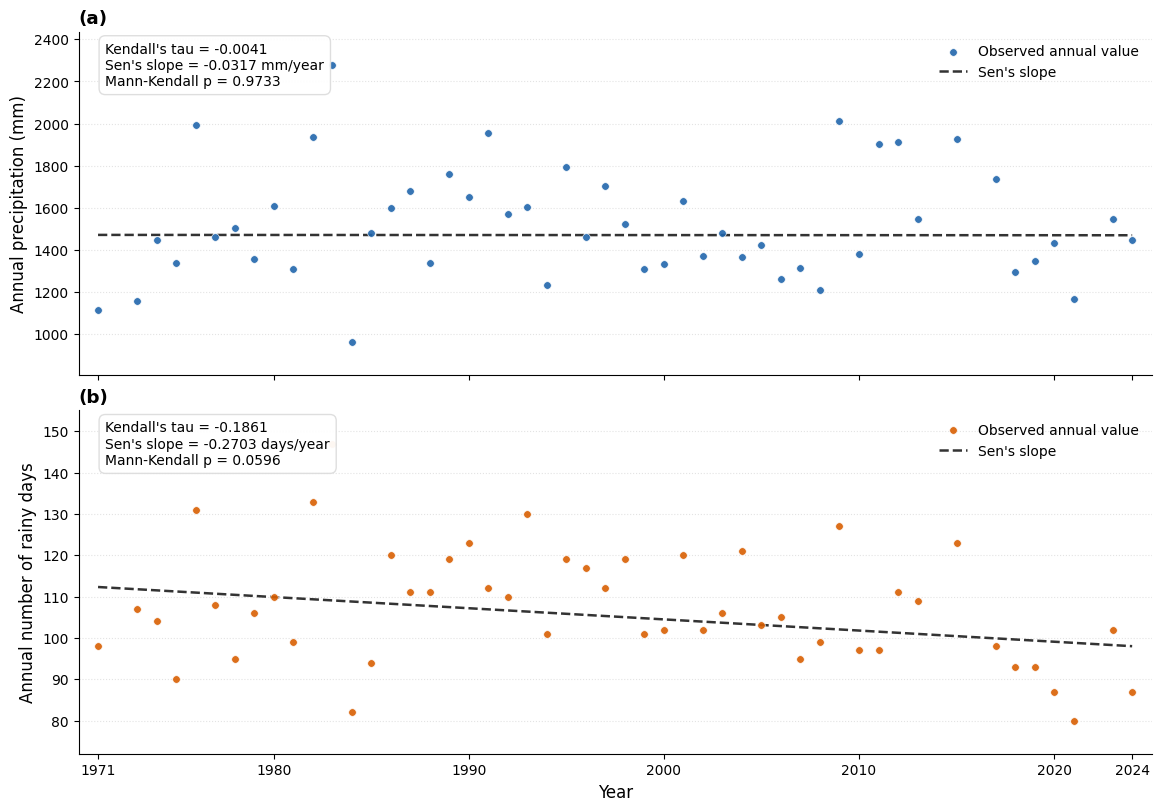

FIGURE 5 - LONG-TERM ANNUAL TRENDS
BOTUCATU, BRAZIL | 1971-2024
Complete calendar years: 50
Incomplete years excluded:
1972, 2014, 2016, 2022

Annual trend statistics:


,Variable,n,Kendall_tau,Sen_slope,p_MK
0,AAP,50,-0.00408,-0.03166,0.97331
1,ANRD,50,-0.18609,-0.27027,0.05962



Output files:
Figure_5_Long_Term_Annual_Precipitation_Rainy_Day_Trends_1971_2024.png
Figure_5_Long_Term_Annual_Precipitation_Rainy_Day_Trends_1971_2024.pdf
Figure_5_Long_Term_Annual_Precipitation_Rainy_Day_Trends_1971_2024.svg


In [ ]:

# ============================================================
# STEP 13 - LONG-TERM ANNUAL PRECIPITATION TRENDS
# Methodology section 2.4
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize annual accumulated precipitation (AAP)
# and annual number of rainy days (ANRD), together
# with their previously calculated Sen's slopes.
#
# Statistical results are retrieved from Step 10.
# No new hypothesis tests are performed.
#
# Only complete calendar years are included (n = 50).
# Incomplete years: 1972, 2014, 2016, and 2022.
#
# The Sen trend lines are shown for descriptive
# interpretation regardless of statistical significance.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RETRIEVE ANNUAL RECORDS AND TREND RESULTS
# ------------------------------------------------------------

annual = (
    anuais_validos.loc[
        anuais_validos["Complete"] == True,
        ["Ano", "AAP_mm", "ANRD_days"]
    ]
    .sort_values("Ano")
    .reset_index(drop=True)
)

trend_results = (
    tendencias_anuais
    .set_index("Variable")
    .copy()
)

# ------------------------------------------------------------
# 2. VERIFY DATA CONSISTENCY
# ------------------------------------------------------------

assert len(annual) == 50

assert annual["Ano"].is_unique

assert set(range(1971, 2025)) - set(
    annual["Ano"]
) == {1972, 2014, 2016, 2022}

assert annual[
    ["AAP_mm", "ANRD_days"]
].notna().all().all()

assert {"AAP", "ANRD"}.issubset(
    trend_results.index
)

assert (
    trend_results.loc[
        ["AAP", "ANRD"], "n"
    ] == 50
).all()

# ------------------------------------------------------------
# 3. DEFINE THE SEN TREND LINE
# ------------------------------------------------------------

def sen_trend_line(years, values, slope, line_years):

    """
    Construct a line using the Sen's slope estimated
    in Step 10.

    The intercept is calculated as the median of
    (observed value - slope * centered year).

    The slope is not recalculated.
    """

    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)

    reference_year = years.min()

    intercept = np.median(
        values - slope * (years - reference_year)
    )

    return (
        intercept
        + slope * (line_years - reference_year)
    )

# ------------------------------------------------------------
# 4. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(11.5, 8),
    sharex=True,
    constrained_layout=True
)

# ------------------------------------------------------------
# 5. DEFINE VARIABLES AND GRAPHICAL PROPERTIES
# ------------------------------------------------------------

plot_config = [
    {
        "key": "AAP",
        "column": "AAP_mm",
        "ylabel": "Annual precipitation (mm)",
        "color": "#2166AC",
        "panel": "(a)",
        "slope_unit": "mm/year"
    },
    {
        "key": "ANRD",
        "column": "ANRD_days",
        "ylabel": "Annual number of rainy days",
        "color": "#D95F02",
        "panel": "(b)",
        "slope_unit": "days/year"
    }
]

years = annual["Ano"].to_numpy(dtype=float)

line_years = np.linspace(
    1971, 2024, 200
)

# ------------------------------------------------------------
# 6. PLOT ANNUAL SERIES AND SEN TREND LINES
# ------------------------------------------------------------

for ax, config in zip(axes, plot_config):

    values = annual[
        config["column"]
    ].to_numpy(dtype=float)

    result = trend_results.loc[
        config["key"]
    ]

    sen_slope = float(
        result["Sen_slope"]
    )

    mk_p = float(
        result["p_MK"]
    )

    tau = float(
        result["Kendall_tau"]
    )

    # Observed annual values.
    ax.scatter(
        years,
        values,
        s=30,
        color=config["color"],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.9,
        zorder=3,
        label="Observed annual value"
    )

    # Sen trend line based on the slope from Step 10.
    fitted_values = sen_trend_line(
        years,
        values,
        sen_slope,
        line_years
    )

    ax.plot(
        line_years,
        fitted_values,
        color="#333333",
        linestyle="--",
        linewidth=1.8,
        label="Sen's slope"
    )

    # Panel identification.
    ax.set_title(
        config["panel"],
        loc="left",
        fontweight="bold"
    )

    ax.set_ylabel(
        config["ylabel"]
    )

    # Display previously calculated trend statistics.
    annotation = (
        f"Kendall's tau = {tau:.4f}\n"
        f"Sen's slope = {sen_slope:+.4f} "
        f"{config['slope_unit']}\n"
        f"Mann-Kendall p = {mk_p:.4f}"
    )

    ax.text(
        0.025,
        0.97,
        annotation,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=10,
        bbox={
            "facecolor": "white",
            "edgecolor": "#DDDDDD",
            "boxstyle": "round,pad=0.45",
            "alpha": 0.95
        }
    )

    # Axis limits based on observed data and trend line.
    lower = min(
        values.min(),
        fitted_values.min()
    )

    upper = max(
        values.max(),
        fitted_values.max()
    )

    padding = (upper - lower) * 0.12

    ax.set_ylim(
        lower - padding,
        upper + padding
    )

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.8,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper right",
        frameon=False
    )

# ------------------------------------------------------------
# 7. FORMAT THE HORIZONTAL AXIS
# ------------------------------------------------------------

axes[1].set_xlabel("Year")

axes[1].set_xlim(1970, 2025)

axes[1].set_xticks(
    [1971, 1980, 1990, 2000, 2010, 2020, 2024]
)

axes[1].tick_params(
    axis="x",
    labelbottom=True
)

# ------------------------------------------------------------
# 8. EXPORT FIGURE 5
# ------------------------------------------------------------

figure_name = (
    "Figure_5_Long_Term_Annual_"
    "Precipitation_Rainy_Day_Trends_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 9. REPORT RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("FIGURE 5 - LONG-TERM ANNUAL TRENDS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete calendar years:", len(annual))

print("Incomplete years excluded:")
print("1972, 2014, 2016, 2022")

print("\nAnnual trend statistics:")

display(
    tendencias_anuais[
        [
            "Variable",
            "n",
            "Kendall_tau",
            "Sen_slope",
            "p_MK"
        ]
    ].round(5)
)

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


In [ ]:

# ============================================================
# STEP 14 - MONTHLY CONSECUTIVE DRY-WEATHER WINDOWS
# Methodology section 2.5
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Identify consecutive dry-day sequences.
# 2. Count distinct dry episodes lasting at least
#    3, 5, and 7 consecutive days.
# 3. Calculate their mean and maximum durations.
# 4. Calculate the historical frequency of months
#    containing at least one qualifying episode.
#
# Definitions:
# Dry day: daily precipitation < 1.0 mm.
# Wet day: daily precipitation >= 1.0 mm.
#
# Each maximal consecutive dry sequence is counted
# as one distinct episode for each applicable threshold.
#
# Overlapping windows within the same sequence
# are not counted as separate episodes.
#
# Sequences are restricted to calendar-month boundaries.
# Only complete months are included.
# Missing observations are not imputed.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

DRY_THRESHOLD = 1.0
WINDOW_THRESHOLDS = [3, 5, 7]

# ------------------------------------------------------------
# 1. PREPARE DAILY PRECIPITATION RECORDS
# ------------------------------------------------------------

dry_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

dry_data["Data"] = pd.to_datetime(
    dry_data["Data"]
)

dry_data["Year"] = dry_data["Data"].dt.year
dry_data["Month"] = dry_data["Data"].dt.month

dry_data = (
    dry_data
    .sort_values("Data")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. SELECT COMPLETE CALENDAR MONTHS
# ------------------------------------------------------------

# Complete months were identified in Step 05.
complete_months = (
    mensais_validos[
        ["Year", "Month"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(complete_months) == 641

# Retain daily observations belonging to complete months.
dry_data = dry_data.merge(
    complete_months,
    on=["Year", "Month"],
    how="inner",
    validate="many_to_one"
)

assert dry_data[
    "Precipitacao_mm"
].notna().all()

assert not dry_data[
    "Data"
].duplicated().any()

# ------------------------------------------------------------
# 3. DEFINE DRY-EPISODE IDENTIFICATION
# ------------------------------------------------------------

def identify_dry_episodes(precipitation):

    """
    Identify maximal consecutive dry-day sequences.

    A day is classified as dry when precipitation
    is strictly lower than 1.0 mm.

    Returns:
    - start indices of dry episodes
    - end indices (exclusive)
    - duration of each episode

    Each uninterrupted sequence is counted once.
    """

    precipitation = np.asarray(
        precipitation,
        dtype=float
    )

    if not np.isfinite(precipitation).all():
        raise ValueError(
            "The period contains missing observations."
        )

    dry_flags = (
        precipitation < DRY_THRESHOLD
    ).astype(int)

    # Add boundary values to identify sequence changes.
    padded = np.concatenate(
        ([0], dry_flags, [0])
    )

    changes = np.diff(padded)

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    lengths = ends - starts

    return starts, ends, lengths

# ------------------------------------------------------------
# 4. IDENTIFY EPISODES IN EACH COMPLETE MONTH
# ------------------------------------------------------------

monthly_records = []
episode_records = []

for (year, month), group in dry_data.groupby(
    ["Year", "Month"],
    sort=True
):

    group = (
        group.sort_values("Data")
        .reset_index(drop=True)
    )

    precipitation = group[
        "Precipitacao_mm"
    ].to_numpy(dtype=float)

    dates = group["Data"].to_numpy()

    # Identify consecutive dry sequences.
    starts, ends, lengths = identify_dry_episodes(
        precipitation
    )

    # Record monthly indicators.
    record = {
        "Year": int(year),
        "Month": int(month),
        "Valid_days": len(group),
        "Total_dry_episodes": len(lengths)
    }

    # Count distinct episodes meeting each threshold.
    for k in WINDOW_THRESHOLDS:

        qualifying = lengths >= k

        episode_count = int(
            qualifying.sum()
        )

        record[
            f"Episodes_ge{k}"
        ] = episode_count

        record[
            f"Has_episode_ge{k}"
        ] = int(episode_count > 0)

    monthly_records.append(record)

    # Preserve individual dry episodes for verification.
    for start, end, length in zip(
        starts,
        ends,
        lengths
    ):

        episode_records.append({
            "Year": int(year),
            "Month": int(month),
            "Start_date": pd.Timestamp(
                dates[start]
            ),
            "End_date": pd.Timestamp(
                dates[end - 1]
            ),
            "Duration_days": int(length)
        })

# ------------------------------------------------------------
# 5. CREATE MONTHLY AND EPISODE DATAFRAMES
# ------------------------------------------------------------

janelas_mensais = pd.DataFrame(
    monthly_records
)

episodios_secos = pd.DataFrame(
    episode_records
)

# ------------------------------------------------------------
# 6. VERIFY INDIVIDUAL MONTHLY RESULTS
# ------------------------------------------------------------

assert len(janelas_mensais) == 641

assert janelas_mensais[
    "Year"
].nunique() == 54

assert not janelas_mensais.duplicated(
    ["Year", "Month"]
).any()

# Every episode lasting >= 7 days must also meet
# the minimum duration of 5 and 3 days.
assert (
    janelas_mensais["Episodes_ge7"]
    <= janelas_mensais["Episodes_ge5"]
).all()

assert (
    janelas_mensais["Episodes_ge5"]
    <= janelas_mensais["Episodes_ge3"]
).all()

# Verify the same ordering for event occurrence.
assert (
    janelas_mensais["Has_episode_ge7"]
    <= janelas_mensais["Has_episode_ge5"]
).all()

assert (
    janelas_mensais["Has_episode_ge5"]
    <= janelas_mensais["Has_episode_ge3"]
).all()

# All episode durations must be positive.
assert (
    episodios_secos["Duration_days"] >= 1
).all()

# Episodes must remain within a single calendar month.
assert (
    episodios_secos["Start_date"].dt.month
    == episodios_secos["End_date"].dt.month
).all()

# ------------------------------------------------------------
# 7. CALCULATE HISTORICAL MONTHLY FREQUENCIES
# ------------------------------------------------------------

# Historical frequency (%) is the percentage of complete
# calendar-month records containing at least one
# qualifying dry episode.
#
# Frequency_k (%) =
# (Months with >=1 episode of duration >=k /
#  Total complete months for the calendar month) * 100
#
# This is an occurrence frequency, not the percentage
# of dry days.

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

summary_records = []

for month in range(1, 13):

    month_data = janelas_mensais[
        janelas_mensais["Month"] == month
    ]

    month_episodes = episodios_secos[
        episodios_secos["Month"] == month
    ]

    n_months = len(month_data)

    for k in WINDOW_THRESHOLDS:

        months_with_episode = int(
            month_data[
                f"Has_episode_ge{k}"
            ].sum()
        )

        total_episodes = int(
            month_data[
                f"Episodes_ge{k}"
            ].sum()
        )

        qualifying_lengths = (
            month_episodes.loc[
                month_episodes["Duration_days"] >= k,
                "Duration_days"
            ]
            .to_numpy(dtype=float)
        )

        # Frequency of monthly records containing
        # at least one qualifying episode.
        frequency_percent = (
            months_with_episode / n_months * 100
        )

        # Mean number of episodes per complete month.
        mean_episodes = (
            total_episodes / n_months
        )

        # Durations are summarized over qualifying
        # episodes, not over months without episodes.
        mean_duration = (
            float(np.mean(qualifying_lengths))
            if len(qualifying_lengths) > 0
            else np.nan
        )

        max_duration = (
            int(np.max(qualifying_lengths))
            if len(qualifying_lengths) > 0
            else np.nan
        )

        summary_records.append({
            "Month": month,
            "Month_name": month_names[month],
            "Minimum_duration_days": k,
            "n_complete_months": n_months,
            "Months_with_episode": months_with_episode,
            "Frequency_percent": frequency_percent,
            "Total_episodes": total_episodes,
            "Mean_episodes_per_month": mean_episodes,
            "Mean_duration_days": mean_duration,
            "Maximum_duration_days": max_duration
        })

# ------------------------------------------------------------
# 8. CREATE THE MONTHLY SUMMARY TABLE
# ------------------------------------------------------------

resumo_janelas_mensais = pd.DataFrame(
    summary_records
)

assert len(resumo_janelas_mensais) == 36

assert resumo_janelas_mensais[
    "Frequency_percent"
].between(0, 100).all()

# Verify consistency with individual episode records.
for row in resumo_janelas_mensais.itertuples():

    counted = (
        (episodios_secos["Month"] == row.Month)
        &
        (
            episodios_secos["Duration_days"]
            >= row.Minimum_duration_days
        )
    ).sum()

    assert counted == row.Total_episodes

# ------------------------------------------------------------
# 9. PREPARE THE MONTHLY FREQUENCY TABLE
# ------------------------------------------------------------

tabela_frequencia_janelas = (
    resumo_janelas_mensais
    .pivot(
        index="Month_name",
        columns="Minimum_duration_days",
        values="Frequency_percent"
    )
    .reindex(
        list(month_names.values())
    )
)

tabela_frequencia_janelas.columns = [
    f"At_least_{k}_days_percent"
    for k in tabela_frequencia_janelas.columns
]

tabela_frequencia_janelas = (
    tabela_frequencia_janelas
    .reset_index()
    .rename(columns={
        "Month_name": "Month"
    })
)

# ------------------------------------------------------------
# 10. DISPLAY MONTHLY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("MONTHLY CONSECUTIVE DRY-WEATHER WINDOWS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete calendar months:", len(janelas_mensais))

print(
    "Individual dry episodes:",
    len(episodios_secos)
)

print("Minimum durations:", WINDOW_THRESHOLDS)

print("\nHISTORICAL MONTHLY FREQUENCY (%):")

display(
    tabela_frequencia_janelas.round(2)
)

print("\nMONTHLY EPISODE STATISTICS:")

display(
    resumo_janelas_mensais.round(2)
)

# ------------------------------------------------------------
# 11. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_14_Monthly_Dry_Weather_"
    "Windows_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    janelas_mensais.to_excel(
        writer,
        sheet_name="Individual_Months",
        index=False
    )

    resumo_janelas_mensais.to_excel(
        writer,
        sheet_name="Monthly_Summary",
        index=False
    )

    tabela_frequencia_janelas.to_excel(
        writer,
        sheet_name="Monthly_Frequency",
        index=False
    )

    episodios_secos.to_excel(
        writer,
        sheet_name="Individual_Dry_Episodes",
        index=False
    )

# ------------------------------------------------------------
# 12. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 14 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


MONTHLY CONSECUTIVE DRY-WEATHER WINDOWS
BOTUCATU, BRAZIL | 1971-2024
Complete calendar months: 641
Individual dry episodes: 2993
Minimum durations: [3, 5, 7]

HISTORICAL MONTHLY FREQUENCY (%):


,Month,At_least_3_days_percent,At_least_5_days_percent,At_least_7_days_percent
0,January,96.23,64.15,20.75
1,February,90.74,68.52,37.04
2,March,100.00,88.68,54.72
3,April,100.00,100.00,83.33
4,May,100.00,98.15,96.30
5,June,100.00,100.00,98.15
6,July,100.00,100.00,98.11
7,August,100.00,100.00,100.00
8,September,100.00,96.23,84.91
9,October,100.00,96.23,81.13



MONTHLY EPISODE STATISTICS:


,Month,Month_name,Minimum_duration_days,n_complete_months,Months_with_episode,Frequency_percent,Total_episodes,Mean_episodes_per_month,Mean_duration_days,Maximum_duration_days
0,1,January,3,53,51,96.23,111,2.09,4.51,15
1,1,January,5,53,34,64.15,43,0.81,6.12,15
2,1,January,7,53,11,20.75,12,0.23,8.08,15
3,2,February,3,54,49,90.74,117,2.17,4.90,13
4,2,February,5,54,37,68.52,53,0.98,6.77,13
5,2,February,7,54,20,37.04,23,0.43,8.61,13
6,3,March,3,53,53,100.00,144,2.72,5.38,16
7,3,March,5,53,47,88.68,78,1.47,7.04,16
8,3,March,7,53,29,54.72,36,0.68,9.00,16
9,4,April,3,54,54,100.00,151,2.80,7.81,29



STEP 14 COMPLETED SUCCESSFULLY
Output file: Step_14_Monthly_Dry_Weather_Windows_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 15 - TEN-DAY CONSECUTIVE DRY-WEATHER WINDOWS
# Methodology section 2.5
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Identify consecutive dry-day episodes within
#    each complete ten-day calendar period.
# 2. Count episodes lasting at least 3, 5, and 7 days.
# 3. Calculate mean and maximum episode durations.
# 4. Calculate historical occurrence frequencies
#    for each calendar month and ten-day period.
#
# Definitions:
# Dry day: precipitation < 1.0 mm.
# Wet day: precipitation >= 1.0 mm.
#
# D1 = days 1-10
# D2 = days 11-20
# D3 = days 21 through the end of the month
#
# Each maximal uninterrupted dry sequence is
# counted once for each applicable threshold.
#
# Overlapping windows are not counted separately.
# Sequences do not cross ten-day period boundaries.
# Missing observations are not imputed.
#
# Input:
# dados_limpos (Step 01)
# decendiais_validos (Step 07)
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

DRY_THRESHOLD = 1.0
WINDOW_THRESHOLDS = [3, 5, 7]
PERIOD_ORDER = ["D1", "D2", "D3"]

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 1. PREPARE THE DAILY PRECIPITATION DATA
# ------------------------------------------------------------

dry_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

dry_data["Data"] = pd.to_datetime(
    dry_data["Data"]
)

dry_data["Year"] = dry_data["Data"].dt.year
dry_data["Month"] = dry_data["Data"].dt.month
dry_data["Day"] = dry_data["Data"].dt.day

dry_data["Ten_day"] = np.select(
    [
        dry_data["Day"] <= 10,
        dry_data["Day"].between(11, 20),
        dry_data["Day"] >= 21
    ],
    PERIOD_ORDER,
    default="Invalid"
)

assert not (
    dry_data["Ten_day"] == "Invalid"
).any()

# ------------------------------------------------------------
# 2. RETRIEVE COMPLETE TEN-DAY PERIODS
# ------------------------------------------------------------

complete_periods = (
    decendiais_validos[
        ["Year", "Month", "Ten_day", "Expected_days"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(complete_periods) == 1935

assert not complete_periods.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

# Retain only daily records from complete periods.
dry_data = dry_data.merge(
    complete_periods,
    on=["Year", "Month", "Ten_day"],
    how="inner",
    validate="many_to_one"
)

dry_data = (
    dry_data
    .sort_values("Data")
    .reset_index(drop=True)
)

assert dry_data[
    "Precipitacao_mm"
].notna().all()

assert dry_data["Data"].is_unique

assert dry_data["Year"].nunique() == 54

# ------------------------------------------------------------
# 3. DEFINE DRY-EPISODE IDENTIFICATION
# ------------------------------------------------------------

def identify_ten_day_dry_episodes(precipitation):

    """
    Identify maximal uninterrupted dry-day sequences
    within one complete ten-day calendar period.

    A dry day has precipitation strictly below 1.0 mm.

    Returns:
    - start indices
    - end indices (exclusive)
    - episode durations

    Each sequence is counted once, regardless
    of how many overlapping windows it contains.
    """

    precipitation = np.asarray(
        precipitation,
        dtype=float
    )

    if not np.isfinite(precipitation).all():
        raise ValueError(
            "The period contains missing observations."
        )

    dry_flags = (
        precipitation < DRY_THRESHOLD
    ).astype(int)

    padded = np.concatenate(
        ([0], dry_flags, [0])
    )

    changes = np.diff(padded)

    starts = np.where(
        changes == 1
    )[0]

    ends = np.where(
        changes == -1
    )[0]

    lengths = ends - starts

    return starts, ends, lengths

# ------------------------------------------------------------
# 4. IDENTIFY EPISODES IN EACH COMPLETE PERIOD
# ------------------------------------------------------------

period_records = []
episode_records = []

for (year, month, period), group in (
    dry_data.groupby(
        ["Year", "Month", "Ten_day"],
        sort=True
    )
):

    group = (
        group
        .sort_values("Data")
        .reset_index(drop=True)
    )

    expected_days = int(
        group["Expected_days"].iloc[0]
    )

    # Verify complete and consecutive daily coverage.
    assert len(group) == expected_days

    assert (
        group["Data"]
        .diff()
        .dropna()
        .dt.days
        == 1
    ).all()

    precipitation = group[
        "Precipitacao_mm"
    ].to_numpy(dtype=float)

    dates = group["Data"].to_numpy()

    starts, ends, lengths = (
        identify_ten_day_dry_episodes(
            precipitation
        )
    )

    record = {
        "Year": int(year),
        "Month": int(month),
        "Ten_day": period,
        "Period_days": expected_days,
        "Total_dry_episodes": len(lengths)
    }

    # Count episodes for each minimum duration.
    for k in WINDOW_THRESHOLDS:

        count = int(
            np.sum(lengths >= k)
        )

        record[
            f"Episodes_ge{k}"
        ] = count

        record[
            f"Has_episode_ge{k}"
        ] = int(count > 0)

    period_records.append(record)

    # Preserve every identified dry sequence.
    for start, end, length in zip(
        starts, ends, lengths
    ):

        episode_records.append({
            "Year": int(year),
            "Month": int(month),
            "Ten_day": period,
            "Start_date": pd.Timestamp(
                dates[start]
            ),
            "End_date": pd.Timestamp(
                dates[end - 1]
            ),
            "Duration_days": int(length)
        })

# ------------------------------------------------------------
# 5. CREATE INDIVIDUAL RESULTS
# ------------------------------------------------------------

janelas_decendiais = pd.DataFrame(
    period_records
)

episodios_decendiais = pd.DataFrame(
    episode_records
)

# ------------------------------------------------------------
# 6. VERIFY INDIVIDUAL RESULTS
# ------------------------------------------------------------

assert len(janelas_decendiais) == 1935

assert janelas_decendiais[
    "Year"
].nunique() == 54

assert not janelas_decendiais.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

# A longer minimum duration cannot produce
# more qualifying episodes.
assert (
    janelas_decendiais["Episodes_ge7"]
    <= janelas_decendiais["Episodes_ge5"]
).all()

assert (
    janelas_decendiais["Episodes_ge5"]
    <= janelas_decendiais["Episodes_ge3"]
).all()

assert (
    janelas_decendiais["Has_episode_ge7"]
    <= janelas_decendiais["Has_episode_ge5"]
).all()

assert (
    janelas_decendiais["Has_episode_ge5"]
    <= janelas_decendiais["Has_episode_ge3"]
).all()

assert (
    episodios_decendiais["Duration_days"] >= 1
).all()

# Episodes must remain within the same
# calendar month and ten-day period.
assert (
    episodios_decendiais["Start_date"].dt.month
    == episodios_decendiais["End_date"].dt.month
).all()

assert (
    episodios_decendiais["End_date"]
    - episodios_decendiais["Start_date"]
).dt.days.add(1).eq(
    episodios_decendiais["Duration_days"]
).all()

# ------------------------------------------------------------
# 7. CALCULATE HISTORICAL TEN-DAY FREQUENCIES
# ------------------------------------------------------------

# Frequency (%):
#
# Number of complete historical ten-day periods
# containing at least one qualifying dry episode
# divided by the total number of complete periods
# for the same month and ten-day category.
#
# The denominator varies according to data coverage.

summary_records = []

for month in range(1, 13):

    for period in PERIOD_ORDER:

        period_data = janelas_decendiais.loc[
            (janelas_decendiais["Month"] == month)
            &
            (janelas_decendiais["Ten_day"] == period)
        ]

        period_episodes = episodios_decendiais.loc[
            (episodios_decendiais["Month"] == month)
            &
            (episodios_decendiais["Ten_day"] == period)
        ]

        n_periods = len(period_data)

        assert n_periods > 0

        for k in WINDOW_THRESHOLDS:

            periods_with_episode = int(
                period_data[
                    f"Has_episode_ge{k}"
                ].sum()
            )

            total_episodes = int(
                period_data[
                    f"Episodes_ge{k}"
                ].sum()
            )

            qualifying_lengths = (
                period_episodes.loc[
                    period_episodes["Duration_days"] >= k,
                    "Duration_days"
                ]
                .to_numpy(dtype=float)
            )

            frequency_percent = (
                periods_with_episode
                / n_periods
                * 100
            )

            mean_episodes = (
                total_episodes / n_periods
            )

            # Mean and maximum refer only to
            # episodes meeting the minimum duration.
            mean_duration = (
                float(np.mean(qualifying_lengths))
                if len(qualifying_lengths) > 0
                else np.nan
            )

            max_duration = (
                int(np.max(qualifying_lengths))
                if len(qualifying_lengths) > 0
                else np.nan
            )

            summary_records.append({
                "Month": month,
                "Month_name": MONTH_NAMES[month],
                "Ten_day": period,
                "Minimum_duration_days": k,
                "n_complete_periods": n_periods,
                "Periods_with_episode": periods_with_episode,
                "Frequency_percent": frequency_percent,
                "Total_episodes": total_episodes,
                "Mean_episodes_per_period": mean_episodes,
                "Mean_duration_days": mean_duration,
                "Maximum_duration_days": max_duration
            })

# ------------------------------------------------------------
# 8. CREATE THE SUMMARY TABLE
# ------------------------------------------------------------

resumo_janelas_decendiais = pd.DataFrame(
    summary_records
)

assert len(resumo_janelas_decendiais) == 108

assert resumo_janelas_decendiais[
    "Frequency_percent"
].between(0, 100).all()

# Every historical period is included exactly once
# within each minimum-duration category.
for k in WINDOW_THRESHOLDS:

    subset = resumo_janelas_decendiais.loc[
        resumo_janelas_decendiais[
            "Minimum_duration_days"
        ] == k
    ]

    assert (
        subset["n_complete_periods"].sum()
        == 1935
    )

# ------------------------------------------------------------
# 9. VERIFY SUMMARY COUNTS
# ------------------------------------------------------------

for row in resumo_janelas_decendiais.itertuples():

    counted_episodes = (
        (episodios_decendiais["Month"] == row.Month)
        &
        (episodios_decendiais["Ten_day"] == row.Ten_day)
        &
        (
            episodios_decendiais["Duration_days"]
            >= row.Minimum_duration_days
        )
    ).sum()

    assert counted_episodes == row.Total_episodes

# ------------------------------------------------------------
# 10. PREPARE THE FREQUENCY TABLE
# ------------------------------------------------------------

tabela_frequencia_decendial = (
    resumo_janelas_decendiais
    .pivot(
        index=[
            "Month",
            "Month_name",
            "Ten_day"
        ],
        columns="Minimum_duration_days",
        values="Frequency_percent"
    )
    .rename(columns={
        3: "At_least_3_days_percent",
        5: "At_least_5_days_percent",
        7: "At_least_7_days_percent"
    })
    .reset_index()
    .sort_values(["Month", "Ten_day"])
    .reset_index(drop=True)
)

tabela_frequencia_decendial.columns.name = None

assert len(tabela_frequencia_decendial) == 36

assert tabela_frequencia_decendial[
    [
        "At_least_3_days_percent",
        "At_least_5_days_percent",
        "At_least_7_days_percent"
    ]
].notna().all().all()

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("TEN-DAY CONSECUTIVE DRY-WEATHER WINDOWS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print(
    "Complete ten-day periods:",
    len(janelas_decendiais)
)

print(
    "Individual dry episodes:",
    len(episodios_decendiais)
)

print(
    "Historical groups:",
    len(tabela_frequencia_decendial)
)

print(
    "Minimum durations:",
    WINDOW_THRESHOLDS
)

print("\nHISTORICAL TEN-DAY FREQUENCY (%):")

display(
    tabela_frequencia_decendial.round(2)
)

print("\nTEN-DAY EPISODE STATISTICS:")

display(
    resumo_janelas_decendiais.round(2)
)

# ------------------------------------------------------------
# 12. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_15_Ten_Day_Dry_Weather_"
    "Windows_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    janelas_decendiais.to_excel(
        writer,
        sheet_name="Individual_TenDay_Periods",
        index=False
    )

    resumo_janelas_decendiais.to_excel(
        writer,
        sheet_name="TenDay_Summary",
        index=False
    )

    tabela_frequencia_decendial.to_excel(
        writer,
        sheet_name="TenDay_Frequency",
        index=False
    )

    episodios_decendiais.to_excel(
        writer,
        sheet_name="Individual_Dry_Episodes",
        index=False
    )

# ------------------------------------------------------------
# 13. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 15 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


TEN-DAY CONSECUTIVE DRY-WEATHER WINDOWS
BOTUCATU, BRAZIL | 1971-2024
Complete ten-day periods: 1935
Individual dry episodes: 3729
Historical groups: 36
Minimum durations: [3, 5, 7]

HISTORICAL TEN-DAY FREQUENCY (%):


,Month,Month_name,Ten_day,At_least_3_days_percent,At_least_5_days_percent,At_least_7_days_percent
0,1,January,D1,51.85,22.22,1.85
1,1,January,D2,59.26,25.93,9.26
2,1,January,D3,67.92,24.53,3.77
3,2,February,D1,61.11,27.78,12.96
4,2,February,D2,64.81,22.22,3.70
5,2,February,D3,61.11,24.07,7.41
6,3,March,D1,75.93,42.59,11.11
7,3,March,D2,81.48,48.15,18.52
8,3,March,D3,84.91,52.83,26.42
9,4,April,D1,96.30,68.52,35.19



TEN-DAY EPISODE STATISTICS:


,Month,Month_name,Ten_day,Minimum_duration_days,n_complete_periods,Periods_with_episode,Frequency_percent,Total_episodes,Mean_episodes_per_period,Mean_duration_days,Maximum_duration_days
0,1,January,D1,3,54,28,51.85,31,0.57,4.32,7
1,1,January,D1,5,54,12,22.22,12,0.22,5.58,7
2,1,January,D1,7,54,1,1.85,1,0.02,7.00,7
3,1,January,D2,3,54,32,59.26,35,0.65,4.57,9
4,1,January,D2,5,54,14,25.93,14,0.26,6.14,9
...,...,...,...,...,...,...,...,...,...,...,...
103,12,December,D2,5,54,21,38.89,21,0.39,6.10,9
104,12,December,D2,7,54,5,9.26,5,0.09,8.00,9
105,12,December,D3,3,54,39,72.22,43,0.80,4.49,9
106,12,December,D3,5,54,16,29.63,16,0.30,6.25,9



STEP 15 COMPLETED SUCCESSFULLY
Output file: Step_15_Ten_Day_Dry_Weather_Windows_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

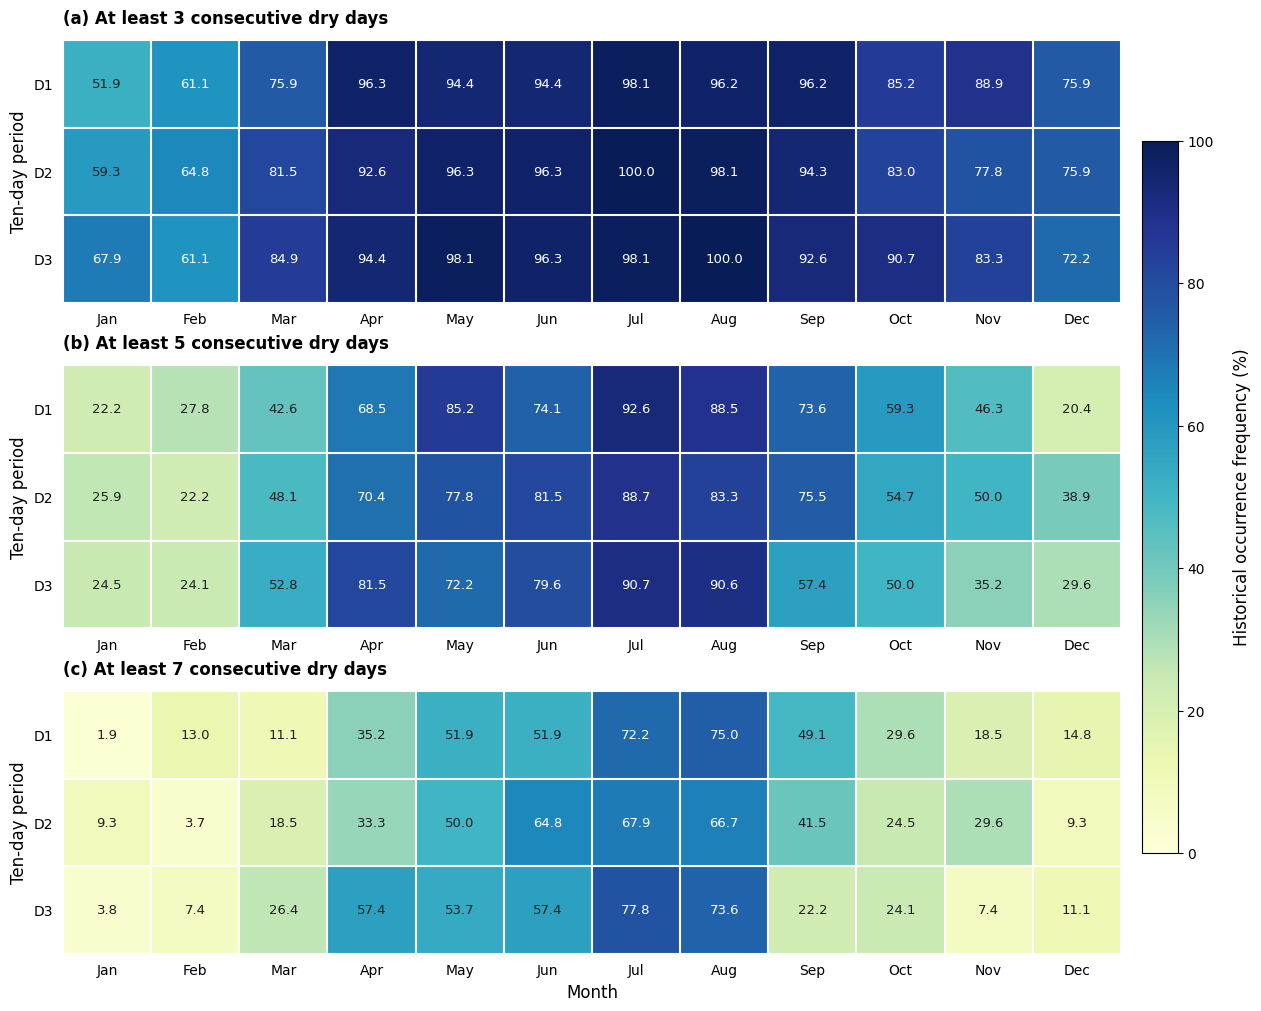

FIGURE 6 - TEN-DAY DRY-WEATHER WINDOW FREQUENCIES
BOTUCATU, BRAZIL | 1971-2024
Complete ten-day periods: 1935
Historical ten-day groups: 36
Minimum dry-window durations: 3, 5, and 7 days

Output files:
Figure_6_Ten_Day_Dry_Weather_Window_Frequencies_1971_2024.png
Figure_6_Ten_Day_Dry_Weather_Window_Frequencies_1971_2024.pdf
Figure_6_Ten_Day_Dry_Weather_Window_Frequencies_1971_2024.svg


In [ ]:

# ============================================================
# STEP 16 - TEN-DAY DRY-WEATHER WINDOW FREQUENCIES
# Methodology section 2.5
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize the historical frequency of ten-day periods
# containing at least one consecutive dry-weather episode
# lasting at least 3, 5, or 7 days.
#
# Panel A: At least 3 consecutive dry days.
# Panel B: At least 5 consecutive dry days.
# Panel C: At least 7 consecutive dry days.
#
# A dry day has daily precipitation < 1.0 mm.
#
# Frequencies were previously calculated in Step 15
# from 1,935 complete ten-day periods.
#
# No new statistical calculations are performed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RETRIEVE RESULTS FROM STEP 15
# ------------------------------------------------------------

frequency_data = (
    tabela_frequencia_decendial
    .copy()
    .sort_values(["Month", "Ten_day"])
    .reset_index(drop=True)
)

MONTH_ORDER = list(range(1, 13))

MONTH_LABELS = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

PERIOD_ORDER = ["D1", "D2", "D3"]

FREQUENCY_COLUMNS = {
    3: "At_least_3_days_percent",
    5: "At_least_5_days_percent",
    7: "At_least_7_days_percent"
}

# ------------------------------------------------------------
# 2. VERIFY INPUT DATA
# ------------------------------------------------------------

assert len(frequency_data) == 36

assert not frequency_data.duplicated(
    ["Month", "Ten_day"]
).any()

assert set(frequency_data["Month"]) == set(
    MONTH_ORDER
)

assert set(frequency_data["Ten_day"]) == set(
    PERIOD_ORDER
)

for column in FREQUENCY_COLUMNS.values():

    assert frequency_data[column].notna().all()

    assert frequency_data[column].between(
        0, 100
    ).all()

# Longer dry-weather episodes cannot occur
# more frequently than shorter ones.

assert (
    frequency_data["At_least_7_days_percent"]
    <= frequency_data["At_least_5_days_percent"]
).all()

assert (
    frequency_data["At_least_5_days_percent"]
    <= frequency_data["At_least_3_days_percent"]
).all()

# ------------------------------------------------------------
# 3. PREPARE THE FREQUENCY MATRICES
# ------------------------------------------------------------

frequency_matrices = {}

for duration, column in FREQUENCY_COLUMNS.items():

    matrix = (
        frequency_data
        .pivot(
            index="Ten_day",
            columns="Month",
            values=column
        )
        .reindex(
            index=PERIOD_ORDER,
            columns=MONTH_ORDER
        )
        .to_numpy(dtype=float)
    )

    assert matrix.shape == (3, 12)

    assert np.isfinite(matrix).all()

    frequency_matrices[duration] = matrix

# ------------------------------------------------------------
# 4. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12.5, 10),
    constrained_layout=True
)

# ------------------------------------------------------------
# 5. DEFINE PANEL LABELS
# ------------------------------------------------------------

panel_config = [
    {
        "duration": 3,
        "title": "(a) At least 3 consecutive dry days"
    },
    {
        "duration": 5,
        "title": "(b) At least 5 consecutive dry days"
    },
    {
        "duration": 7,
        "title": "(c) At least 7 consecutive dry days"
    }
]

# ------------------------------------------------------------
# 6. GENERATE THE THREE HEATMAP PANELS
# ------------------------------------------------------------

for ax, config in zip(axes, panel_config):

    duration = config["duration"]

    matrix = frequency_matrices[duration]

    heatmap = ax.imshow(
        matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        aspect="auto",
        interpolation="nearest"
    )

    # Identify the panel.
    ax.set_title(
        config["title"],
        loc="left",
        fontweight="bold",
        pad=12
    )

    # Calendar months on the horizontal axis.
    ax.set_xticks(np.arange(12))
    ax.set_xticklabels(MONTH_LABELS)

    # Ten-day periods on the vertical axis.
    ax.set_yticks(np.arange(3))
    ax.set_yticklabels(PERIOD_ORDER)

    ax.set_ylabel("Ten-day period")

    # Display frequencies inside each cell.
    for i in range(3):

        for j in range(12):

            value = matrix[i, j]

            text_color = (
                "white"
                if value >= 60
                else "#202020"
            )

            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=9.5,
                color=text_color
            )

    # Add white boundaries between cells.
    ax.set_xticks(
        np.arange(-0.5, 12, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 3, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.5
    )

    # Remove tick marks while preserving labels.
    ax.tick_params(
        axis="both",
        which="both",
        length=0,
        pad=7
    )

    # Remove external spines.
    for spine in ax.spines.values():
        spine.set_visible(False)

# ------------------------------------------------------------
# 7. ADD THE SHARED COLOR BAR
# ------------------------------------------------------------

colorbar = fig.colorbar(
    heatmap,
    ax=axes,
    shrink=0.78,
    pad=0.02,
    ticks=np.arange(0, 101, 20)
)

colorbar.set_label(
    "Historical occurrence frequency (%)",
    rotation=90,
    labelpad=14
)

# Add the month label to the bottom panel.
axes[-1].set_xlabel("Month")

# ------------------------------------------------------------
# 8. EXPORT FIGURE 6
# ------------------------------------------------------------

figure_name = (
    "Figure_6_Ten_Day_Dry_Weather_"
    "Window_Frequencies_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 9. REPORT OUTPUT
# ------------------------------------------------------------

print("=" * 70)
print("FIGURE 6 - TEN-DAY DRY-WEATHER WINDOW FREQUENCIES")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete ten-day periods: 1935")
print("Historical ten-day groups: 36")
print("Minimum dry-window durations: 3, 5, and 7 days")

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


In [ ]:

# ============================================================
# STEP 17 - MONTHLY FIRST-ORDER MARKOV CHAINS
# Methodology section 2.6
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Classify daily precipitation into dry and wet states.
# 2. Count first-order daily transitions.
# 3. Estimate monthly transition probabilities:
#    P_DD, P_DW, P_WD, and P_WW.
# 4. Characterize dry- and wet-day persistence.
#
# States:
# D = Dry day (precipitation < 1.0 mm)
# W = Wet day (precipitation >= 1.0 mm)
#
# Transition probabilities:
# P_DD = N_DD / (N_DD + N_DW)
# P_DW = N_DW / (N_DD + N_DW)
# P_WD = N_WD / (N_WD + N_WW)
# P_WW = N_WW / (N_WD + N_WW)
#
# Only complete calendar months are included.
# Transitions do not cross calendar-month boundaries.
# Missing observations are not imputed.
#
# Input:
# dados_limpos (Step 01)
# mensais_validos (Step 05)
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

RAIN_THRESHOLD = 1.0

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 1. PREPARE THE DAILY PRECIPITATION DATA
# ------------------------------------------------------------

markov_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

markov_data["Data"] = pd.to_datetime(
    markov_data["Data"]
)

markov_data["Year"] = (
    markov_data["Data"].dt.year
)

markov_data["Month"] = (
    markov_data["Data"].dt.month
)

markov_data = (
    markov_data
    .sort_values("Data")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. SELECT COMPLETE CALENDAR MONTHS
# ------------------------------------------------------------

complete_months = (
    mensais_validos[
        ["Year", "Month"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(complete_months) == 641

# Retain observations from complete months only.
markov_data = markov_data.merge(
    complete_months,
    on=["Year", "Month"],
    how="inner",
    validate="many_to_one"
)

assert markov_data[
    "Precipitacao_mm"
].notna().all()

assert markov_data["Data"].is_unique

assert markov_data["Year"].nunique() == 54

# ------------------------------------------------------------
# 3. CLASSIFY DAILY DRY AND WET STATES
# ------------------------------------------------------------

markov_data["State"] = np.where(
    markov_data["Precipitacao_mm"] < RAIN_THRESHOLD,
    "D",
    "W"
)

assert markov_data["State"].isin(
    ["D", "W"]
).all()

# ------------------------------------------------------------
# 4. COUNT TRANSITIONS WITHIN EACH COMPLETE MONTH
# ------------------------------------------------------------

transition_records = []

for (year, month), group in markov_data.groupby(
    ["Year", "Month"],
    sort=True
):

    group = (
        group
        .sort_values("Data")
        .reset_index(drop=True)
    )

    # Confirm that all observations are consecutive.
    assert (
        group["Data"]
        .diff()
        .dropna()
        .dt.days
        == 1
    ).all()

    states = group[
        "State"
    ].to_numpy()

    # A transition connects day t to day t+1.
    previous_state = states[:-1]
    next_state = states[1:]

    # Count each possible transition.
    N_DD = int(np.sum(
        (previous_state == "D")
        &
        (next_state == "D")
    ))

    N_DW = int(np.sum(
        (previous_state == "D")
        &
        (next_state == "W")
    ))

    N_WD = int(np.sum(
        (previous_state == "W")
        &
        (next_state == "D")
    ))

    N_WW = int(np.sum(
        (previous_state == "W")
        &
        (next_state == "W")
    ))

    n_transitions = len(states) - 1

    # Verify that all possible transitions were counted.
    assert (
        N_DD + N_DW + N_WD + N_WW
        == n_transitions
    )

    transition_records.append({
        "Year": int(year),
        "Month": int(month),
        "Valid_days": len(states),
        "Transitions": n_transitions,
        "N_DD": N_DD,
        "N_DW": N_DW,
        "N_WD": N_WD,
        "N_WW": N_WW
    })

# ------------------------------------------------------------
# 5. CREATE INDIVIDUAL MONTHLY TRANSITION RECORDS
# ------------------------------------------------------------

transicoes_markov_mensal = pd.DataFrame(
    transition_records
)

assert len(transicoes_markov_mensal) == 641

assert not transicoes_markov_mensal.duplicated(
    ["Year", "Month"]
).any()

assert (
    transicoes_markov_mensal["Transitions"]
    ==
    transicoes_markov_mensal["Valid_days"] - 1
).all()

# ------------------------------------------------------------
# 6. AGGREGATE TRANSITION COUNTS BY CALENDAR MONTH
# ------------------------------------------------------------

# Transition probabilities are calculated from pooled
# historical transition counts for each calendar month.
#
# This avoids assigning equal weight to individual
# monthly estimates with different numbers of
# transitions in their denominators.

markov_monthly = (
    transicoes_markov_mensal
    .groupby("Month")
    .agg(
        Complete_months=("Year", "size"),
        Total_transitions=("Transitions", "sum"),
        N_DD=("N_DD", "sum"),
        N_DW=("N_DW", "sum"),
        N_WD=("N_WD", "sum"),
        N_WW=("N_WW", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 7. CALCULATE FIRST-ORDER TRANSITION PROBABILITIES
# ------------------------------------------------------------

# Number of transitions originating from a dry day.
markov_monthly["N_D"] = (
    markov_monthly["N_DD"]
    + markov_monthly["N_DW"]
)

# Number of transitions originating from a wet day.
markov_monthly["N_W"] = (
    markov_monthly["N_WD"]
    + markov_monthly["N_WW"]
)

# Both origin states must be represented.
assert (markov_monthly["N_D"] > 0).all()
assert (markov_monthly["N_W"] > 0).all()

# Dry-to-dry transition probability.
markov_monthly["P_DD"] = (
    markov_monthly["N_DD"]
    / markov_monthly["N_D"]
)

# Dry-to-wet transition probability.
markov_monthly["P_DW"] = (
    markov_monthly["N_DW"]
    / markov_monthly["N_D"]
)

# Wet-to-dry transition probability.
markov_monthly["P_WD"] = (
    markov_monthly["N_WD"]
    / markov_monthly["N_W"]
)

# Wet-to-wet transition probability.
markov_monthly["P_WW"] = (
    markov_monthly["N_WW"]
    / markov_monthly["N_W"]
)

# ------------------------------------------------------------
# 8. VERIFY TRANSITION PROBABILITIES
# ------------------------------------------------------------

assert len(markov_monthly) == 12

# Every probability must be between 0 and 1.
for column in ["P_DD", "P_DW", "P_WD", "P_WW"]:

    assert markov_monthly[
        column
    ].between(0, 1).all()

# Transition probabilities from the same
# initial state must sum to 1.

assert np.allclose(
    markov_monthly["P_DD"]
    + markov_monthly["P_DW"],
    1.0
)

assert np.allclose(
    markov_monthly["P_WD"]
    + markov_monthly["P_WW"],
    1.0
)

# Verify that the historical transition counts
# equal the sum of individual monthly records.
assert (
    markov_monthly["Total_transitions"].sum()
    ==
    transicoes_markov_mensal["Transitions"].sum()
)

assert (
    markov_monthly[
        ["N_DD", "N_DW", "N_WD", "N_WW"]
    ].sum(axis=1)
    ==
    markov_monthly["Total_transitions"]
).all()

# ------------------------------------------------------------
# 9. PREPARE THE MONTHLY MARKOV SUMMARY TABLE
# ------------------------------------------------------------

markov_monthly.insert(
    1,
    "Month_name",
    markov_monthly["Month"].map(MONTH_NAMES)
)

tabela_markov_mensal = markov_monthly[
    [
        "Month",
        "Month_name",
        "Complete_months",
        "Total_transitions",
        "N_DD",
        "N_DW",
        "N_WD",
        "N_WW",
        "P_DD",
        "P_DW",
        "P_WD",
        "P_WW"
    ]
].copy()

# ------------------------------------------------------------
# 10. PREPARE THE TRANSITION MATRIX FORMAT
# ------------------------------------------------------------

# Each row represents an initial daily state,
# and each column represents the following state.

matrix_records = []

for row in tabela_markov_mensal.itertuples():

    matrix_records.append({
        "Month": row.Month_name,
        "Initial_state": "Dry",
        "P_next_dry": row.P_DD,
        "P_next_wet": row.P_DW
    })

    matrix_records.append({
        "Month": row.Month_name,
        "Initial_state": "Wet",
        "P_next_dry": row.P_WD,
        "P_next_wet": row.P_WW
    })

matrizes_markov_mensais = pd.DataFrame(
    matrix_records
)

assert len(matrizes_markov_mensais) == 24

# ------------------------------------------------------------
# 11. DISPLAY MONTHLY MARKOV RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("MONTHLY FIRST-ORDER MARKOV TRANSITION PROBABILITIES")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print(
    "Complete calendar months:",
    len(transicoes_markov_mensal)
)

print(
    "Total within-month transitions:",
    int(
        transicoes_markov_mensal[
            "Transitions"
        ].sum()
    )
)

print("\nMONTHLY TRANSITION PROBABILITIES:")

display(
    tabela_markov_mensal[
        [
            "Month_name",
            "Complete_months",
            "P_DD",
            "P_DW",
            "P_WD",
            "P_WW"
        ]
    ].round(4)
)

print("\nMONTHLY TRANSITION COUNTS:")

display(
    tabela_markov_mensal[
        [
            "Month_name",
            "Total_transitions",
            "N_DD",
            "N_DW",
            "N_WD",
            "N_WW"
        ]
    ]
)

# ------------------------------------------------------------
# 12. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_17_Monthly_Markov_"
    "Transitions_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    transicoes_markov_mensal.to_excel(
        writer,
        sheet_name="Individual_Months",
        index=False
    )

    tabela_markov_mensal.to_excel(
        writer,
        sheet_name="Monthly_Probabilities",
        index=False
    )

    matrizes_markov_mensais.to_excel(
        writer,
        sheet_name="Transition_Matrices",
        index=False
    )

# ------------------------------------------------------------
# 13. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 17 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


MONTHLY FIRST-ORDER MARKOV TRANSITION PROBABILITIES
BOTUCATU, BRAZIL | 1971-2024
Complete calendar months: 641
Total within-month transitions: 18867

MONTHLY TRANSITION PROBABILITIES:


,Month_name,Complete_months,P_DD,P_DW,P_WD,P_WW
0,January,53,0.6054,0.3946,0.3447,0.6553
1,February,54,0.6658,0.3342,0.3684,0.6316
2,March,53,0.7146,0.2854,0.4844,0.5156
3,April,54,0.8529,0.1471,0.6159,0.3841
4,May,54,0.8666,0.1334,0.5617,0.4383
5,June,54,0.8992,0.1008,0.5391,0.4609
6,July,53,0.9223,0.0777,0.5904,0.4096
7,August,52,0.9223,0.0777,0.5464,0.4536
8,September,53,0.8459,0.1541,0.5112,0.4888
9,October,53,0.7728,0.2272,0.5426,0.4574



MONTHLY TRANSITION COUNTS:


,Month_name,Total_transitions,N_DD,N_DW,N_WD,N_WW
0,January,1590,448,292,293,557
1,February,1472,512,257,259,444
2,March,1590,701,280,295,314
3,April,1566,1067,184,194,121
4,May,1620,1137,175,173,135
5,June,1566,1178,132,138,118
6,July,1590,1293,109,111,77
7,August,1560,1270,107,100,83
8,September,1537,999,182,182,174
9,October,1590,857,252,261,220



STEP 17 COMPLETED SUCCESSFULLY
Output file: Step_17_Monthly_Markov_Transitions_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 18 - TEN-DAY FIRST-ORDER MARKOV CHAINS
# Methodology section 2.6
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Classify daily precipitation into dry and wet states.
# 2. Count first-order daily transitions within each
#    complete ten-day calendar period.
# 3. Estimate transition probabilities for the
#    36 historical ten-day groups.
# 4. Characterize dry- and wet-day persistence.
#
# States:
# D = Dry day (precipitation < 1.0 mm)
# W = Wet day (precipitation >= 1.0 mm)
#
# Transition probabilities:
# P_DD = N_DD / (N_DD + N_DW)
# P_DW = N_DW / (N_DD + N_DW)
# P_WD = N_WD / (N_WD + N_WW)
# P_WW = N_WW / (N_WD + N_WW)
#
# Ten-day periods:
# D1 = days 1-10
# D2 = days 11-20
# D3 = days 21 through the end of the month
#
# Only complete ten-day periods are included.
# Transitions cannot cross period boundaries.
# Missing observations are not imputed.
#
# Inputs:
# dados_limpos (Step 01)
# decendiais_validos (Step 07)
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

RAIN_THRESHOLD = 1.0

PERIOD_ORDER = ["D1", "D2", "D3"]

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 1. PREPARE DAILY PRECIPITATION DATA
# ------------------------------------------------------------

markov_tenday_data = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

markov_tenday_data["Data"] = pd.to_datetime(
    markov_tenday_data["Data"]
)

markov_tenday_data["Year"] = (
    markov_tenday_data["Data"].dt.year
)

markov_tenday_data["Month"] = (
    markov_tenday_data["Data"].dt.month
)

markov_tenday_data["Day"] = (
    markov_tenday_data["Data"].dt.day
)

# ------------------------------------------------------------
# 2. IDENTIFY TEN-DAY CALENDAR PERIODS
# ------------------------------------------------------------

markov_tenday_data["Ten_day"] = np.select(
    [
        markov_tenday_data["Day"] <= 10,
        markov_tenday_data["Day"].between(11, 20),
        markov_tenday_data["Day"] >= 21
    ],
    PERIOD_ORDER,
    default="Invalid"
)

assert not (
    markov_tenday_data["Ten_day"] == "Invalid"
).any()

# ------------------------------------------------------------
# 3. SELECT COMPLETE TEN-DAY PERIODS
# ------------------------------------------------------------

complete_periods = (
    decendiais_validos[
        ["Year", "Month", "Ten_day", "Expected_days"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(complete_periods) == 1935

assert not complete_periods.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

# Retain daily records from complete periods only.
markov_tenday_data = markov_tenday_data.merge(
    complete_periods,
    on=["Year", "Month", "Ten_day"],
    how="inner",
    validate="many_to_one"
)

markov_tenday_data = (
    markov_tenday_data
    .sort_values("Data")
    .reset_index(drop=True)
)

assert markov_tenday_data[
    "Precipitacao_mm"
].notna().all()

assert markov_tenday_data["Data"].is_unique

assert markov_tenday_data["Year"].nunique() == 54

# ------------------------------------------------------------
# 4. CLASSIFY DAILY STATES
# ------------------------------------------------------------

markov_tenday_data["State"] = np.where(
    markov_tenday_data["Precipitacao_mm"]
    < RAIN_THRESHOLD,
    "D",
    "W"
)

assert markov_tenday_data[
    "State"
].isin(["D", "W"]).all()

# ------------------------------------------------------------
# 5. COUNT TRANSITIONS IN EACH COMPLETE PERIOD
# ------------------------------------------------------------

transition_records = []

for (year, month, period), group in (
    markov_tenday_data.groupby(
        ["Year", "Month", "Ten_day"],
        sort=True
    )
):

    group = (
        group
        .sort_values("Data")
        .reset_index(drop=True)
    )

    expected_days = int(
        group["Expected_days"].iloc[0]
    )

    # Verify complete daily coverage.
    assert len(group) == expected_days

    # Verify that all consecutive records are
    # separated by exactly one calendar day.
    assert (
        group["Data"]
        .diff()
        .dropna()
        .dt.days
        == 1
    ).all()

    states = group[
        "State"
    ].to_numpy()

    # A transition connects day t to day t+1.
    previous_state = states[:-1]
    next_state = states[1:]

    # Count dry-to-dry transitions.
    N_DD = int(np.sum(
        (previous_state == "D")
        &
        (next_state == "D")
    ))

    # Count dry-to-wet transitions.
    N_DW = int(np.sum(
        (previous_state == "D")
        &
        (next_state == "W")
    ))

    # Count wet-to-dry transitions.
    N_WD = int(np.sum(
        (previous_state == "W")
        &
        (next_state == "D")
    ))

    # Count wet-to-wet transitions.
    N_WW = int(np.sum(
        (previous_state == "W")
        &
        (next_state == "W")
    ))

    n_transitions = len(states) - 1

    # Every valid daily transition must belong
    # to exactly one of the four categories.
    assert (
        N_DD + N_DW + N_WD + N_WW
        == n_transitions
    )

    transition_records.append({
        "Year": int(year),
        "Month": int(month),
        "Ten_day": period,
        "Valid_days": len(states),
        "Transitions": n_transitions,
        "N_DD": N_DD,
        "N_DW": N_DW,
        "N_WD": N_WD,
        "N_WW": N_WW
    })

# ------------------------------------------------------------
# 6. CREATE INDIVIDUAL TRANSITION RECORDS
# ------------------------------------------------------------

transicoes_markov_decendial = pd.DataFrame(
    transition_records
)

assert len(transicoes_markov_decendial) == 1935

assert not transicoes_markov_decendial.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

assert (
    transicoes_markov_decendial["Transitions"]
    ==
    transicoes_markov_decendial["Valid_days"] - 1
).all()

# ------------------------------------------------------------
# 7. AGGREGATE TRANSITION COUNTS BY TEN-DAY GROUP
# ------------------------------------------------------------

# Historical transition probabilities are estimated
# from pooled transition counts within each calendar
# month and ten-day category.
#
# Individual years are not assigned equal weights
# when their transition denominators differ.

markov_tenday = (
    transicoes_markov_decendial
    .groupby(["Month", "Ten_day"])
    .agg(
        Complete_periods=("Year", "size"),
        Total_transitions=("Transitions", "sum"),
        N_DD=("N_DD", "sum"),
        N_DW=("N_DW", "sum"),
        N_WD=("N_WD", "sum"),
        N_WW=("N_WW", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 8. CALCULATE FIRST-ORDER TRANSITION PROBABILITIES
# ------------------------------------------------------------

# Total transitions originating from a dry day.
markov_tenday["N_D"] = (
    markov_tenday["N_DD"]
    + markov_tenday["N_DW"]
)

# Total transitions originating from a wet day.
markov_tenday["N_W"] = (
    markov_tenday["N_WD"]
    + markov_tenday["N_WW"]
)

# Verify that both origin states were observed.
assert (markov_tenday["N_D"] > 0).all()
assert (markov_tenday["N_W"] > 0).all()

# Dry-to-dry probability.
markov_tenday["P_DD"] = (
    markov_tenday["N_DD"]
    / markov_tenday["N_D"]
)

# Dry-to-wet probability.
markov_tenday["P_DW"] = (
    markov_tenday["N_DW"]
    / markov_tenday["N_D"]
)

# Wet-to-dry probability.
markov_tenday["P_WD"] = (
    markov_tenday["N_WD"]
    / markov_tenday["N_W"]
)

# Wet-to-wet probability.
markov_tenday["P_WW"] = (
    markov_tenday["N_WW"]
    / markov_tenday["N_W"]
)

# ------------------------------------------------------------
# 9. VERIFY TRANSITION PROBABILITIES
# ------------------------------------------------------------

assert len(markov_tenday) == 36

assert markov_tenday[
    "Complete_periods"
].sum() == 1935

# Each transition probability must be within [0, 1].
for column in ["P_DD", "P_DW", "P_WD", "P_WW"]:

    assert markov_tenday[
        column
    ].between(0, 1).all()

# The probabilities originating from each state
# must sum to one.

assert np.allclose(
    markov_tenday["P_DD"]
    + markov_tenday["P_DW"],
    1.0
)

assert np.allclose(
    markov_tenday["P_WD"]
    + markov_tenday["P_WW"],
    1.0
)

# Check the consistency of aggregated counts.
assert (
    markov_tenday[
        ["N_DD", "N_DW", "N_WD", "N_WW"]
    ].sum(axis=1)
    ==
    markov_tenday["Total_transitions"]
).all()

# Confirm that all individual transitions
# were included in the historical aggregation.
assert (
    markov_tenday["Total_transitions"].sum()
    ==
    transicoes_markov_decendial[
        "Transitions"
    ].sum()
)

# ------------------------------------------------------------
# 10. PREPARE THE TEN-DAY SUMMARY TABLE
# ------------------------------------------------------------

markov_tenday.insert(
    1,
    "Month_name",
    markov_tenday["Month"].map(MONTH_NAMES)
)

# Ensure chronological ordering.
markov_tenday["Ten_day"] = pd.Categorical(
    markov_tenday["Ten_day"],
    categories=PERIOD_ORDER,
    ordered=True
)

markov_tenday = (
    markov_tenday
    .sort_values(["Month", "Ten_day"])
    .reset_index(drop=True)
)

tabela_markov_decendial = markov_tenday[
    [
        "Month",
        "Month_name",
        "Ten_day",
        "Complete_periods",
        "Total_transitions",
        "N_DD",
        "N_DW",
        "N_WD",
        "N_WW",
        "P_DD",
        "P_DW",
        "P_WD",
        "P_WW"
    ]
].copy()

# Convert period labels back to regular strings
# for easier Excel export.
tabela_markov_decendial["Ten_day"] = (
    tabela_markov_decendial["Ten_day"]
    .astype(str)
)

# ------------------------------------------------------------
# 11. PREPARE INDIVIDUAL TRANSITION MATRICES
# ------------------------------------------------------------

matrix_records = []

for row in tabela_markov_decendial.itertuples(
    index=False
):

    # Transitions from an initial dry day.
    matrix_records.append({
        "Month": row.Month_name,
        "Ten_day": row.Ten_day,
        "Initial_state": "Dry",
        "P_next_dry": row.P_DD,
        "P_next_wet": row.P_DW
    })

    # Transitions from an initial wet day.
    matrix_records.append({
        "Month": row.Month_name,
        "Ten_day": row.Ten_day,
        "Initial_state": "Wet",
        "P_next_dry": row.P_WD,
        "P_next_wet": row.P_WW
    })

matrizes_markov_decendiais = pd.DataFrame(
    matrix_records
)

assert len(matrizes_markov_decendiais) == 72

# ------------------------------------------------------------
# 12. DISPLAY COVERAGE INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("TEN-DAY FIRST-ORDER MARKOV TRANSITION PROBABILITIES")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print(
    "Complete ten-day periods:",
    len(transicoes_markov_decendial)
)

print(
    "Historical ten-day groups:",
    len(tabela_markov_decendial)
)

total_transitions = int(
    tabela_markov_decendial[
        "Total_transitions"
    ].sum()
)

print(
    "Total within-period daily transitions:",
    total_transitions
)

# ------------------------------------------------------------
# 13. DISPLAY TEN-DAY TRANSITION PROBABILITIES
# ------------------------------------------------------------

print("\nTEN-DAY TRANSITION PROBABILITIES:")

display(
    tabela_markov_decendial[
        [
            "Month_name",
            "Ten_day",
            "Complete_periods",
            "P_DD",
            "P_DW",
            "P_WD",
            "P_WW"
        ]
    ].round(4)
)

print("\nTEN-DAY TRANSITION COUNTS:")

display(
    tabela_markov_decendial[
        [
            "Month_name",
            "Ten_day",
            "Total_transitions",
            "N_DD",
            "N_DW",
            "N_WD",
            "N_WW"
        ]
    ]
)

# ------------------------------------------------------------
# 14. IDENTIFY THE EXTREME TRANSITION PROBABILITIES
# ------------------------------------------------------------

# These are descriptive comparisons of the
# already calculated Markov probabilities.
# No additional hypothesis tests are performed.

max_pdd = tabela_markov_decendial.loc[
    tabela_markov_decendial["P_DD"].idxmax()
]

min_pdd = tabela_markov_decendial.loc[
    tabela_markov_decendial["P_DD"].idxmin()
]

max_pww = tabela_markov_decendial.loc[
    tabela_markov_decendial["P_WW"].idxmax()
]

min_pww = tabela_markov_decendial.loc[
    tabela_markov_decendial["P_WW"].idxmin()
]

print("\nEXTREME PERSISTENCE PROBABILITIES:")

print(
    f"Maximum P_DD: "
    f"{max_pdd['Month_name']} "
    f"{max_pdd['Ten_day']} - "
    f"{max_pdd['P_DD'] * 100:.2f}%"
)

print(
    f"Minimum P_DD: "
    f"{min_pdd['Month_name']} "
    f"{min_pdd['Ten_day']} - "
    f"{min_pdd['P_DD'] * 100:.2f}%"
)

print(
    f"Maximum P_WW: "
    f"{max_pww['Month_name']} "
    f"{max_pww['Ten_day']} - "
    f"{max_pww['P_WW'] * 100:.2f}%"
)

print(
    f"Minimum P_WW: "
    f"{min_pww['Month_name']} "
    f"{min_pww['Ten_day']} - "
    f"{min_pww['P_WW'] * 100:.2f}%"
)

# ------------------------------------------------------------
# 15. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_18_Ten_Day_Markov_"
    "Transitions_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    transicoes_markov_decendial.to_excel(
        writer,
        sheet_name="Individual_TenDay_Periods",
        index=False
    )

    tabela_markov_decendial.to_excel(
        writer,
        sheet_name="TenDay_Probabilities",
        index=False
    )

    matrizes_markov_decendiais.to_excel(
        writer,
        sheet_name="Transition_Matrices",
        index=False
    )

# ------------------------------------------------------------
# 16. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 18 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


TEN-DAY FIRST-ORDER MARKOV TRANSITION PROBABILITIES
BOTUCATU, BRAZIL | 1971-2024
Complete ten-day periods: 1935
Historical ten-day groups: 36
Total within-period daily transitions: 17696

TEN-DAY TRANSITION PROBABILITIES:


,Month_name,Ten_day,Complete_periods,P_DD,P_DW,P_WD,P_WW
0,January,D1,54,0.6066,0.3934,0.3091,0.6909
1,January,D2,54,0.6000,0.4000,0.3546,0.6454
2,January,D3,53,0.6189,0.3811,0.3660,0.6340
3,February,D1,54,0.6815,0.3185,0.3487,0.6513
4,February,D2,54,0.6529,0.3471,0.3607,0.6393
5,February,D3,54,0.6636,0.3364,0.4128,0.5872
6,March,D1,54,0.6996,0.3004,0.4187,0.5813
7,March,D2,54,0.7027,0.2973,0.4684,0.5316
8,March,D3,53,0.7472,0.2528,0.5843,0.4157
9,April,D1,54,0.8373,0.1627,0.6667,0.3333



TEN-DAY TRANSITION COUNTS:


,Month_name,Ten_day,Total_transitions,N_DD,N_DW,N_WD,N_WW
0,January,D1,486,128,83,85,190
1,January,D2,486,141,94,89,162
2,January,D3,530,164,101,97,168
3,February,D1,486,169,79,83,155
4,February,D2,486,158,84,88,156
5,February,D3,392,146,74,71,101
6,March,D1,486,198,85,85,118
7,March,D2,486,208,88,89,101
8,March,D3,530,263,89,104,74
9,April,D1,486,319,62,70,35



EXTREME PERSISTENCE PROBABILITIES:
Maximum P_DD: August D1 - 94.05%
Minimum P_DD: January D2 - 60.00%
Maximum P_WW: January D1 - 69.09%
Minimum P_WW: April D1 - 33.33%

STEP 18 COMPLETED SUCCESSFULLY
Output file: Step_18_Ten_Day_Markov_Transitions_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

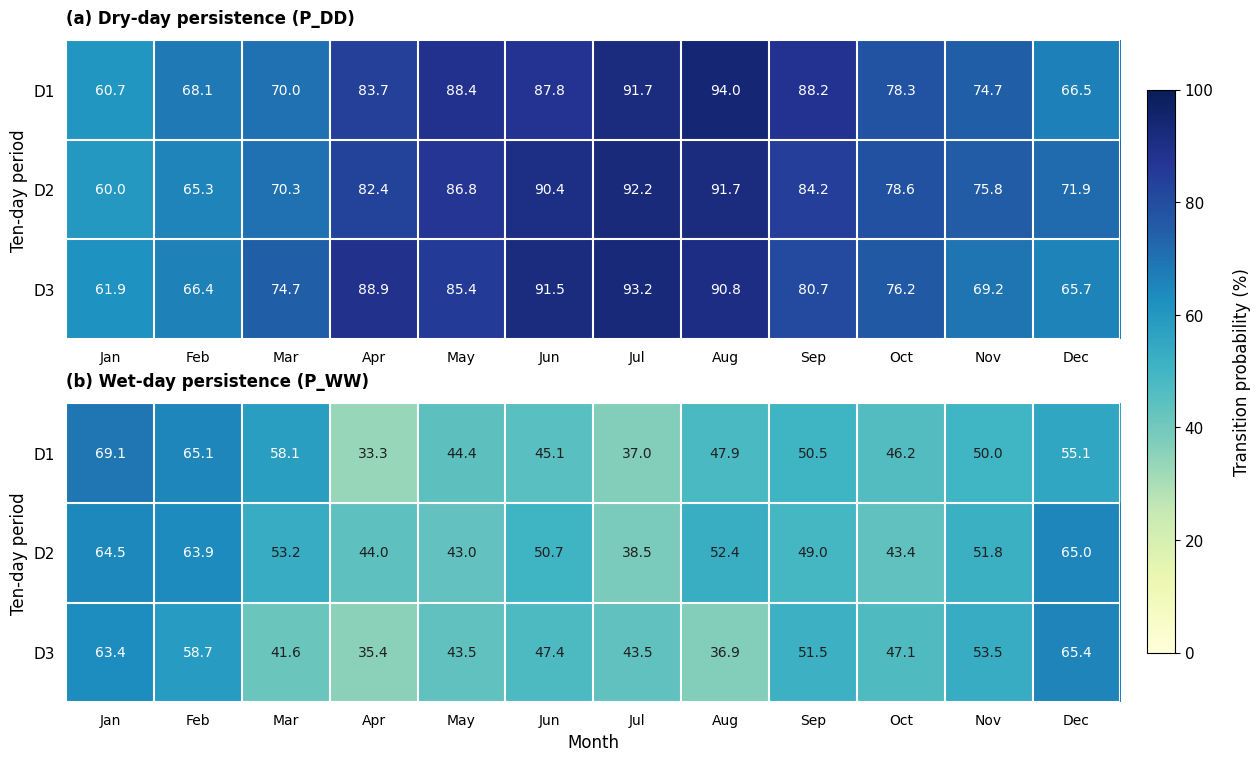

FIGURE 7 - TEN-DAY MARKOV PERSISTENCE
BOTUCATU, BRAZIL | 1971-2024
Complete ten-day periods: 1935
Within-period daily transitions: 17696
Historical ten-day groups: 36

Maximum dry-day persistence:
94.05%

Maximum wet-day persistence:
69.09%

Output files:
Figure_7_Ten_Day_Markov_Persistence_1971_2024.png
Figure_7_Ten_Day_Markov_Persistence_1971_2024.pdf
Figure_7_Ten_Day_Markov_Persistence_1971_2024.svg


In [ ]:

# ============================================================
# STEP 19 - TEN-DAY DRY- AND WET-DAY PERSISTENCE
# Methodology section 2.6
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize the historical first-order Markov
# transition probabilities for:
#
# Panel A: P_DD - Dry-to-dry persistence.
# Panel B: P_WW - Wet-to-wet persistence.
#
# Both panels use the same color scale (0-100%).
#
# The analysis is based on:
# - 1,935 complete ten-day periods.
# - 17,696 within-period daily transitions.
# - 36 historical ten-day groups.
#
# Transition probabilities were calculated in Step 18.
# No new statistical tests are performed.
#
# Input:
# tabela_markov_decendial (Step 18)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RETRIEVE RESULTS FROM STEP 18
# ------------------------------------------------------------

markov = tabela_markov_decendial.copy()

MONTH_ORDER = list(range(1, 13))

MONTH_LABELS = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

PERIOD_ORDER = ["D1", "D2", "D3"]

# ------------------------------------------------------------
# 2. VERIFY INPUT DATA
# ------------------------------------------------------------

assert len(markov) == 36

assert not markov.duplicated(
    ["Month", "Ten_day"]
).any()

assert set(markov["Month"]) == set(MONTH_ORDER)

assert set(markov["Ten_day"]) == set(PERIOD_ORDER)

assert markov["Complete_periods"].sum() == 1935

assert markov["Total_transitions"].sum() == 17696

# Verify all transition probabilities.
for column in ["P_DD", "P_DW", "P_WD", "P_WW"]:

    assert markov[column].notna().all()

    assert markov[column].between(0, 1).all()

# Verify the Markov probability identities.
assert np.allclose(
    markov["P_DD"] + markov["P_DW"],
    1.0
)

assert np.allclose(
    markov["P_WD"] + markov["P_WW"],
    1.0
)

# ------------------------------------------------------------
# 3. ORGANIZE THE TRANSITION PROBABILITY MATRICES
# ------------------------------------------------------------

# Rows represent ten-day periods.
# Columns represent calendar months.
#
# Probabilities are multiplied by 100 only
# for graphical presentation as percentages.

pdd_matrix = (
    markov
    .pivot(
        index="Ten_day",
        columns="Month",
        values="P_DD"
    )
    .reindex(
        index=PERIOD_ORDER,
        columns=MONTH_ORDER
    )
    .to_numpy(dtype=float)
) * 100

pww_matrix = (
    markov
    .pivot(
        index="Ten_day",
        columns="Month",
        values="P_WW"
    )
    .reindex(
        index=PERIOD_ORDER,
        columns=MONTH_ORDER
    )
    .to_numpy(dtype=float)
) * 100

assert pdd_matrix.shape == (3, 12)
assert pww_matrix.shape == (3, 12)

assert np.isfinite(pdd_matrix).all()
assert np.isfinite(pww_matrix).all()

# ------------------------------------------------------------
# 4. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12.5, 7.5),
    constrained_layout=True
)

# ------------------------------------------------------------
# 5. DEFINE PANEL CONFIGURATION
# ------------------------------------------------------------

panels = [
    {
        "matrix": pdd_matrix,
        "title": "(a) Dry-day persistence (P_DD)"
    },
    {
        "matrix": pww_matrix,
        "title": "(b) Wet-day persistence (P_WW)"
    }
]

# ------------------------------------------------------------
# 6. GENERATE THE TWO HEATMAP PANELS
# ------------------------------------------------------------

for ax, panel in zip(axes, panels):

    matrix = panel["matrix"]

    heatmap = ax.imshow(
        matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        aspect="auto",
        interpolation="nearest"
    )

    # Panel title.
    ax.set_title(
        panel["title"],
        loc="left",
        fontweight="bold",
        pad=12
    )

    # Calendar months.
    ax.set_xticks(np.arange(12))

    ax.set_xticklabels(
        MONTH_LABELS
    )

    # Ten-day periods.
    ax.set_yticks(np.arange(3))

    ax.set_yticklabels(
        PERIOD_ORDER
    )

    ax.set_ylabel(
        "Ten-day period"
    )

    # --------------------------------------------------------
    # 7. ADD PROBABILITY LABELS TO EACH CELL
    # --------------------------------------------------------

    for i in range(3):

        for j in range(12):

            value = matrix[i, j]

            # Improve text contrast.
            text_color = (
                "white"
                if value >= 55
                else "#202020"
            )

            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=10,
                color=text_color
            )

    # --------------------------------------------------------
    # 8. FORMAT CELL BOUNDARIES
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, 12, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 3, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.5
    )

    ax.tick_params(
        axis="both",
        which="both",
        length=0,
        pad=8
    )

    # Remove external spines.
    for spine in ax.spines.values():

        spine.set_visible(False)

# ------------------------------------------------------------
# 9. ADD SHARED COLOR BAR
# ------------------------------------------------------------

colorbar = fig.colorbar(
    heatmap,
    ax=axes,
    shrink=0.85,
    pad=0.025,
    ticks=np.arange(0, 101, 20)
)

colorbar.set_label(
    "Transition probability (%)",
    rotation=90,
    labelpad=14
)

axes[-1].set_xlabel("Month")

# ------------------------------------------------------------
# 10. EXPORT FIGURE 7
# ------------------------------------------------------------

figure_name = (
    "Figure_7_Ten_Day_Markov_"
    "Persistence_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 11. REPORT RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("FIGURE 7 - TEN-DAY MARKOV PERSISTENCE")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete ten-day periods: 1935")
print("Within-period daily transitions: 17696")
print("Historical ten-day groups: 36")

print("\nMaximum dry-day persistence:")
print(
    f"{np.max(pdd_matrix):.2f}%"
)

print("\nMaximum wet-day persistence:")
print(
    f"{np.max(pww_matrix):.2f}%"
)

print("\nOutput files:")
print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")


In [ ]:

# ============================================================
# STEP 20 - BOOTSTRAP CONFIDENCE INTERVALS FOR DRY WINDOWS
# Methodology section 2.6
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Estimate 95% confidence intervals for empirical
#    dry-weather window occurrence probabilities.
# 2. Evaluate minimum durations of 3, 5, and 7 days.
# 3. Perform the analysis at monthly and ten-day scales.
#
# Statistical method:
# Nonparametric bootstrap with replacement.
# Resampling unit: calendar year.
# Number of bootstrap replicates: 2,000.
# Confidence interval: 2.5th and 97.5th percentiles.
#
# Complete observation periods are used exclusively.
# Missing precipitation observations are not imputed.
#
# Input data:
# janelas_mensais (Step 14)
# janelas_decendiais (Step 15)
#
# This step quantifies uncertainty in previously
# calculated empirical occurrence probabilities.
# No new hypothesis tests are performed.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. CONFIGURE BOOTSTRAP PARAMETERS
# ------------------------------------------------------------

N_BOOTSTRAP = 2000
CONFIDENCE_LEVEL = 0.95
RANDOM_SEED = 20261110

WINDOW_THRESHOLDS = [3, 5, 7]

rng = np.random.default_rng(RANDOM_SEED)

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 2. RETRIEVE EMPIRICAL DRY-WINDOW INDICATORS
# ------------------------------------------------------------

monthly_data = janelas_mensais.copy()
tenday_data = janelas_decendiais.copy()

assert len(monthly_data) == 641
assert len(tenday_data) == 1935

assert monthly_data["Year"].nunique() == 54
assert tenday_data["Year"].nunique() == 54

assert not monthly_data.duplicated(
    ["Year", "Month"]
).any()

assert not tenday_data.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

indicator_columns = [
    f"Has_episode_ge{k}"
    for k in WINDOW_THRESHOLDS
]

for dataset in [monthly_data, tenday_data]:

    assert dataset[
        indicator_columns
    ].notna().all().all()

    for column in indicator_columns:

        assert dataset[column].isin([0, 1]).all()

# ------------------------------------------------------------
# 3. DEFINE THE YEAR-BASED BOOTSTRAP PROCEDURE
# ------------------------------------------------------------

def bootstrap_dry_window_probabilities(
    data,
    group_columns,
    temporal_scale
):

    """
    Estimate empirical occurrence probabilities
    and their 95% percentile bootstrap intervals.

    Each row corresponds to one valid calendar year
    within a specific calendar period.

    Years are sampled with replacement.

    The same bootstrap year indices are applied
    to all three dry-window duration indicators
    within the same period, preserving their
    within-period dependence.

    Returns one record for each combination of
    period and minimum dry-window duration.
    """

    records = []

    for _, group in data.groupby(
        group_columns,
        sort=True
    ):

        group = (
            group
            .sort_values("Year")
            .reset_index(drop=True)
        )

        years = group[
            "Year"
        ].to_numpy(dtype=int)

        n_valid_years = len(years)

        assert n_valid_years > 1
        assert len(np.unique(years)) == n_valid_years

        # Each column is a binary occurrence indicator.
        outcomes = group[
            indicator_columns
        ].to_numpy(dtype=np.int8)

        # Draw calendar-year indices with replacement.
        #
        # Dimensions:
        # (number of bootstrap samples, valid years)
        sampled_indices = rng.integers(
            low=0,
            high=n_valid_years,
            size=(N_BOOTSTRAP, n_valid_years)
        )

        # Recalculate occurrence probabilities for
        # every bootstrap sample and duration.
        #
        # Output dimensions:
        # (number of bootstrap samples, 3 durations)
        bootstrap_probabilities = (
            outcomes[sampled_indices]
            .mean(axis=1)
            * 100.0
        )

        # Original empirical probabilities.
        original_probabilities = (
            outcomes.mean(axis=0)
            * 100.0
        )

        # Percentile confidence intervals.
        confidence_limits = np.percentile(
            bootstrap_probabilities,
            [2.5, 97.5],
            axis=0
        )

        for index, k in enumerate(
            WINDOW_THRESHOLDS
        ):

            probability = float(
                original_probabilities[index]
            )

            lower = float(
                confidence_limits[0, index]
            )

            upper = float(
                confidence_limits[1, index]
            )

            # A percentile bootstrap interval may
            # collapse when all historical outcomes
            # are identical (e.g., 100% occurrence).
            degenerate = bool(
                np.isclose(lower, upper)
            )

            record = {
                "Temporal_scale": temporal_scale,
                "Month": int(group["Month"].iloc[0]),
                "Month_name": MONTH_NAMES[
                    int(group["Month"].iloc[0])
                ],
                "Minimum_duration_days": k,
                "Valid_years": n_valid_years,
                "Probability_percent": probability,
                "CI_95_lower_percent": lower,
                "CI_95_upper_percent": upper,
                "Degenerate_CI": degenerate,
                "Bootstrap_replicates": N_BOOTSTRAP
            }

            if "Ten_day" in group_columns:

                record["Ten_day"] = str(
                    group["Ten_day"].iloc[0]
                )

            records.append(record)

    return pd.DataFrame(records)

# ------------------------------------------------------------
# 4. BOOTSTRAP MONTHLY DRY-WINDOW PROBABILITIES
# ------------------------------------------------------------

bootstrap_janelas_mensais = (
    bootstrap_dry_window_probabilities(
        data=monthly_data,
        group_columns=["Month"],
        temporal_scale="Monthly"
    )
)

# Expected:
# 12 calendar months x 3 minimum durations = 36 rows.
assert len(bootstrap_janelas_mensais) == 36

# ------------------------------------------------------------
# 5. BOOTSTRAP TEN-DAY DRY-WINDOW PROBABILITIES
# ------------------------------------------------------------

bootstrap_janelas_decendiais = (
    bootstrap_dry_window_probabilities(
        data=tenday_data,
        group_columns=["Month", "Ten_day"],
        temporal_scale="Ten-day"
    )
)

# Expected:
# 12 months x 3 periods x 3 durations = 108 rows.
assert len(bootstrap_janelas_decendiais) == 108

# ------------------------------------------------------------
# 6. VERIFY CONFIDENCE INTERVALS
# ------------------------------------------------------------

for result in [
    bootstrap_janelas_mensais,
    bootstrap_janelas_decendiais
]:

    assert result[
        [
            "Probability_percent",
            "CI_95_lower_percent",
            "CI_95_upper_percent"
        ]
    ].notna().all().all()

    assert result[
        "Probability_percent"
    ].between(0, 100).all()

    assert result[
        "CI_95_lower_percent"
    ].between(0, 100).all()

    assert result[
        "CI_95_upper_percent"
    ].between(0, 100).all()

    assert (
        result["CI_95_lower_percent"]
        <= result["CI_95_upper_percent"]
    ).all()

    assert (
        result["Bootstrap_replicates"]
        == N_BOOTSTRAP
    ).all()

# ------------------------------------------------------------
# 7. VERIFY ORIGINAL PROBABILITIES AGAINST STEPS 14 AND 15
# ------------------------------------------------------------

# The bootstrap procedure must reproduce the original
# empirical probabilities before resampling.

monthly_reference = resumo_janelas_mensais[
    [
        "Month",
        "Minimum_duration_days",
        "Frequency_percent"
    ]
].copy()

monthly_check = bootstrap_janelas_mensais.merge(
    monthly_reference,
    on=["Month", "Minimum_duration_days"],
    validate="one_to_one"
)

assert len(monthly_check) == 36

assert np.allclose(
    monthly_check["Probability_percent"],
    monthly_check["Frequency_percent"]
)

tenday_reference = resumo_janelas_decendiais[
    [
        "Month",
        "Ten_day",
        "Minimum_duration_days",
        "Frequency_percent"
    ]
].copy()

tenday_check = bootstrap_janelas_decendiais.merge(
    tenday_reference,
    on=[
        "Month",
        "Ten_day",
        "Minimum_duration_days"
    ],
    validate="one_to_one"
)

assert len(tenday_check) == 108

assert np.allclose(
    tenday_check["Probability_percent"],
    tenday_check["Frequency_percent"]
)

# ------------------------------------------------------------
# 8. ORGANIZE THE FINAL RESULT TABLES
# ------------------------------------------------------------

bootstrap_janelas_mensais = (
    bootstrap_janelas_mensais
    .sort_values(
        ["Month", "Minimum_duration_days"]
    )
    .reset_index(drop=True)
)

bootstrap_janelas_decendiais["Ten_day"] = (
    pd.Categorical(
        bootstrap_janelas_decendiais["Ten_day"],
        categories=["D1", "D2", "D3"],
        ordered=True
    )
)

bootstrap_janelas_decendiais = (
    bootstrap_janelas_decendiais
    .sort_values(
        ["Month", "Ten_day", "Minimum_duration_days"]
    )
    .reset_index(drop=True)
)

bootstrap_janelas_decendiais["Ten_day"] = (
    bootstrap_janelas_decendiais["Ten_day"]
    .astype(str)
)

# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("BOOTSTRAP CONFIDENCE INTERVALS FOR DRY-WEATHER WINDOWS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Bootstrap replicates:", N_BOOTSTRAP)
print("Confidence level: 95%")
print("Resampling unit: calendar year")
print("Random seed:", RANDOM_SEED)

print("\nMONTHLY RESULTS:")

display(
    bootstrap_janelas_mensais.round(2)
)

print("\nTEN-DAY RESULTS:")

display(
    bootstrap_janelas_decendiais.round(2)
)

print("\nDEGENERATE CONFIDENCE INTERVALS:")

print(
    "Monthly:",
    int(
        bootstrap_janelas_mensais[
            "Degenerate_CI"
        ].sum()
    )
)

print(
    "Ten-day:",
    int(
        bootstrap_janelas_decendiais[
            "Degenerate_CI"
        ].sum()
    )
)

# ------------------------------------------------------------
# 10. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_20_Bootstrap_Dry_Weather_"
    "Windows_1971_2024.xlsx"
)

with pd.ExcelWriter(output_file) as writer:

    bootstrap_janelas_mensais.to_excel(
        writer,
        sheet_name="Monthly_Bootstrap",
        index=False
    )

    bootstrap_janelas_decendiais.to_excel(
        writer,
        sheet_name="TenDay_Bootstrap",
        index=False
    )

    pd.DataFrame({
        "Parameter": [
            "Study start year",
            "Study end year",
            "Bootstrap replicates",
            "Confidence level",
            "Random seed",
            "Resampling unit",
            "Monthly complete periods",
            "Ten-day complete periods"
        ],
        "Value": [
            1971,
            2024,
            N_BOOTSTRAP,
            CONFIDENCE_LEVEL,
            RANDOM_SEED,
            "Calendar year",
            641,
            1935
        ]
    }).to_excel(
        writer,
        sheet_name="Methodology",
        index=False
    )

# ------------------------------------------------------------
# 11. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 20 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)

files.download(output_file)


BOOTSTRAP CONFIDENCE INTERVALS FOR DRY-WEATHER WINDOWS
BOTUCATU, BRAZIL | 1971-2024
Bootstrap replicates: 2000
Confidence level: 95%
Resampling unit: calendar year
Random seed: 20261110

MONTHLY RESULTS:


,Temporal_scale,Month,Month_name,Minimum_duration_days,Valid_years,Probability_percent,CI_95_lower_percent,CI_95_upper_percent,Degenerate_CI,Bootstrap_replicates
0,Monthly,1,January,3,53,96.23,90.57,100.00,False,2000
1,Monthly,1,January,5,53,64.15,50.94,75.47,False,2000
2,Monthly,1,January,7,53,20.75,11.32,32.08,False,2000
3,Monthly,2,February,3,54,90.74,83.33,98.15,False,2000
4,Monthly,2,February,5,54,68.52,55.56,81.48,False,2000
5,Monthly,2,February,7,54,37.04,24.07,50.00,False,2000
6,Monthly,3,March,3,53,100.00,100.00,100.00,True,2000
7,Monthly,3,March,5,53,88.68,79.25,96.23,False,2000
8,Monthly,3,March,7,53,54.72,41.51,67.92,False,2000
9,Monthly,4,April,3,54,100.00,100.00,100.00,True,2000



TEN-DAY RESULTS:


,Temporal_scale,Month,Month_name,Minimum_duration_days,Valid_years,Probability_percent,CI_95_lower_percent,CI_95_upper_percent,Degenerate_CI,Bootstrap_replicates,Ten_day
0,Ten-day,1,January,3,54,51.85,38.89,64.81,False,2000,D1
1,Ten-day,1,January,5,54,22.22,12.96,33.33,False,2000,D1
2,Ten-day,1,January,7,54,1.85,0.00,5.56,False,2000,D1
3,Ten-day,1,January,3,54,59.26,46.30,72.22,False,2000,D2
4,Ten-day,1,January,5,54,25.93,14.81,37.04,False,2000,D2
...,...,...,...,...,...,...,...,...,...,...,...
103,Ten-day,12,December,5,54,38.89,25.93,51.85,False,2000,D2
104,Ten-day,12,December,7,54,9.26,1.85,18.52,False,2000,D2
105,Ten-day,12,December,3,54,72.22,59.26,83.33,False,2000,D3
106,Ten-day,12,December,5,54,29.63,18.52,42.59,False,2000,D3



DEGENERATE CONFIDENCE INTERVALS:
Monthly: 15
Ten-day: 2

STEP 20 COMPLETED SUCCESSFULLY
Output file: Step_20_Bootstrap_Dry_Weather_Windows_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 21 - BOOTSTRAP CONFIDENCE INTERVALS FOR MARKOV CHAINS
# Methodology: Statistical analysis
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Calculate 95% bootstrap confidence intervals for
#    monthly Markov transition probabilities.
# 2. Calculate 95% bootstrap confidence intervals for
#    ten-day Markov transition probabilities.
# 3. Use calendar years as the resampling unit.
#
# Bootstrap method:
# - Nonparametric bootstrap with replacement.
# - 2,000 resamples per historical period.
# - Percentile confidence intervals (2.5%, 97.5%).
#
# Markov probabilities:
# P_DD = Dry-to-dry transition
# P_DW = Dry-to-wet transition
# P_WD = Wet-to-dry transition
# P_WW = Wet-to-wet transition
#
# Probabilities are estimated from pooled transition
# counts rather than averaged annual probabilities.
#
# Input data:
# transicoes_markov_mensal (Step 17)
# tabela_markov_mensal (Step 17)
# transicoes_markov_decendial (Step 18)
# tabela_markov_decendial (Step 18)
#
# Missing daily observations are not imputed.
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

N_BOOTSTRAP = 2000
CONFIDENCE_LEVEL = 0.95
RANDOM_SEED = 20261110

rng = np.random.default_rng(RANDOM_SEED)

COUNT_COLUMNS = [
    "N_DD", "N_DW", "N_WD", "N_WW"
]

PROBABILITY_COLUMNS = [
    "P_DD", "P_DW", "P_WD", "P_WW"
]

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 2. LOAD PREVIOUSLY CALCULATED MARKOV RESULTS
# ------------------------------------------------------------

monthly_counts = transicoes_markov_mensal.copy()
tenday_counts = transicoes_markov_decendial.copy()

monthly_reference = tabela_markov_mensal.copy()
tenday_reference = tabela_markov_decendial.copy()

assert len(monthly_counts) == 641
assert len(tenday_counts) == 1935

assert len(monthly_reference) == 12
assert len(tenday_reference) == 36

assert monthly_counts["Year"].nunique() == 54
assert tenday_counts["Year"].nunique() == 54

assert not monthly_counts.duplicated(
    ["Year", "Month"]
).any()

assert not tenday_counts.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

for dataset in [monthly_counts, tenday_counts]:

    assert dataset[COUNT_COLUMNS].notna().all().all()

    assert (dataset[COUNT_COLUMNS] >= 0).all().all()

    assert (
        dataset[COUNT_COLUMNS].sum(axis=1)
        == dataset["Transitions"]
    ).all()

# ------------------------------------------------------------
# 3. DEFINE THE MARKOV PROBABILITY FUNCTION
# ------------------------------------------------------------

def markov_probabilities_from_counts(counts):

    """
    Calculate first-order Markov transition
    probabilities from four pooled transition counts.

    Input order:
    [N_DD, N_DW, N_WD, N_WW]

    Output order:
    [P_DD, P_DW, P_WD, P_WW]
    """

    counts = np.asarray(counts, dtype=float)

    N_DD, N_DW, N_WD, N_WW = counts

    total_dry = N_DD + N_DW
    total_wet = N_WD + N_WW

    if total_dry == 0 or total_wet == 0:

        raise ValueError(
            "Undefined transition probability: "
            "an initial state has no observations."
        )

    return np.array([
        N_DD / total_dry,
        N_DW / total_dry,
        N_WD / total_wet,
        N_WW / total_wet
    ])

# ------------------------------------------------------------
# 4. DEFINE THE YEAR-BASED BOOTSTRAP
# ------------------------------------------------------------

def bootstrap_markov(
    data,
    group_columns,
    temporal_scale
):

    """
    Estimate 95% percentile bootstrap confidence
    intervals for historical Markov probabilities.

    Procedure:
    1. Group records by calendar period.
    2. Resample valid calendar years with replacement.
    3. Pool transition counts within each resample.
    4. Recalculate four transition probabilities.
    5. Repeat for 2,000 bootstrap replicates.
    6. Extract the 2.5th and 97.5th percentiles.

    If a bootstrap sample has no transitions from
    a given initial state, the conditional probability
    is undefined for that sample. Such samples are
    excluded only from the corresponding interval.

    The number of valid replicates is reported.
    """

    results = []

    for _, group in data.groupby(
        group_columns,
        sort=True
    ):

        group = (
            group
            .sort_values("Year")
            .reset_index(drop=True)
        )

        years = group["Year"].to_numpy(dtype=int)

        n_years = len(years)

        assert n_years > 1
        assert len(np.unique(years)) == n_years

        counts = group[
            COUNT_COLUMNS
        ].to_numpy(dtype=np.int64)

        # Original historical probabilities.
        original_counts = counts.sum(axis=0)

        original_probabilities = (
            markov_probabilities_from_counts(
                original_counts
            )
        )

        # Resample calendar years with replacement.
        indices = rng.integers(
            low=0,
            high=n_years,
            size=(N_BOOTSTRAP, n_years)
        )

        # Pool transition counts in each replicate.
        bootstrap_counts = (
            counts[indices].sum(axis=1)
        )

        # Origin-state denominators.
        dry_denominator = (
            bootstrap_counts[:, 0]
            + bootstrap_counts[:, 1]
        )

        wet_denominator = (
            bootstrap_counts[:, 2]
            + bootstrap_counts[:, 3]
        )

        # Initialize probabilities with NaN.
        bootstrap_probs = np.full(
            (N_BOOTSTRAP, 4),
            np.nan,
            dtype=float
        )

        # Calculate probabilities for samples
        # containing valid transitions from dry days.
        valid_dry = dry_denominator > 0

        bootstrap_probs[valid_dry, 0] = (
            bootstrap_counts[valid_dry, 0]
            / dry_denominator[valid_dry]
        )

        bootstrap_probs[valid_dry, 1] = (
            bootstrap_counts[valid_dry, 1]
            / dry_denominator[valid_dry]
        )

        # Calculate probabilities for samples
        # containing valid transitions from wet days.
        valid_wet = wet_denominator > 0

        bootstrap_probs[valid_wet, 2] = (
            bootstrap_counts[valid_wet, 2]
            / wet_denominator[valid_wet]
        )

        bootstrap_probs[valid_wet, 3] = (
            bootstrap_counts[valid_wet, 3]
            / wet_denominator[valid_wet]
        )

        # Verify probability identities.
        assert np.allclose(
            bootstrap_probs[valid_dry, 0]
            + bootstrap_probs[valid_dry, 1],
            1.0
        )

        assert np.allclose(
            bootstrap_probs[valid_wet, 2]
            + bootstrap_probs[valid_wet, 3],
            1.0
        )

        # Store each of the four transition probabilities.
        for j, transition in enumerate(
            PROBABILITY_COLUMNS
        ):

            valid_probabilities = (
                bootstrap_probs[:, j][
                    np.isfinite(bootstrap_probs[:, j])
                ]
            )

            n_valid_replicates = len(
                valid_probabilities
            )

            if n_valid_replicates == 0:

                raise ValueError(
                    "No valid bootstrap replicates "
                    f"for transition {transition}."
                )

            lower, upper = np.percentile(
                valid_probabilities,
                [2.5, 97.5]
            )

            month = int(
                group["Month"].iloc[0]
            )

            record = {
                "Temporal_scale": temporal_scale,
                "Month": month,
                "Month_name": MONTH_NAMES[month],
                "Transition": transition,
                "Valid_years": n_years,
                "Probability": float(
                    original_probabilities[j]
                ),
                "CI_95_lower": float(lower),
                "CI_95_upper": float(upper),
                "Bootstrap_replicates": N_BOOTSTRAP,
                "Valid_bootstrap_replicates": (
                    n_valid_replicates
                )
            }

            if "Ten_day" in group_columns:

                record["Ten_day"] = str(
                    group["Ten_day"].iloc[0]
                )

            results.append(record)

    return pd.DataFrame(results)

# ------------------------------------------------------------
# 5. MONTHLY MARKOV BOOTSTRAP
# ------------------------------------------------------------

bootstrap_markov_mensal = bootstrap_markov(
    data=monthly_counts,
    group_columns=["Month"],
    temporal_scale="Monthly"
)

assert len(bootstrap_markov_mensal) == 48

# ------------------------------------------------------------
# 6. TEN-DAY MARKOV BOOTSTRAP
# ------------------------------------------------------------

bootstrap_markov_decendial = bootstrap_markov(
    data=tenday_counts,
    group_columns=["Month", "Ten_day"],
    temporal_scale="Ten-day"
)

assert len(bootstrap_markov_decendial) == 144

# ------------------------------------------------------------
# 7. VALIDATE CONFIDENCE INTERVALS
# ------------------------------------------------------------

for result in [
    bootstrap_markov_mensal,
    bootstrap_markov_decendial
]:

    assert result[
        [
            "Probability",
            "CI_95_lower",
            "CI_95_upper"
        ]
    ].notna().all().all()

    for column in [
        "Probability",
        "CI_95_lower",
        "CI_95_upper"
    ]:

        assert result[column].between(
            0, 1
        ).all()

    assert (
        result["CI_95_lower"]
        <= result["CI_95_upper"]
    ).all()

    assert (
        result["Valid_bootstrap_replicates"]
        <= N_BOOTSTRAP
    ).all()

    assert (
        result["Valid_bootstrap_replicates"] > 0
    ).all()

# ------------------------------------------------------------
# 8. VERIFY AGAINST ORIGINAL MARKOV ESTIMATES
# ------------------------------------------------------------

monthly_reference_long = monthly_reference.melt(
    id_vars=["Month"],
    value_vars=PROBABILITY_COLUMNS,
    var_name="Transition",
    value_name="Reference_probability"
)

monthly_check = bootstrap_markov_mensal.merge(
    monthly_reference_long,
    on=["Month", "Transition"],
    validate="one_to_one"
)

assert len(monthly_check) == 48

assert np.allclose(
    monthly_check["Probability"],
    monthly_check["Reference_probability"]
)

tenday_reference_long = tenday_reference.melt(
    id_vars=["Month", "Ten_day"],
    value_vars=PROBABILITY_COLUMNS,
    var_name="Transition",
    value_name="Reference_probability"
)

tenday_check = bootstrap_markov_decendial.merge(
    tenday_reference_long,
    on=["Month", "Ten_day", "Transition"],
    validate="one_to_one"
)

assert len(tenday_check) == 144

assert np.allclose(
    tenday_check["Probability"],
    tenday_check["Reference_probability"]
)

# ------------------------------------------------------------
# 9. CONVERT PROBABILITIES TO PERCENTAGES
# ------------------------------------------------------------

for result in [
    bootstrap_markov_mensal,
    bootstrap_markov_decendial
]:

    result["Probability_percent"] = (
        result["Probability"] * 100
    )

    result["CI_95_lower_percent"] = (
        result["CI_95_lower"] * 100
    )

    result["CI_95_upper_percent"] = (
        result["CI_95_upper"] * 100
    )

# ------------------------------------------------------------
# 10. ORGANIZE RESULTS
# ------------------------------------------------------------

bootstrap_markov_mensal = (
    bootstrap_markov_mensal
    .sort_values(["Month", "Transition"])
    .reset_index(drop=True)
)

bootstrap_markov_decendial["Ten_day"] = (
    pd.Categorical(
        bootstrap_markov_decendial["Ten_day"],
        categories=["D1", "D2", "D3"],
        ordered=True
    )
)

bootstrap_markov_decendial = (
    bootstrap_markov_decendial
    .sort_values(
        ["Month", "Ten_day", "Transition"]
    )
    .reset_index(drop=True)
)

bootstrap_markov_decendial["Ten_day"] = (
    bootstrap_markov_decendial["Ten_day"]
    .astype(str)
)

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("MARKOV BOOTSTRAP CONFIDENCE INTERVALS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Bootstrap replicates:", N_BOOTSTRAP)
print("Confidence level: 95%")
print("Resampling unit: calendar year")
print("Random seed:", RANDOM_SEED)

print("\nMONTHLY RESULTS:")

display(
    bootstrap_markov_mensal[
        [
            "Month_name",
            "Transition",
            "Valid_years",
            "Probability_percent",
            "CI_95_lower_percent",
            "CI_95_upper_percent",
            "Valid_bootstrap_replicates"
        ]
    ].round(2)
)

print("\nTEN-DAY RESULTS:")

display(
    bootstrap_markov_decendial[
        [
            "Month_name",
            "Ten_day",
            "Transition",
            "Valid_years",
            "Probability_percent",
            "CI_95_lower_percent",
            "CI_95_upper_percent",
            "Valid_bootstrap_replicates"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 12. EXPORT EXCEL RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_21_Bootstrap_Markov_"
    "Transitions_1971_2024.xlsx"
)

methodology_info = pd.DataFrame({
    "Parameter": [
        "Study start year",
        "Study end year",
        "Bootstrap replicates",
        "Confidence level",
        "Random seed",
        "Resampling unit",
        "Monthly complete periods",
        "Ten-day complete periods",
        "Monthly Markov probability estimates",
        "Ten-day Markov probability estimates"
    ],
    "Value": [
        1971,
        2024,
        N_BOOTSTRAP,
        CONFIDENCE_LEVEL,
        RANDOM_SEED,
        "Calendar year",
        641,
        1935,
        48,
        144
    ]
})

with pd.ExcelWriter(output_file) as writer:

    bootstrap_markov_mensal.to_excel(
        writer,
        sheet_name="Monthly_Markov_Bootstrap",
        index=False
    )

    bootstrap_markov_decendial.to_excel(
        writer,
        sheet_name="TenDay_Markov_Bootstrap",
        index=False
    )

    methodology_info.to_excel(
        writer,
        sheet_name="Methodology",
        index=False
    )

# ------------------------------------------------------------
# 13. REPORT FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 21 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Monthly estimates:", len(bootstrap_markov_mensal))

print(
    "Ten-day estimates:",
    len(bootstrap_markov_decendial)
)

print(
    "Total estimates:",
    len(bootstrap_markov_mensal)
    + len(bootstrap_markov_decendial)
)

print("\nOutput file:", output_file)

files.download(output_file)


MARKOV BOOTSTRAP CONFIDENCE INTERVALS
BOTUCATU, BRAZIL | 1971-2024
Bootstrap replicates: 2000
Confidence level: 95%
Resampling unit: calendar year
Random seed: 20261110

MONTHLY RESULTS:


,Month_name,Transition,Valid_years,Probability_percent,CI_95_lower_percent,CI_95_upper_percent,Valid_bootstrap_replicates
0,January,P_DD,53,60.54,56.98,63.74,2000
1,January,P_DW,53,39.46,36.26,43.02,2000
2,January,P_WD,53,34.47,31.05,38.13,2000
3,January,P_WW,53,65.53,61.87,68.95,2000
4,February,P_DD,54,66.58,62.60,70.21,2000
5,February,P_DW,54,33.42,29.79,37.40,2000
6,February,P_WD,54,36.84,32.77,41.11,2000
7,February,P_WW,54,63.16,58.89,67.23,2000
8,March,P_DD,53,71.46,68.74,74.03,2000
9,March,P_DW,53,28.54,25.97,31.26,2000



TEN-DAY RESULTS:


,Month_name,Ten_day,Transition,Valid_years,Probability_percent,CI_95_lower_percent,CI_95_upper_percent,Valid_bootstrap_replicates
0,January,D1,P_DD,54,60.66,53.70,66.39,2000
1,January,D1,P_DW,54,39.34,33.61,46.30,2000
2,January,D1,P_WD,54,30.91,25.59,37.08,2000
3,January,D1,P_WW,54,69.09,62.92,74.41,2000
4,January,D2,P_DD,54,60.00,52.73,66.29,2000
...,...,...,...,...,...,...,...,...
139,December,D2,P_WW,54,65.02,57.57,71.56,2000
140,December,D3,P_DD,54,65.67,59.76,70.88,2000
141,December,D3,P_DW,54,34.33,29.12,40.24,2000
142,December,D3,P_WD,54,34.56,30.06,39.70,2000



STEP 21 COMPLETED SUCCESSFULLY
Monthly estimates: 48
Ten-day estimates: 144
Total estimates: 192

Output file: Step_21_Bootstrap_Markov_Transitions_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 22 - HISTORICAL SUBPERIOD COMPARISON
# Methodology: Statistical analysis and agricultural
# interpretation
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Compare historical dry-weather window frequencies
#    between two equal-length subperiods.
# 2. Compare the mean number of distinct dry episodes.
# 3. Evaluate minimum dry-period durations of 3, 5,
#    and 7 consecutive days.
# 4. Perform monthly and ten-day comparisons.
#
# Subperiods:
# First:  1971-1997 (27 calendar years)
# Second: 1998-2024 (27 calendar years)
#
# Only complete calendar periods are considered.
# Missing observations are not imputed.
#
# Differences are interpreted descriptively.
# No additional statistical hypothesis tests are used.
#
# Inputs:
# janelas_mensais (Step 14)
# janelas_decendiais (Step 15)
# ============================================================

import numpy as np
import pandas as pd
from google.colab import files

# ------------------------------------------------------------
# 1. DEFINE HISTORICAL SUBPERIODS
# ------------------------------------------------------------

FIRST_PERIOD = "1971-1997"
SECOND_PERIOD = "1998-2024"

WINDOW_THRESHOLDS = [3, 5, 7]

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 2. RETRIEVE PREVIOUSLY CALCULATED DATA
# ------------------------------------------------------------

monthly = janelas_mensais.copy()
tenday = janelas_decendiais.copy()

assert len(monthly) == 641
assert len(tenday) == 1935

assert monthly["Year"].nunique() == 54
assert tenday["Year"].nunique() == 54

assert not monthly.duplicated(
    ["Year", "Month"]
).any()

assert not tenday.duplicated(
    ["Year", "Month", "Ten_day"]
).any()

# ------------------------------------------------------------
# 3. IDENTIFY THE HISTORICAL SUBPERIOD
# ------------------------------------------------------------

for data in [monthly, tenday]:

    assert data["Year"].between(
        1971, 2024
    ).all()

    data["Subperiod"] = np.where(
        data["Year"] <= 1997,
        FIRST_PERIOD,
        SECOND_PERIOD
    )

    # Verify that occurrence indicators are binary.
    for k in WINDOW_THRESHOLDS:

        assert data[
            f"Has_episode_ge{k}"
        ].isin([0, 1]).all()

        assert (
            data[f"Episodes_ge{k}"] >= 0
        ).all()

        assert (
            data[f"Has_episode_ge{k}"]
            ==
            (data[f"Episodes_ge{k}"] > 0).astype(int)
        ).all()

# ------------------------------------------------------------
# 4. VERIFY SUBPERIOD DATA COVERAGE
# ------------------------------------------------------------

monthly_counts = (
    monthly["Subperiod"]
    .value_counts()
    .to_dict()
)

tenday_counts = (
    tenday["Subperiod"]
    .value_counts()
    .to_dict()
)

# The differences in valid period counts arise
# from missing daily observations.

assert monthly_counts == {
    FIRST_PERIOD: 323,
    SECOND_PERIOD: 318
}

assert tenday_counts == {
    FIRST_PERIOD: 971,
    SECOND_PERIOD: 964
}

# ------------------------------------------------------------
# 5. DEFINE THE SUBPERIOD SUMMARY FUNCTION
# ------------------------------------------------------------

def calculate_subperiod_statistics(
    data,
    group_columns,
    temporal_scale
):

    """
    Calculate historical occurrence frequencies
    and mean numbers of distinct dry episodes
    for each historical subperiod.

    Occurrence frequency (%):
    100 * (periods with at least one qualifying
    episode / number of complete periods).

    Mean episode count:
    Total distinct qualifying episodes divided
    by the number of complete periods.

    Each uninterrupted dry sequence is counted
    only once for each applicable duration threshold.
    """

    records = []

    grouping = (
        ["Subperiod"] + group_columns
    )

    for _, group in data.groupby(
        grouping,
        sort=True
    ):

        subperiod = str(
            group["Subperiod"].iloc[0]
        )

        month = int(
            group["Month"].iloc[0]
        )

        n_periods = len(group)

        n_valid_years = (
            group["Year"].nunique()
        )

        # Each calendar group has a maximum
        # of one observation per year.
        assert n_periods == n_valid_years

        assert n_periods > 0

        for k in WINDOW_THRESHOLDS:

            occurrence_column = (
                f"Has_episode_ge{k}"
            )

            episode_column = (
                f"Episodes_ge{k}"
            )

            periods_with_episode = int(
                group[occurrence_column].sum()
            )

            total_episodes = int(
                group[episode_column].sum()
            )

            frequency = (
                periods_with_episode
                / n_periods
                * 100
            )

            mean_episodes = (
                total_episodes
                / n_periods
            )

            record = {
                "Temporal_scale": temporal_scale,
                "Subperiod": subperiod,
                "Month": month,
                "Month_name": MONTH_NAMES[month],
                "Minimum_duration_days": k,
                "Valid_years": n_valid_years,
                "Complete_periods": n_periods,
                "Periods_with_episode": (
                    periods_with_episode
                ),
                "Frequency_percent": frequency,
                "Total_episodes": total_episodes,
                "Mean_episodes_per_period": (
                    mean_episodes
                )
            }

            if "Ten_day" in group_columns:

                record["Ten_day"] = str(
                    group["Ten_day"].iloc[0]
                )

            records.append(record)

    return pd.DataFrame(records)

# ------------------------------------------------------------
# 6. CALCULATE MONTHLY SUBPERIOD STATISTICS
# ------------------------------------------------------------

subperiodos_mensais = (
    calculate_subperiod_statistics(
        monthly,
        group_columns=["Month"],
        temporal_scale="Monthly"
    )
)

# 12 months x 3 durations x 2 subperiods.
assert len(subperiodos_mensais) == 72

# ------------------------------------------------------------
# 7. CALCULATE TEN-DAY SUBPERIOD STATISTICS
# ------------------------------------------------------------

subperiodos_decendiais = (
    calculate_subperiod_statistics(
        tenday,
        group_columns=["Month", "Ten_day"],
        temporal_scale="Ten-day"
    )
)

# 36 ten-day groups x 3 durations x 2 subperiods.
assert len(subperiodos_decendiais) == 216

# ------------------------------------------------------------
# 8. DEFINE THE COMPARISON FUNCTION
# ------------------------------------------------------------

def compare_historical_subperiods(
    summary,
    group_columns
):

    """
    Compare the earlier and later historical subperiods.

    Differences are calculated as:
    Later subperiod - Earlier subperiod.

    Frequency differences are expressed in
    percentage points (pp).

    Mean episode differences are expressed
    as episodes per calendar period.

    No significance testing is performed.
    """

    keys = (
        group_columns
        + ["Minimum_duration_days"]
    )

    values = [
        "Valid_years",
        "Complete_periods",
        "Periods_with_episode",
        "Frequency_percent",
        "Total_episodes",
        "Mean_episodes_per_period"
    ]

    earlier = summary.loc[
        summary["Subperiod"] == FIRST_PERIOD,
        keys + values
    ].copy()

    later = summary.loc[
        summary["Subperiod"] == SECOND_PERIOD,
        keys + values
    ].copy()

    earlier = earlier.rename(
        columns={
            col: f"{col}_1971_1997"
            for col in values
        }
    )

    later = later.rename(
        columns={
            col: f"{col}_1998_2024"
            for col in values
        }
    )

    comparison = earlier.merge(
        later,
        on=keys,
        how="inner",
        validate="one_to_one"
    )

    comparison["Frequency_change_pp"] = (
        comparison["Frequency_percent_1998_2024"]
        - comparison["Frequency_percent_1971_1997"]
    )

    comparison["Mean_episodes_change"] = (
        comparison["Mean_episodes_per_period_1998_2024"]
        - comparison["Mean_episodes_per_period_1971_1997"]
    )

    return comparison

# ------------------------------------------------------------
# 9. COMPARE MONTHLY HISTORICAL SUBPERIODS
# ------------------------------------------------------------

comparacao_mensal = (
    compare_historical_subperiods(
        subperiodos_mensais,
        group_columns=["Month", "Month_name"]
    )
)

assert len(comparacao_mensal) == 36

# ------------------------------------------------------------
# 10. COMPARE TEN-DAY HISTORICAL SUBPERIODS
# ------------------------------------------------------------

comparacao_decendial = (
    compare_historical_subperiods(
        subperiodos_decendiais,
        group_columns=[
            "Month",
            "Month_name",
            "Ten_day"
        ]
    )
)

assert len(comparacao_decendial) == 108

# ------------------------------------------------------------
# 11. VERIFY THE HISTORICAL PROBABILITIES
# ------------------------------------------------------------

# Pooling the two subperiod counts must reproduce
# the complete-period empirical probabilities
# calculated in Steps 14 and 15.

def verify_against_original(
    comparison,
    reference,
    group_columns
):

    keys = (
        group_columns
        + ["Minimum_duration_days"]
    )

    merged = comparison.merge(
        reference[
            keys
            + [
                "Frequency_percent",
                "Total_episodes"
            ]
        ],
        on=keys,
        how="inner",
        validate="one_to_one"
    )

    assert len(merged) == len(comparison)

    total_periods = (
        merged["Complete_periods_1971_1997"]
        + merged["Complete_periods_1998_2024"]
    )

    total_occurrences = (
        merged["Periods_with_episode_1971_1997"]
        + merged["Periods_with_episode_1998_2024"]
    )

    combined_frequency = (
        total_occurrences / total_periods * 100
    )

    combined_episodes = (
        merged["Total_episodes_1971_1997"]
        + merged["Total_episodes_1998_2024"]
    )

    assert np.allclose(
        combined_frequency,
        merged["Frequency_percent"]
    )

    assert np.array_equal(
        combined_episodes.to_numpy(),
        merged["Total_episodes"].to_numpy()
    )

verify_against_original(
    comparacao_mensal,
    resumo_janelas_mensais,
    ["Month"]
)

verify_against_original(
    comparacao_decendial,
    resumo_janelas_decendiais,
    ["Month", "Ten_day"]
)

# ------------------------------------------------------------
# 12. VERIFY THE COMPARISON RESULTS
# ------------------------------------------------------------

for result in [
    comparacao_mensal,
    comparacao_decendial
]:

    assert result[
        [
            "Frequency_percent_1971_1997",
            "Frequency_percent_1998_2024"
        ]
    ].notna().all().all()

    assert result[
        "Frequency_percent_1971_1997"
    ].between(0, 100).all()

    assert result[
        "Frequency_percent_1998_2024"
    ].between(0, 100).all()

    assert result[
        "Frequency_change_pp"
    ].between(-100, 100).all()

# ------------------------------------------------------------
# 13. DISPLAY COVERAGE INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("HISTORICAL SUBPERIOD COMPARISON")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("First subperiod: 1971-1997 (27 years)")
print("Second subperiod: 1998-2024 (27 years)")

print("\nCOMPLETE MONTHS:")
print(monthly["Subperiod"].value_counts())

print("\nCOMPLETE TEN-DAY PERIODS:")
print(tenday["Subperiod"].value_counts())

# ------------------------------------------------------------
# 14. DISPLAY MONTHLY RESULTS
# ------------------------------------------------------------

print("\nMONTHLY SUBPERIOD COMPARISON:")

display(
    comparacao_mensal.round(2)
)

print("\nMONTHLY COMPARISON FOR >= 7 DRY DAYS:")

display(
    comparacao_mensal.loc[
        comparacao_mensal[
            "Minimum_duration_days"
        ] == 7,
        [
            "Month_name",
            "Valid_years_1971_1997",
            "Valid_years_1998_2024",
            "Frequency_percent_1971_1997",
            "Frequency_percent_1998_2024",
            "Frequency_change_pp",
            "Mean_episodes_per_period_1971_1997",
            "Mean_episodes_per_period_1998_2024",
            "Mean_episodes_change"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 15. DISPLAY TEN-DAY RESULTS
# ------------------------------------------------------------

print("\nTEN-DAY SUBPERIOD COMPARISON:")

display(
    comparacao_decendial.round(2)
)

# ------------------------------------------------------------
# 16. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_22_Historical_Subperiod_"
    "Dry_Weather_Windows_1971_2024.xlsx"
)

methodology_info = pd.DataFrame({
    "Parameter": [
        "Study start year",
        "Study end year",
        "First historical subperiod",
        "Second historical subperiod",
        "Years in each subperiod",
        "Minimum dry-window durations",
        "Monthly complete periods",
        "Ten-day complete periods",
        "Comparison approach",
        "Direction of difference"
    ],
    "Value": [
        1971,
        2024,
        FIRST_PERIOD,
        SECOND_PERIOD,
        27,
        "3, 5, and 7 days",
        641,
        1935,
        "Descriptive",
        "Later minus earlier"
    ]
})

with pd.ExcelWriter(output_file) as writer:

    subperiodos_mensais.to_excel(
        writer,
        sheet_name="Monthly_By_Subperiod",
        index=False
    )

    subperiodos_decendiais.to_excel(
        writer,
        sheet_name="TenDay_By_Subperiod",
        index=False
    )

    comparacao_mensal.to_excel(
        writer,
        sheet_name="Monthly_Comparison",
        index=False
    )

    comparacao_decendial.to_excel(
        writer,
        sheet_name="TenDay_Comparison",
        index=False
    )

    methodology_info.to_excel(
        writer,
        sheet_name="Methodology",
        index=False
    )

# ------------------------------------------------------------
# 17. REPORT OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 22 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Monthly comparison records:", 36)
print("Ten-day comparison records:", 108)

print("\nOutput file:", output_file)

files.download(output_file)


HISTORICAL SUBPERIOD COMPARISON
BOTUCATU, BRAZIL | 1971-2024
First subperiod: 1971-1997 (27 years)
Second subperiod: 1998-2024 (27 years)

COMPLETE MONTHS:
Subperiod
1971-1997    323
1998-2024    318
Name: count, dtype: int64

COMPLETE TEN-DAY PERIODS:
Subperiod
1971-1997    971
1998-2024    964
Name: count, dtype: int64

MONTHLY SUBPERIOD COMPARISON:


,Month,Month_name,Minimum_duration_days,Valid_years_1971_1997,Complete_periods_1971_1997,Periods_with_episode_1971_1997,Frequency_percent_1971_1997,Total_episodes_1971_1997,Mean_episodes_per_period_1971_1997,Valid_years_1998_2024,Complete_periods_1998_2024,Periods_with_episode_1998_2024,Frequency_percent_1998_2024,Total_episodes_1998_2024,Mean_episodes_per_period_1998_2024,Frequency_change_pp,Mean_episodes_change
0,1,January,3,27,27,26,96.30,65,2.41,26,26,25,96.15,46,1.77,-0.14,-0.64
1,1,January,5,27,27,20,74.07,25,0.93,26,26,14,53.85,18,0.69,-20.23,-0.23
2,1,January,7,27,27,7,25.93,7,0.26,26,26,4,15.38,5,0.19,-10.54,-0.07
3,2,February,3,27,27,24,88.89,55,2.04,27,27,25,92.59,62,2.30,3.70,0.26
4,2,February,5,27,27,19,70.37,25,0.93,27,27,18,66.67,28,1.04,-3.70,0.11
5,2,February,7,27,27,8,29.63,9,0.33,27,27,12,44.44,14,0.52,14.81,0.19
6,3,March,3,27,27,27,100.00,73,2.70,26,26,26,100.00,71,2.73,0.00,0.03
7,3,March,5,27,27,23,85.19,34,1.26,26,26,24,92.31,44,1.69,7.12,0.43
8,3,March,7,27,27,14,51.85,16,0.59,26,26,15,57.69,20,0.77,5.84,0.18
9,4,April,3,27,27,27,100.00,74,2.74,27,27,27,100.00,77,2.85,0.00,0.11



MONTHLY COMPARISON FOR >= 7 DRY DAYS:


,Month_name,Valid_years_1971_1997,Valid_years_1998_2024,Frequency_percent_1971_1997,Frequency_percent_1998_2024,Frequency_change_pp,Mean_episodes_per_period_1971_1997,Mean_episodes_per_period_1998_2024,Mean_episodes_change
2,January,27,26,25.93,15.38,-10.54,0.26,0.19,-0.07
5,February,27,27,29.63,44.44,14.81,0.33,0.52,0.19
8,March,27,26,51.85,57.69,5.84,0.59,0.77,0.18
11,April,27,27,81.48,85.19,3.70,1.33,1.19,-0.15
14,May,27,27,96.30,96.30,0.00,1.44,1.33,-0.11
17,June,27,27,96.30,100.00,3.70,1.15,1.33,0.19
20,July,27,26,96.30,100.00,3.70,1.48,1.65,0.17
23,August,26,26,100.00,100.00,0.00,1.54,1.38,-0.15
26,September,27,26,77.78,92.31,14.53,0.89,1.31,0.42
29,October,27,26,88.89,73.08,-15.81,1.33,0.85,-0.49



TEN-DAY SUBPERIOD COMPARISON:


,Month,Month_name,Ten_day,Minimum_duration_days,Valid_years_1971_1997,Complete_periods_1971_1997,Periods_with_episode_1971_1997,Frequency_percent_1971_1997,Total_episodes_1971_1997,Mean_episodes_per_period_1971_1997,Valid_years_1998_2024,Complete_periods_1998_2024,Periods_with_episode_1998_2024,Frequency_percent_1998_2024,Total_episodes_1998_2024,Mean_episodes_per_period_1998_2024,Frequency_change_pp,Mean_episodes_change
0,1,January,D1,3,27,27,16,59.26,18,0.67,27,27,12,44.44,13,0.48,-14.81,-0.19
1,1,January,D1,5,27,27,8,29.63,8,0.30,27,27,4,14.81,4,0.15,-14.81,-0.15
2,1,January,D1,7,27,27,0,0.00,0,0.00,27,27,1,3.70,1,0.04,3.70,0.04
3,1,January,D2,3,27,27,20,74.07,22,0.81,27,27,12,44.44,13,0.48,-29.63,-0.33
4,1,January,D2,5,27,27,8,29.63,8,0.30,27,27,6,22.22,6,0.22,-7.41,-0.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,12,December,D2,5,27,27,8,29.63,8,0.30,27,27,13,48.15,13,0.48,18.52,0.19
104,12,December,D2,7,27,27,3,11.11,3,0.11,27,27,2,7.41,2,0.07,-3.70,-0.04
105,12,December,D3,3,27,27,18,66.67,20,0.74,27,27,21,77.78,23,0.85,11.11,0.11
106,12,December,D3,5,27,27,5,18.52,5,0.19,27,27,11,40.74,11,0.41,22.22,0.22



STEP 22 COMPLETED SUCCESSFULLY
Monthly comparison records: 36
Ten-day comparison records: 108

Output file: Step_22_Historical_Subperiod_Dry_Weather_Windows_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 23 - EMPIRICAL VS. MARKOV DRY-DAY PERSISTENCE
# Methodology: Dry- and wet-day persistence
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Objectives:
# 1. Calculate empirical conditional probabilities
#    of maintaining dry conditions for 3, 5, and 7 days.
# 2. Estimate the corresponding first-order Markov
#    probabilities using P_DD^(k-1).
# 3. Compare empirical and model-derived probabilities
#    at monthly and ten-day temporal scales.
# 4. Quantify their absolute differences.
#
# Definitions:
# D = Dry day (precipitation < 1.0 mm)
# W = Wet day (precipitation >= 1.0 mm)
#
# Empirical conditional probability:
# Successful k-day dry sequences / eligible dry starts.
#
# An eligible start must:
# - Be a dry day.
# - Have at least k-1 subsequent observations
#   within the same complete calendar period.
#
# Model-derived conditional probability:
# P_Markov(k) = P_DD ** (k-1)
#
# No sequences cross month or ten-day boundaries.
# Missing observations are not imputed.
#
# This is an in-sample comparison, not an
# independent predictive validation.
#
# Inputs:
# dados_limpos (Step 01)
# mensais_validos (Step 05)
# decendiais_validos (Step 07)
# tabela_markov_mensal (Step 17)
# tabela_markov_decendial (Step 18)
# ============================================================

import numpy as np
import pandas as pd
import calendar
from google.colab import files

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DRY_THRESHOLD = 1.0
WINDOW_DURATIONS = [3, 5, 7]

MONTH_NAMES = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

# ------------------------------------------------------------
# 2. PREPARE DAILY PRECIPITATION RECORDS
# ------------------------------------------------------------

daily = dados_limpos[
    ["Data", "Precipitacao_mm"]
].copy()

daily["Data"] = pd.to_datetime(
    daily["Data"]
).dt.normalize()

daily["Year"] = daily["Data"].dt.year
daily["Month"] = daily["Data"].dt.month
daily["Day"] = daily["Data"].dt.day

daily["Ten_day"] = np.select(
    [
        daily["Day"] <= 10,
        daily["Day"].between(11, 20),
        daily["Day"] >= 21
    ],
    ["D1", "D2", "D3"],
    default="Invalid"
)

assert daily["Data"].is_unique

assert not (
    daily["Ten_day"] == "Invalid"
).any()

# ------------------------------------------------------------
# 3. SELECT COMPLETE MONTHS AND TEN-DAY PERIODS
# ------------------------------------------------------------

complete_months = (
    mensais_validos[
        ["Year", "Month"]
    ]
    .drop_duplicates()
    .copy()
)

complete_tendays = (
    decendiais_validos[
        ["Year", "Month", "Ten_day", "Expected_days"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(complete_months) == 641
assert len(complete_tendays) == 1935

monthly_daily = daily.merge(
    complete_months,
    on=["Year", "Month"],
    how="inner",
    validate="many_to_one"
)

tenday_daily = daily.merge(
    complete_tendays,
    on=["Year", "Month", "Ten_day"],
    how="inner",
    validate="many_to_one"
)

assert monthly_daily[
    "Precipitacao_mm"
].notna().all()

assert tenday_daily[
    "Precipitacao_mm"
].notna().all()

# ------------------------------------------------------------
# 4. DEFINE EMPIRICAL CONDITIONAL COUNTS
# ------------------------------------------------------------

def count_conditional_dry_sequences(precipitation, k):

    """
    Count eligible dry starting days and successful
    uninterrupted k-day dry sequences.

    The initial day must be dry.

    Only starts having at least k-1 subsequent
    observations are eligible.

    Each eligible starting position is evaluated.
    Therefore, overlapping successful starts are
    permitted in this conditional analysis.

    This differs from the distinct-episode counting
    procedure used for dry-window occurrence.
    """

    precipitation = np.asarray(
        precipitation,
        dtype=float
    )

    if not np.isfinite(precipitation).all():
        raise ValueError(
            "Missing precipitation values detected."
        )

    n = len(precipitation)

    if n < k:
        return 0, 0

    dry = (
        precipitation < DRY_THRESHOLD
    ).astype(np.int64)

    # Valid starting positions are:
    # 0, 1, ..., n-k.
    eligible_positions = dry[:n-k+1]

    eligible_starts = int(
        eligible_positions.sum()
    )

    # Count dry days inside each k-day window.
    dry_counts = np.convolve(
        dry,
        np.ones(k, dtype=np.int64),
        mode="valid"
    )

    # A successful sequence contains k dry days.
    successful_starts = int(
        np.sum(dry_counts == k)
    )

    assert successful_starts <= eligible_starts

    return eligible_starts, successful_starts

# ------------------------------------------------------------
# 5. DEFINE PERIOD-LEVEL EMPIRICAL CALCULATION
# ------------------------------------------------------------

def calculate_empirical_periods(
    data,
    grouping_columns,
    temporal_scale
):

    """
    Calculate empirical dry-sequence counts for each
    complete historical calendar period.

    Results are retained by year to allow verification
    of the pooled historical conditional probabilities.
    """

    records = []

    for _, group in data.groupby(
        grouping_columns,
        sort=True
    ):

        group = (
            group
            .sort_values("Data")
            .reset_index(drop=True)
        )

        # Verify consecutive daily observations.
        assert (
            group["Data"]
            .diff()
            .dropna()
            .dt.days
            == 1
        ).all()

        year = int(group["Year"].iloc[0])
        month = int(group["Month"].iloc[0])

        if temporal_scale == "Monthly":

            expected_days = calendar.monthrange(
                year, month
            )[1]

        else:

            expected_days = int(
                group["Expected_days"].iloc[0]
            )

        assert len(group) == expected_days

        precipitation = group[
            "Precipitacao_mm"
        ].to_numpy(dtype=float)

        for k in WINDOW_DURATIONS:

            eligible, successful = (
                count_conditional_dry_sequences(
                    precipitation, k
                )
            )

            record = {
                "Temporal_scale": temporal_scale,
                "Year": year,
                "Month": month,
                "Minimum_duration_days": k,
                "Valid_days": len(group),
                "Eligible_dry_starts": eligible,
                "Successful_dry_starts": successful
            }

            if temporal_scale == "Ten-day":

                record["Ten_day"] = str(
                    group["Ten_day"].iloc[0]
                )

            records.append(record)

    return pd.DataFrame(records)

# ------------------------------------------------------------
# 6. CALCULATE MONTHLY EMPIRICAL COUNTS
# ------------------------------------------------------------

empirico_mensal_individual = (
    calculate_empirical_periods(
        data=monthly_daily,
        grouping_columns=["Year", "Month"],
        temporal_scale="Monthly"
    )
)

assert len(empirico_mensal_individual) == 641 * 3

# ------------------------------------------------------------
# 7. CALCULATE TEN-DAY EMPIRICAL COUNTS
# ------------------------------------------------------------

empirico_decendial_individual = (
    calculate_empirical_periods(
        data=tenday_daily,
        grouping_columns=[
            "Year", "Month", "Ten_day"
        ],
        temporal_scale="Ten-day"
    )
)

assert len(empirico_decendial_individual) == 1935 * 3

# ------------------------------------------------------------
# 8. AGGREGATE EMPIRICAL CONDITIONAL PROBABILITIES
# ------------------------------------------------------------

def aggregate_empirical_probabilities(
    individual,
    grouping_columns
):

    """
    Pool eligible and successful starting-day counts
    over valid years.

    Empirical conditional probability:
    P_empirical = successful starts / eligible dry starts.

    Counts are pooled instead of averaging individual
    annual conditional probabilities.
    """

    result = (
        individual
        .groupby(
            grouping_columns
            + ["Minimum_duration_days"]
        )
        .agg(
            Complete_periods=("Year", "size"),
            Eligible_dry_starts=(
                "Eligible_dry_starts", "sum"
            ),
            Successful_dry_starts=(
                "Successful_dry_starts", "sum"
            )
        )
        .reset_index()
    )

    assert (
        result["Eligible_dry_starts"] > 0
    ).all()

    result["P_empirical"] = (
        result["Successful_dry_starts"]
        / result["Eligible_dry_starts"]
    )

    return result

empirico_mensal = (
    aggregate_empirical_probabilities(
        empirico_mensal_individual,
        ["Month"]
    )
)

empirico_decendial = (
    aggregate_empirical_probabilities(
        empirico_decendial_individual,
        ["Month", "Ten_day"]
    )
)

assert len(empirico_mensal) == 36
assert len(empirico_decendial) == 108

# ------------------------------------------------------------
# 9. RETRIEVE FIRST-ORDER MARKOV PROBABILITIES
# ------------------------------------------------------------

markov_monthly = tabela_markov_mensal[
    ["Month", "P_DD"]
].copy()

markov_tenday = tabela_markov_decendial[
    ["Month", "Ten_day", "P_DD"]
].copy()

assert len(markov_monthly) == 12
assert len(markov_tenday) == 36

assert markov_monthly[
    "P_DD"
].between(0, 1).all()

assert markov_tenday[
    "P_DD"
].between(0, 1).all()

# ------------------------------------------------------------
# 10. COMPARE EMPIRICAL AND MARKOV ESTIMATES
# ------------------------------------------------------------

def compare_empirical_markov(
    empirical,
    markov,
    grouping_columns
):

    """
    Compare observed conditional probabilities
    with first-order Markov estimates.

    Markov probability:
    P_Markov(k) = P_DD^(k-1).

    Report differences in percentage points.

    A positive signed difference indicates that
    the empirical probability exceeds the model
    estimate.
    """

    comparison = empirical.merge(
        markov,
        on=grouping_columns,
        how="left",
        validate="many_to_one"
    )

    assert comparison["P_DD"].notna().all()

    k = comparison[
        "Minimum_duration_days"
    ].to_numpy(dtype=int)

    comparison["P_Markov"] = (
        comparison["P_DD"] ** (k - 1)
    )

    comparison["P_empirical_percent"] = (
        comparison["P_empirical"] * 100
    )

    comparison["P_Markov_percent"] = (
        comparison["P_Markov"] * 100
    )

    comparison["Difference_pp"] = (
        comparison["P_empirical_percent"]
        - comparison["P_Markov_percent"]
    )

    comparison["Absolute_difference_pp"] = (
        comparison["Difference_pp"].abs()
    )

    return comparison

comparacao_markov_mensal = (
    compare_empirical_markov(
        empirico_mensal,
        markov_monthly,
        ["Month"]
    )
)

comparacao_markov_decendial = (
    compare_empirical_markov(
        empirico_decendial,
        markov_tenday,
        ["Month", "Ten_day"]
    )
)

# ------------------------------------------------------------
# 11. VALIDATE COMPARISON RESULTS
# ------------------------------------------------------------

assert len(comparacao_markov_mensal) == 36
assert len(comparacao_markov_decendial) == 108

for result in [
    comparacao_markov_mensal,
    comparacao_markov_decendial
]:

    assert result[
        ["P_empirical", "P_Markov"]
    ].notna().all().all()

    assert result[
        "P_empirical"
    ].between(0, 1).all()

    assert result[
        "P_Markov"
    ].between(0, 1).all()

    assert result[
        "Absolute_difference_pp"
    ].between(0, 100).all()

    assert (
        result["Successful_dry_starts"]
        <= result["Eligible_dry_starts"]
    ).all()

# ------------------------------------------------------------
# 12. CALCULATE MEAN ABSOLUTE DIFFERENCES
# ------------------------------------------------------------

# Mean absolute difference (MAE) is calculated
# across the 12 monthly or 36 ten-day groups,
# separately for each evaluated sequence duration.

monthly_mae = (
    comparacao_markov_mensal
    .groupby("Minimum_duration_days")
    .agg(
        Groups=("Month", "size"),
        MAE_pp=("Absolute_difference_pp", "mean")
    )
    .reset_index()
)

monthly_mae.insert(
    0,
    "Temporal_scale",
    "Monthly"
)

tenday_mae = (
    comparacao_markov_decendial
    .groupby("Minimum_duration_days")
    .agg(
        Groups=("Month", "size"),
        MAE_pp=("Absolute_difference_pp", "mean")
    )
    .reset_index()
)

tenday_mae.insert(
    0,
    "Temporal_scale",
    "Ten-day"
)

resumo_comparacao_markov = pd.concat(
    [monthly_mae, tenday_mae],
    ignore_index=True
)

assert len(resumo_comparacao_markov) == 6

assert (
    monthly_mae["Groups"] == 12
).all()

assert (
    tenday_mae["Groups"] == 36
).all()

# ------------------------------------------------------------
# 13. ADD CALENDAR MONTH NAMES
# ------------------------------------------------------------

for result in [
    comparacao_markov_mensal,
    comparacao_markov_decendial
]:

    result.insert(
        1,
        "Month_name",
        result["Month"].map(MONTH_NAMES)
    )

# ------------------------------------------------------------
# 14. ORGANIZE THE RESULTS
# ------------------------------------------------------------

comparacao_markov_mensal = (
    comparacao_markov_mensal
    .sort_values(
        ["Month", "Minimum_duration_days"]
    )
    .reset_index(drop=True)
)

comparacao_markov_decendial["Ten_day"] = (
    pd.Categorical(
        comparacao_markov_decendial["Ten_day"],
        categories=["D1", "D2", "D3"],
        ordered=True
    )
)

comparacao_markov_decendial = (
    comparacao_markov_decendial
    .sort_values(
        [
            "Month",
            "Ten_day",
            "Minimum_duration_days"
        ]
    )
    .reset_index(drop=True)
)

comparacao_markov_decendial["Ten_day"] = (
    comparacao_markov_decendial["Ten_day"]
    .astype(str)
)

# ------------------------------------------------------------
# 15. DISPLAY MONTHLY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("EMPIRICAL VS. MARKOV DRY-DAY PERSISTENCE")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete monthly periods: 641")
print("Complete ten-day periods: 1935")
print("Minimum sequence durations: 3, 5, and 7 days")

print("\nMONTHLY COMPARISON:")

display(
    comparacao_markov_mensal[
        [
            "Month_name",
            "Minimum_duration_days",
            "Complete_periods",
            "Eligible_dry_starts",
            "Successful_dry_starts",
            "P_empirical_percent",
            "P_Markov_percent",
            "Difference_pp",
            "Absolute_difference_pp"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 16. DISPLAY TEN-DAY RESULTS
# ------------------------------------------------------------

print("\nTEN-DAY COMPARISON:")

display(
    comparacao_markov_decendial[
        [
            "Month_name",
            "Ten_day",
            "Minimum_duration_days",
            "Complete_periods",
            "Eligible_dry_starts",
            "Successful_dry_starts",
            "P_empirical_percent",
            "P_Markov_percent",
            "Difference_pp",
            "Absolute_difference_pp"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 17. DISPLAY MEAN ABSOLUTE DIFFERENCES
# ------------------------------------------------------------

print("\nMEAN ABSOLUTE DIFFERENCE BY SEQUENCE DURATION:")

display(
    resumo_comparacao_markov.round(3)
)

# ------------------------------------------------------------
# 18. EXPORT RESULTS
# ------------------------------------------------------------

output_file = (
    "Step_23_Empirical_vs_Markov_"
    "Dry_Persistence_1971_2024.xlsx"
)

methodology_info = pd.DataFrame({
    "Parameter": [
        "Study start year",
        "Study end year",
        "Dry-day threshold (mm)",
        "Sequence durations (days)",
        "Empirical probability",
        "Markov probability",
        "Comparison error unit",
        "Monthly complete periods",
        "Ten-day complete periods",
        "Validation type"
    ],
    "Value": [
        1971,
        2024,
        DRY_THRESHOLD,
        "3, 5, 7",
        "Successful dry starts / eligible dry starts",
        "P_DD^(k-1)",
        "Percentage points",
        641,
        1935,
        "In-sample comparison"
    ]
})

with pd.ExcelWriter(output_file) as writer:

    comparacao_markov_mensal.to_excel(
        writer,
        sheet_name="Monthly_Comparison",
        index=False
    )

    comparacao_markov_decendial.to_excel(
        writer,
        sheet_name="TenDay_Comparison",
        index=False
    )

    resumo_comparacao_markov.to_excel(
        writer,
        sheet_name="MAE_Summary",
        index=False
    )

    empirico_mensal_individual.to_excel(
        writer,
        sheet_name="Monthly_Individual_Counts",
        index=False
    )

    empirico_decendial_individual.to_excel(
        writer,
        sheet_name="TenDay_Individual_Counts",
        index=False
    )

    methodology_info.to_excel(
        writer,
        sheet_name="Methodology",
        index=False
    )

# ------------------------------------------------------------
# 19. REPORT FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 23 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Monthly comparisons:", 36)
print("Ten-day comparisons:", 108)
print("MAE summary records:", 6)

print("\nOutput file:", output_file)

files.download(output_file)


EMPIRICAL VS. MARKOV DRY-DAY PERSISTENCE
BOTUCATU, BRAZIL | 1971-2024
Complete monthly periods: 641
Complete ten-day periods: 1935
Minimum sequence durations: 3, 5, and 7 days

MONTHLY COMPARISON:


,Month_name,Minimum_duration_days,Complete_periods,Eligible_dry_starts,Successful_dry_starts,P_empirical_percent,P_Markov_percent,Difference_pp,Absolute_difference_pp
0,January,3,53,718,279,38.86,36.65,2.21,2.21
1,January,5,53,667,91,13.64,13.43,0.21,0.21
2,January,7,53,620,25,4.03,4.92,-0.89,0.89
3,February,3,54,738,339,45.93,44.33,1.61,1.61
4,February,5,54,679,147,21.65,19.65,2.00,2.00
5,February,7,54,620,60,9.68,8.71,0.97,0.97
6,March,3,53,941,486,51.65,51.06,0.59,0.59
7,March,5,53,877,237,27.02,26.07,0.95,0.95
8,March,7,53,805,108,13.42,13.31,0.10,0.10
9,April,3,54,1207,877,72.66,72.75,-0.09,0.09



TEN-DAY COMPARISON:


,Month_name,Ten_day,Minimum_duration_days,Complete_periods,Eligible_dry_starts,Successful_dry_starts,P_empirical_percent,P_Markov_percent,Difference_pp,Absolute_difference_pp
0,January,D1,3,54,189,72,38.10,36.80,1.29,1.29
1,January,D1,5,54,145,19,13.10,13.54,-0.44,0.44
2,January,D1,7,54,101,1,0.99,4.98,-3.99,3.99
3,January,D2,3,54,208,90,43.27,36.00,7.27,7.27
4,January,D2,5,54,148,30,20.27,12.96,7.31,7.31
...,...,...,...,...,...,...,...,...,...,...
103,December,D2,5,54,167,44,26.35,26.67,-0.32,0.32
104,December,D2,7,54,105,10,9.52,13.77,-4.25,4.25
105,December,D3,3,54,240,107,44.58,43.13,1.46,1.46
106,December,D3,5,54,188,36,19.15,18.60,0.55,0.55



MEAN ABSOLUTE DIFFERENCE BY SEQUENCE DURATION:


,Temporal_scale,Minimum_duration_days,Groups,MAE_pp
0,Monthly,3,12,0.635
1,Monthly,5,12,1.423
2,Monthly,7,12,2.010
3,Ten-day,3,36,1.136
4,Ten-day,5,36,2.598
5,Ten-day,7,36,3.292



STEP 23 COMPLETED SUCCESSFULLY
Monthly comparisons: 36
Ten-day comparisons: 108
MAE summary records: 6

Output file: Step_23_Empirical_vs_Markov_Dry_Persistence_1971_2024.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

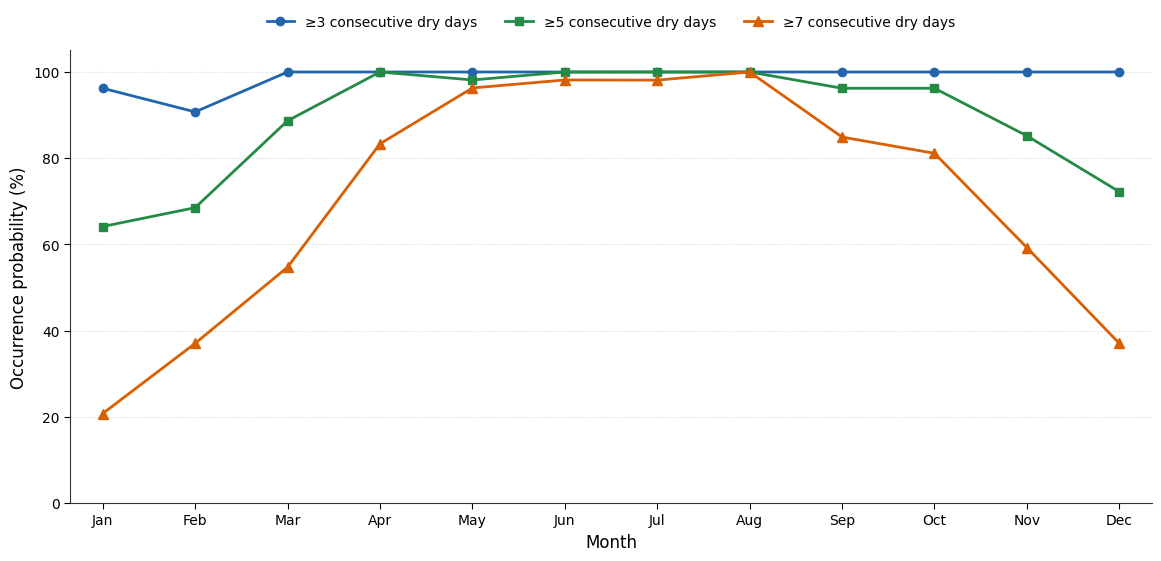

MONTHLY OCCURRENCE OF DRY-WEATHER WINDOWS
BOTUCATU, BRAZIL | 1971-2024
Complete calendar months: 641


,Month,At_least_3_days_percent,At_least_5_days_percent,At_least_7_days_percent
0,January,96.23,64.15,20.75
1,February,90.74,68.52,37.04
2,March,100.00,88.68,54.72
3,April,100.00,100.00,83.33
4,May,100.00,98.15,96.30
5,June,100.00,100.00,98.15
6,July,100.00,100.00,98.11
7,August,100.00,100.00,100.00
8,September,100.00,96.23,84.91
9,October,100.00,96.23,81.13



Output files:
Figure_Monthly_Dry_Weather_Window_Probabilities_1971_2024.png
Figure_Monthly_Dry_Weather_Window_Probabilities_1971_2024.pdf
Figure_Monthly_Dry_Weather_Window_Probabilities_1971_2024.svg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# FIGURE - MONTHLY OCCURRENCE OF DRY-WEATHER WINDOWS
# Methodology: Consecutive dry-weather windows
#
# Study area: Botucatu, Sao Paulo, Brazil
# Study period: 1971-2024
#
# Purpose:
# Visualize the historical occurrence probability
# of at least one consecutive dry-weather episode
# lasting 3, 5, or 7 days within each calendar month.
#
# Dry day: daily precipitation < 1.0 mm.
#
# Probabilities were previously calculated using
# 641 complete calendar months (Step 14).
#
# No additional statistical calculations are performed.
#
# Input:
# tabela_frequencia_janelas (Step 14)
# or the Step 14 Excel workbook.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. LOAD MONTHLY DRY-WINDOW FREQUENCIES
# ------------------------------------------------------------

if "tabela_frequencia_janelas" in globals():

    frequency_data = (
        tabela_frequencia_janelas.copy()
    )

else:

    print(
        "Upload the Step 14 Excel workbook."
    )

    uploaded = files.upload()

    excel_files = [
        name for name in uploaded
        if name.lower().endswith(".xlsx")
    ]

    if not excel_files:
        raise ValueError(
            "No Excel workbook was uploaded."
        )

    frequency_data = pd.read_excel(
        excel_files[0],
        sheet_name="Monthly_Frequency"
    )

# ------------------------------------------------------------
# 2. ORGANIZE CALENDAR MONTHS
# ------------------------------------------------------------

month_order = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

frequency_data["Month"] = pd.Categorical(
    frequency_data["Month"],
    categories=month_order,
    ordered=True
)

frequency_data = (
    frequency_data
    .sort_values("Month")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. VERIFY THE HISTORICAL FREQUENCIES
# ------------------------------------------------------------

required_columns = [
    "At_least_3_days_percent",
    "At_least_5_days_percent",
    "At_least_7_days_percent"
]

assert len(frequency_data) == 12

assert frequency_data["Month"].notna().all()

assert frequency_data[
    required_columns
].notna().all().all()

for column in required_columns:

    assert frequency_data[
        column
    ].between(0, 100).all()

# Longer dry windows cannot occur more frequently
# than shorter windows within the same month.

assert (
    frequency_data["At_least_7_days_percent"]
    <= frequency_data["At_least_5_days_percent"]
).all()

assert (
    frequency_data["At_least_5_days_percent"]
    <= frequency_data["At_least_3_days_percent"]
).all()

# ------------------------------------------------------------
# 4. PREPARE DATA FOR PLOTTING
# ------------------------------------------------------------

x = np.arange(12)

p3 = frequency_data[
    "At_least_3_days_percent"
].to_numpy(dtype=float)

p5 = frequency_data[
    "At_least_5_days_percent"
].to_numpy(dtype=float)

p7 = frequency_data[
    "At_least_7_days_percent"
].to_numpy(dtype=float)

# ------------------------------------------------------------
# 5. CONFIGURE PUBLICATION-QUALITY FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(
    figsize=(11.5, 5.5),
    constrained_layout=True
)

# ------------------------------------------------------------
# 6. PLOT DRY WINDOWS OF AT LEAST 3 DAYS
# ------------------------------------------------------------

ax.plot(
    x,
    p3,
    color="#2166AC",
    marker="o",
    markersize=6,
    markeredgecolor="#2166AC",
    linewidth=2.0,
    label="≥3 consecutive dry days"
)

# ------------------------------------------------------------
# 7. PLOT DRY WINDOWS OF AT LEAST 5 DAYS
# ------------------------------------------------------------

ax.plot(
    x,
    p5,
    color="#238B45",
    marker="s",
    markersize=6,
    markeredgecolor="#238B45",
    linewidth=2.0,
    label="≥5 consecutive dry days"
)

# ------------------------------------------------------------
# 8. PLOT DRY WINDOWS OF AT LEAST 7 DAYS
# ------------------------------------------------------------

ax.plot(
    x,
    p7,
    color="#D95F02",
    marker="^",
    markersize=7,
    markeredgecolor="#D95F02",
    linewidth=2.0,
    label="≥7 consecutive dry days"
)

# ------------------------------------------------------------
# 9. FORMAT AXES
# ------------------------------------------------------------

ax.set_xlabel("Month")

ax.set_ylabel(
    "Occurrence probability (%)"
)

ax.set_xticks(x)

ax.set_xticklabels(
    month_labels
)

ax.set_xlim(-0.35, 11.35)

ax.set_ylim(0, 105)

ax.set_yticks(
    np.arange(0, 101, 20)
)

# ------------------------------------------------------------
# 10. FORMAT GRID AND BORDERS
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.8,
    color="#BDBDBD",
    alpha=0.6
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#333333")

ax.spines["bottom"].set_color("#333333")

ax.tick_params(
    axis="both",
    direction="out",
    length=4
)

# ------------------------------------------------------------
# 11. POSITION THE LEGEND ABOVE THE GRAPH
# ------------------------------------------------------------

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    columnspacing=2.0,
    handlelength=2.0
)

# ------------------------------------------------------------
# 12. EXPORT THE FIGURE
# ------------------------------------------------------------

figure_name = (
    "Figure_Monthly_Dry_Weather_"
    "Window_Probabilities_1971_2024"
)

fig.savefig(
    figure_name + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_name + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 13. DISPLAY HISTORICAL FREQUENCIES
# ------------------------------------------------------------

print("=" * 70)
print("MONTHLY OCCURRENCE OF DRY-WEATHER WINDOWS")
print("BOTUCATU, BRAZIL | 1971-2024")
print("=" * 70)

print("Complete calendar months: 641")

display(
    frequency_data.round(2)
)

print("\nOutput files:")

print(figure_name + ".png")
print(figure_name + ".pdf")
print(figure_name + ".svg")

# ------------------------------------------------------------
# 14. DOWNLOAD THE HIGH-RESOLUTION FIGURE
# ------------------------------------------------------------

files.download(
    figure_name + ".png"
)
